<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-05/lab-029-physics-j1j2.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 029
<hr/>

# Lab 029 — The J1–J2 Ising model

Labs 018–020 use the $J_1$–$J_2$ Ising model as a test bed: Lab 018 generates Monte Carlo snapshots, and Labs 019 and 020 ask unsupervised algorithms
to find its phases without labels. To judge what an algorithm finds we must know the answer, and this notebook supplies it. It contains **no machine learning**; it
collects the physics of the model, derived step by step and checked numerically.

The model consists of Ising spins $s_i=\pm1$ on a square lattice, with a ferromagnetic coupling $J_1$ between nearest neighbours and an
antiferromagnetic coupling $J_2$ between diagonal neighbours. The two couplings cannot be satisfied at the same time — the model is
**frustrated** — and their ratio $g=J_2/J_1$ decides which order wins.

The table below lists the sections, what each of them establishes, and the method used to establish it.

| section | content | method |
|---|---|---|
| 1 | statistical mechanics in brief; frustration of a triangle of bonds | SymPy, enumeration |
| 2 | the model, its symmetries, order parameters; the Ashkin–Teller structure of the stripe order | exact checks on configurations |
| 3 | ground states for every $g$, the level crossing at $g=1/2$, the ground-state degeneracy $2^{L}+2^{M}-2$ at $g=1/2$ | SymPy, enumeration, min-plus transfer matrix |
| 4 | the energy cost of domain walls, which vanishes at $g=1/2$ | SymPy, constructed configurations |
| 5 | exact limits: Onsager at $g=0$, two decoupled Ising lattices for $g\to\infty$ | SymPy, gauge transformation |
| 6 | mean-field theory and its failure | SymPy, self-consistency, Fourier analysis |
| 7 | Monte Carlo in JAX and the static structure factor $S(\boldsymbol k)$ | Metropolis on four sublattices |
| 8 | exact transfer matrices of infinite strips: free energy, specific heat, residual entropy, $T_c(g)$ | numerical diagonalisation |
| 9 | Binder cumulants and $T_c(g)$ from Monte Carlo | JAX, `vmap` + `lax.scan` |
| 10 | the nature of the transitions in the literature | references |
| 11 | summary, exercises with solutions | |

Throughout we use units with $k_B=1$ and $J_1=1$, so temperatures are measured in units of $J_1$.

> **How to run this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*.
> 2. Run the cells **in order** with **Shift + Enter**; later cells use variables defined earlier.
> 3. Needed packages: `numpy`, `scipy`, `sympy`, `matplotlib`, `jax` — all pre-installed in Colab. No data are downloaded.
> 4. Everything runs on the CPU. The slow cells (transfer matrices of size up to $2^{12}\times2^{12}$ and the Monte Carlo runs of Section 9) print their running time.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"            # run JAX on the CPU only
os.environ["CUDA_VISIBLE_DEVICES"] = ""
import time
import itertools
from functools import partial

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from scipy.linalg import eigh
from scipy.sparse.linalg import eigsh
from scipy.optimize import brentq

import jax
import jax.numpy as jnp
from jax import lax

T_START = time.perf_counter()
print("JAX", jax.__version__, "| devices:", jax.devices())

# UJ colours
UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
blues = LinearSegmentedColormap.from_list("uj_blues", ["#9CC3E6", UJNavy])   # light -> dark: small L -> large L
SPIN_CMAP = ListedColormap(["#FFFFFF", UJNavy])                               # s = -1 white, s = +1 navy
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": UJGray, "axes.titlesize": 11, "axes.titlecolor": UJNavy,
                     "axes.prop_cycle": plt.cycler(color=[UJBlue, DSOrange, UJNavy, UJGray])})

TC_ISING = 2.0 / np.log(1.0 + np.sqrt(2.0))    # Onsager's critical temperature of the square-lattice Ising model (J = 1)
print(f"Onsager: T_c(g = 0) = 2 / ln(1 + sqrt 2) = {TC_ISING:.10f}")

JAX 0.11.0 | devices: [CpuDevice(id=0)]
Onsager: T_c(g = 0) = 2 / ln(1 + sqrt 2) = 2.2691853142


<hr/>
## 1. Statistical mechanics and frustration

Many students of this course come from computer science or mathematics, so we begin by recalling the five objects of statistical
mechanics that the notebook uses — energy, Boltzmann weight, partition function, free energy and order parameter — and then introduce the one
new idea of the model, frustration. Lab 012 develops the same material at length for the ordinary Ising model.

A configuration is a vector $\mathbf s=(s_1,\dots,s_N)\in\{-1,+1\}^N$ of $N$ spins, and a Hamiltonian $H(\mathbf s)$
assigns it an energy. For pair interactions
$$
H(\mathbf s) = -\sum_{i<j}J_{ij}\,s_is_j ,
$$
a bond with $J_{ij}>0$ is **ferromagnetic** (energy $-J_{ij}$ if $s_i=s_j$, $+J_{ij}$ otherwise) and a bond with $J_{ij}<0$ is **antiferromagnetic**.
We call a bond *satisfied* when it has its lower energy.

In thermal equilibrium at temperature $T$ a configuration occurs with the Boltzmann probability
$$
p(\mathbf s) = \frac{e^{-\beta H(\mathbf s)}}{Z},\qquad \beta=\frac1T,\qquad Z(T) = \sum_{\mathbf s}e^{-\beta H(\mathbf s)} .
$$
Here the normalisation $Z$ is the partition function. At low $T$ the low-energy configurations dominate; at high $T$ all $2^N$ configurations become equally likely.

All thermal averages follow from the free energy per spin $f = -\frac{T}{N}\ln Z$: the energy per spin is
$u = \partial(\beta f)/\partial\beta = \langle H\rangle/N$, the specific heat per spin is $c = \partial u/\partial T = (\langle H^2\rangle-\langle H\rangle^2)/(NT^2)$,
and the entropy per spin is $s=(u-f)/T$. A **phase transition** is a temperature at which $f$, in the limit $N\to\infty$, is not an analytic function of $T$.

An ordered phase is recognised by an order parameter, a quantity that is non-zero in it and zero in the disordered (paramagnetic) phase;
for a ferromagnet this is the magnetisation $m = \frac1N\sum_is_i$. Since the Hamiltonian is invariant under $\mathbf s\to-\mathbf s$, $\langle m\rangle=0$
on any finite lattice, and one therefore uses $\langle|m|\rangle$ or $\langle m^2\rangle$. Choosing the order parameter requires knowing what pattern
the spins form, which for our model is the subject of Sections 2–3.

### 1.1 Frustration on a triangle of bonds

On the square lattice with only ferromagnetic bonds all bonds can be satisfied at once, by setting all spins up. A diagonal
antiferromagnetic bond changes this: it closes a triangle of two nearest-neighbour bonds and one diagonal bond, and the three bonds of this triangle cannot all be satisfied.
Take sites $1,2,3$ with $1$–$2$ and $2$–$3$ nearest neighbours and $1$–$3$ diagonal neighbours:
$$
H_\triangle = -J_1(s_1s_2+s_2s_3) + J_2\,s_1s_3 .
$$
Satisfying both $J_1$ bonds requires $s_1=s_2=s_3$; then $s_1s_3=+1$ and the $J_2$ bond is broken. Satisfying the $J_2$ bond requires $s_1=-s_3$, and then
$s_2$ agrees with only one of them.

The sketch below shows three of the eight states of the triangle, with the $J_1$ bonds $1$–$2$ and $2$–$3$ between nearest neighbours and the $J_2$ bond $1$–$3$ on the diagonal. A solid line is a satisfied bond, a dashed purple line with a cross a broken one; a navy disc is $s=+1$ and a white disc with an orange rim $s=-1$, the convention of all sketches in this course. Whatever we do, one bond stays broken: aligning all three spins breaks the diagonal, and turning one end spin to satisfy the diagonal breaks a nearest-neighbour bond.

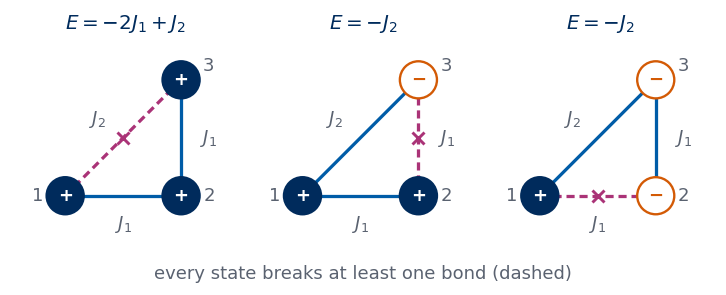

In [ ]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("figures", exist_ok=True)
    for d in ("figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def draw_spin(ax, x, y, s, r=0.26, sign=False, alpha=1.0, fs=10, lw=1.3):
    # one Ising spin at (x, y): navy disc for s = +1, white disc with orange rim for s = -1 (optionally with "+" / "-")
    face, edge, txt = (NAVY, NAVY, "white") if s > 0 else ("white", ORANGE, ORANGE)
    ax.add_patch(mpatches.Circle((x, y), r, fc=face, ec=edge, lw=lw, alpha=alpha, zorder=4))
    if sign:
        ax.text(x, y, "+" if s > 0 else "−", color=txt, ha="center", va="center", alpha=alpha,
                fontsize=fs, fontweight="bold", zorder=5)

def draw_bond(ax, p, q, broken=False, lw=1.5, alpha=1.0, color=None, cross=True):
    # bond between points p and q: solid blue if satisfied, dashed purple with a cross if broken
    c = color or (PURPLE if broken else BLUE)
    ax.plot([p[0], q[0]], [p[1], q[1]], color=c, lw=lw, ls=(0, (2.5, 1.5)) if broken else "-",
            alpha=alpha, solid_capstyle="round", zorder=2)
    if broken and cross:
        ax.plot((p[0] + q[0]) / 2, (p[1] + q[1]) / 2, marker="x", ms=3.5 * lw, mew=lw * 0.9, color=c, alpha=alpha, zorder=3)

def sketch_j1j2_triangle():
    # sites 1 = (0, 0), 2 = (1, 0), 3 = (1, 1): bonds 1-2 and 2-3 are J1 (nearest neighbours), 1-3 is J2 (diagonal)
    pos = {1: (0, 0), 2: (1, 0), 3: (1, 1)}
    bonds = [(1, 2, "J1"), (2, 3, "J1"), (1, 3, "J2")]
    states = [(+1, +1, +1), (+1, +1, -1), (+1, -1, -1)]
    fig, axes = plt.subplots(1, 3, figsize=(5.5, 2.2))
    fig.subplots_adjust(left=0.01, right=0.99, bottom=0.12, top=0.86, wspace=0.05)
    for ax, st in zip(axes, states):
        s = dict(zip((1, 2, 3), st))
        for a, b, kind in bonds:
            # J1 is satisfied by parallel spins, J2 (antiferromagnetic) by antiparallel spins
            satisfied = s[a] * s[b] > 0 if kind == "J1" else s[a] * s[b] < 0
            draw_bond(ax, pos[a], pos[b], broken=not satisfied, lw=1.8)
            mx, my = (pos[a][0] + pos[b][0]) / 2, (pos[a][1] + pos[b][1]) / 2
            off = {(1, 2): (0, -0.24), (2, 3): (0.24, 0), (1, 3): (-0.22, 0.16)}[(a, b)]
            ax.text(mx + off[0], my + off[1], "$J_1$" if kind == "J1" else "$J_2$", fontsize=10, ha="center", va="center",
                    color=GRAY)
        for k, (x, y) in pos.items():
            draw_spin(ax, x, y, s[k], r=0.16, sign=True, fs=10)
            ax.text(x + (-0.24 if k == 1 else 0.24), y + (0.0 if k != 3 else 0.12), f"{k}", fontsize=10, color=GRAY, ha="center", va="center")
        E = -(st[0] * st[1] + st[1] * st[2])                            # J1 part, in units of J1 ...
        E2 = st[0] * st[2]                                               # ... plus J2 part
        e_txt = rf"$E={'-' if E < 0 else '+'}{abs(E)}J_1{'+' if E2 > 0 else '-'}J_2$" if E != 0 else rf"$E={'+' if E2 > 0 else '-'}J_2$"
        ax.set_title(e_txt, fontsize=11, color=NAVY)
        ax.set_xlim(-0.45, 1.5); ax.set_ylim(-0.45, 1.35); ax.set_aspect("equal"); ax.axis("off")
    fig.text(0.5, 0.02, "every state breaks at least one bond (dashed)", ha="center", fontsize=10, color=GRAY)
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_j1j2_triangle()
save_sketch(fig, "sketch_j1j2_triangle.png")
plt.show()


The same reasoning gives a general criterion. Going around a closed loop of bonds, multiply the signs of the couplings (ferromagnetic $+$,
antiferromagnetic $-$); if the product is negative, at least one bond on the loop is broken in every configuration. To see this, note that the product of the bond
variables $s_is_j$ around a loop is $\prod_i s_i^2=+1$; a satisfied bond has $s_is_j=\operatorname{sign}J_{ij}$, so if all bonds were satisfied the product of signs
would be $+1$. Our triangle has signs $(+,+,-)$, so it is frustrated.

To make this concrete, the next cell lists the states of the triangle with SymPy, writes their energies as symbolic functions of $J_1,J_2$, and counts the broken bonds.
Look for the minimum number of broken bonds over all eight states: if the criterion is right, it cannot be zero.

In [2]:
J1s, J2s, gs_ = sp.symbols("J_1 J_2 g", positive=True)

def H_triangle(s1, s2, s3):
    # energy of the triangle: two nearest-neighbour bonds (1-2, 2-3) and one diagonal bond (1-3)
    return -J1s * (s1 * s2 + s2 * s3) + J2s * s1 * s3

print("  s1 s2 s3   energy              broken bonds")
for s in itertools.product([1, -1], repeat=3):
    if s[0] == -1:                       # the global flip gives the same energy: list one state of each pair
        continue
    broken = int(s[0] * s[1] < 0) + int(s[1] * s[2] < 0) + int(s[0] * s[2] > 0)
    print(f"  {s[0]:+d} {s[1]:+d} {s[2]:+d}   {str(H_triangle(*s)):18s}  {broken}")

# the product of coupling signs around the loop (+J1, +J1, -J2) is negative: at least one broken bond in every state
min_broken = min(int(s[0]*s[1] < 0) + int(s[1]*s[2] < 0) + int(s[0]*s[2] > 0) for s in itertools.product([1, -1], repeat=3))
assert min_broken == 1
print(f"minimum number of broken bonds over all 8 states: {min_broken}")

  s1 s2 s3   energy              broken bonds
  +1 +1 +1   -2*J_1 + J_2        1
  +1 +1 -1   -J_2                1
  +1 -1 +1   2*J_1 + J_2         3
  +1 -1 -1   -J_2                1
minimum number of broken bonds over all 8 states: 1


The output confirms the criterion: every state of the triangle breaks at least one bond, and two kinds of state compete: $(+,+,+)$ with energy $-2J_1+J_2$
(the diagonal bond broken) and $(+,+,-)$, $(+,-,-)$ with energy $-J_2$ (one nearest-neighbour bond broken). For an isolated triangle the first wins
when $-2J_1+J_2<-J_2$, i.e. $J_2<J_1$. On the lattice every nearest-neighbour bond is shared by several triangles, so the balance point moves;
Section 3 shows that it lies at $J_2=J_1/2$. Frustration does not by itself say which state wins. It says that *some* bonds must be broken, and
the question becomes which compromise has the lowest energy and how many compromises of equal energy exist.

<hr/>
## 2. Hamiltonian, symmetries and order parameters

Before computing anything we need the symmetries of the model. They decide which ordered states are degenerate, which order parameter measures them and — through the symmetry group
of the order parameter — which universality class a continuous transition can belong to. We establish them once here and use them in every later section.

The spins $s_{x,y}=\pm1$ live on an $L\times L$ square lattice with periodic boundaries (a torus), $x,y\in\{0,\dots,L-1\}$, $N=L^2$, and the Hamiltonian is
$$
\begin{aligned}
H(\mathbf s) &= -J_1\sum_{\langle i,j\rangle}s_is_j + J_2\sum_{\langle\langle i,j\rangle\rangle}s_is_j\\
&= -J_1\,B_1(\mathbf s) + J_2\,B_2(\mathbf s),\qquad g=\frac{J_2}{J_1}\ge0 ,
\end{aligned}
$$
which is the convention of Lab 018. Here $\langle i,j\rangle$ runs over the $2N$ nearest-neighbour bonds (horizontal $(x,y)$–$(x+1,y)$ and vertical
$(x,y)$–$(x,y+1)$), $\langle\langle i,j\rangle\rangle$ over the $2N$ diagonal bonds ($(x,y)$–$(x+1,y+1)$ and $(x,y)$–$(x+1,y-1)$), and
$B_1=\sum_{\langle ij\rangle}s_is_j$, $B_2=\sum_{\langle\langle ij\rangle\rangle}s_is_j$ are integers in $[-2N,2N]$. With $J_1=1$ the energy is $H=-B_1+gB_2$, so
computing $B_1,B_2$ once gives the energy for every $g$. We also split $B_1=B_1^{x}+B_1^{y}$ into horizontal and vertical bonds.

The figure below shows the lattice and its two kinds of bonds. Every site $i$ has four nearest neighbours, coupled by $J_1$ (solid blue), and four diagonal neighbours, coupled by $J_2$ (dashed green). The ferromagnetic $J_1$ favours parallel nearest neighbours, the antiferromagnetic $J_2$ favours antiparallel diagonal neighbours, and no configuration satisfies both; the ratio $g=J_2/J_1$ decides which compromise has the lowest energy.

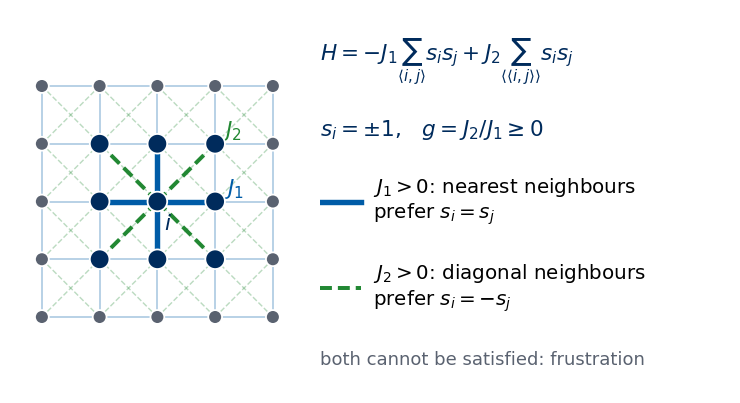

In [ ]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("figures", exist_ok=True)
    for d in ("figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def draw_spin(ax, x, y, s, r=0.26, sign=False, alpha=1.0, fs=10, lw=1.3):
    # one Ising spin at (x, y): navy disc for s = +1, white disc with orange rim for s = -1 (optionally with "+" / "-")
    face, edge, txt = (NAVY, NAVY, "white") if s > 0 else ("white", ORANGE, ORANGE)
    ax.add_patch(mpatches.Circle((x, y), r, fc=face, ec=edge, lw=lw, alpha=alpha, zorder=4))
    if sign:
        ax.text(x, y, "+" if s > 0 else "−", color=txt, ha="center", va="center", alpha=alpha,
                fontsize=fs, fontweight="bold", zorder=5)

def draw_bond(ax, p, q, broken=False, lw=1.5, alpha=1.0, color=None, cross=True):
    # bond between points p and q: solid blue if satisfied, dashed purple with a cross if broken
    c = color or (PURPLE if broken else BLUE)
    ax.plot([p[0], q[0]], [p[1], q[1]], color=c, lw=lw, ls=(0, (2.5, 1.5)) if broken else "-",
            alpha=alpha, solid_capstyle="round", zorder=2)
    if broken and cross:
        ax.plot((p[0] + q[0]) / 2, (p[1] + q[1]) / 2, marker="x", ms=3.5 * lw, mew=lw * 0.9, color=c, alpha=alpha, zorder=3)

def sketch_j1j2_model():
    L = 5
    fig = plt.figure(figsize=(5.5, 2.9))
    ax = fig.add_axes([0.0, 0.0, 0.42, 1.0]); tx = fig.add_axes([0.43, 0.0, 0.57, 1.0]); tx.axis("off")
    # all bonds of a 5 x 5 patch: J1 (nearest neighbours) solid blue, J2 (diagonals) dashed green; drawn faint
    for y in range(L):
        for x in range(L):
            if x + 1 < L: ax.plot([x, x + 1], [y, y], color=BLUE, lw=1, alpha=0.3)
            if y + 1 < L: ax.plot([x, x], [y, y + 1], color=BLUE, lw=1, alpha=0.3)
            if x + 1 < L and y + 1 < L:
                ax.plot([x, x + 1], [y, y + 1], color=GREEN, lw=0.8, ls="--", alpha=0.3)
                ax.plot([x, x + 1], [y + 1, y], color=GREEN, lw=0.8, ls="--", alpha=0.3)
    # the eight bonds of the central site i, drawn strongly
    c = (2, 2)
    for dx, dy in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
        ax.plot([c[0], c[0] + dx], [c[1], c[1] + dy], color=BLUE, lw=3, solid_capstyle="round", zorder=2)
    for dx, dy in [(1, 1), (-1, 1), (1, -1), (-1, -1)]:
        ax.plot([c[0], c[0] + dx], [c[1], c[1] + dy], color=GREEN, lw=2.2, ls=(0, (3, 1.5)), zorder=2)
    for y in range(L):
        for x in range(L):
            hot = abs(x - c[0]) <= 1 and abs(y - c[1]) <= 1
            ax.add_patch(mpatches.Circle((x, y), 0.17 if hot else 0.12, fc=NAVY if hot else GRAY, ec="white", lw=1, zorder=4))
    ax.text(c[0] + 0.12, c[1] - 0.22, "$i$", fontsize=12, color=NAVY, ha="left", va="top", zorder=5)
    ax.text(c[0] + 1.15, c[1] + 0.12, "$J_1$", fontsize=12, color=BLUE, ha="left")
    ax.text(c[0] + 1.12, c[1] + 1.12, "$J_2$", fontsize=12, color=GREEN, ha="left")
    ax.set_xlim(-0.5, L - 0.3); ax.set_ylim(-0.6, L - 0.4); ax.set_aspect("equal"); ax.axis("off")

    tx.set_xlim(0, 1); tx.set_ylim(0, 1)
    tx.text(0.0, 0.87, r"$H=-J_1\sum_{\langle i,j\rangle}s_is_j+J_2\sum_{\langle\langle i,j\rangle\rangle}s_is_j$",
            fontsize=12, color=NAVY, va="center")
    tx.text(0.0, 0.69, r"$s_i=\pm1$,   $g=J_2/J_1\geq 0$", fontsize=12, color=NAVY, va="center")
    tx.plot([0.0, 0.1], [0.5, 0.5], color=BLUE, lw=3)
    tx.text(0.13, 0.5, r"$J_1>0$: nearest neighbours" "\n" r"prefer $s_i=s_j$", fontsize=11, va="center")
    tx.plot([0.0, 0.1], [0.27, 0.27], color=GREEN, lw=2.2, ls=(0, (3, 1.5)))
    tx.text(0.13, 0.27, r"$J_2>0$: diagonal neighbours" "\n" r"prefer $s_i=-s_j$", fontsize=11, va="center")
    tx.text(0.0, 0.08, "both cannot be satisfied: frustration", fontsize=10, color=GRAY, va="center")
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_j1j2_model()
save_sketch(fig, "sketch_j1j2_card.png")
plt.show()


A symmetry is a map of configurations that leaves $H$ unchanged, and the model has two kinds of them. The global spin flip $\mathbf s\to-\mathbf s$
leaves every product $s_is_j$ unchanged; this is the $\mathbb Z_2$ symmetry of every Ising model. The lattice symmetries — translations by one site,
rotation by $90^\circ$ and reflections — map nearest-neighbour bonds onto nearest-neighbour bonds and diagonal bonds onto diagonal bonds.

Two further transformations change the signs of a subset of spins. They are not symmetries of $H$ but gauge transformations, which map it onto another
Hamiltonian, and both will be useful later. The *checkerboard gauge* $s_{x,y}\to(-1)^{x+y}s_{x,y}$ changes the sign of every nearest-neighbour product,
because nearest neighbours have opposite parity of $x+y$, while diagonal neighbours have equal parity and their products are unchanged: $B_1\to-B_1$, $B_2\to B_2$.
Consequently **the model with antiferromagnetic $J_1$ has exactly the same thermodynamics** as ours, with Néel order mapped onto ferromagnetic order.
Several papers in Section 10 use $J_1<0$ (nearest-neighbour antiferromagnet) or write $J_1<0$ for the ferromagnet; their phase diagrams apply here without change.
The *column gauge* $s_{x,y}\to(-1)^{x}s_{x,y}$ acts differently: horizontal and diagonal bonds join different $x$ parities and change sign, vertical bonds do not,
so $B_1^x\to-B_1^x$, $B_1^y\to B_1^y$, $B_2\to-B_2$. Section 5 uses it for the limit $g\to\infty$.

The cell below verifies all of these statements on random configurations; every line of its output should read `True`.

In [3]:
def bond_sums(s):
    # s: (..., L, L) array of +-1; axis -2 is x, axis -1 is y; periodic boundaries.
    # Returns (B1x, B1y, B2): sums of s_i s_j over horizontal, vertical and diagonal bonds (each bond counted once), integer arrays of shape (...).
    s = np.asarray(s, dtype=np.int64)
    ax = (-2, -1)
    b1x = (s * np.roll(s, -1, -2)).sum(ax)                                    # (x,y)-(x+1,y)
    b1y = (s * np.roll(s, -1, -1)).sum(ax)                                    # (x,y)-(x,y+1)
    b2 = (s * np.roll(s, (-1, -1), ax)).sum(ax) + (s * np.roll(s, (-1, 1), ax)).sum(ax)   # (x,y)-(x+1,y+1) and (x,y)-(x+1,y-1)
    return b1x, b1y, b2

def energy(s, g, J1=1.0):
    # H = -J1 B1 + J2 B2 with J2 = g J1; shape (...)
    b1x, b1y, b2 = bond_sums(s)
    return -J1 * (b1x + b1y) + g * J1 * b2

rng = np.random.default_rng(0)
L = 8
S_rand = rng.choice([-1, 1], size=(1000, L, L))                               # 1000 random configurations, shape (1000, 8, 8)
x, y = np.meshgrid(np.arange(L), np.arange(L), indexing="ij")                 # x[i, j] = i, y[i, j] = j
b1x, b1y, b2 = bond_sums(S_rand)
ops = {"global flip": -S_rand,
       "translation x -> x+1": np.roll(S_rand, 1, -2),
       "rotation by 90 degrees": np.rot90(S_rand, 1, axes=(-2, -1)),
       "reflection x -> -x": np.roll(S_rand[..., ::-1, :], 1, -2)}
for name, S2 in ops.items():
    c = bond_sums(S2)
    print(f"{name:24s}: B1 unchanged {np.array_equal(c[0] + c[1], b1x + b1y)},  B2 unchanged {np.array_equal(c[2], b2)}")
c = bond_sums(S_rand * (-1) ** (x + y))
print(f"checkerboard gauge      : B1 -> -B1 {np.array_equal(c[0] + c[1], -(b1x + b1y))},  B2 unchanged {np.array_equal(c[2], b2)}")
c = bond_sums(S_rand * (-1) ** x)
print(f"column gauge            : B1x -> -B1x {np.array_equal(c[0], -b1x)},  B1y unchanged {np.array_equal(c[1], b1y)},  B2 -> -B2 {np.array_equal(c[2], -b2)}")

global flip             : B1 unchanged True,  B2 unchanged True
translation x -> x+1    : B1 unchanged True,  B2 unchanged True
rotation by 90 degrees  : B1 unchanged True,  B2 unchanged True
reflection x -> -x      : B1 unchanged True,  B2 unchanged True
checkerboard gauge      : B1 -> -B1 True,  B2 unchanged True
column gauge            : B1x -> -B1x True,  B1y unchanged True,  B2 -> -B2 True


### 2.1 Stripe order parameter and its symmetry group

Periodic patterns of spins are described by their Fourier components
$$
\begin{aligned}
m_{\boldsymbol k}(\mathbf s) &= \frac1N\sum_{\boldsymbol r}s_{\boldsymbol r}\,e^{i\boldsymbol k\cdot\boldsymbol r},\\
\boldsymbol r&=(x,y),\quad \boldsymbol k\in\Big\{\tfrac{2\pi}{L}(n_x,n_y)\Big\}.
\end{aligned}
$$
Section 3 derives three candidate orders as ground states; the table lists their patterns, wave vectors and order parameters.

| order | pattern $s_{x,y}$ | wave vector | order parameter |
|---|---|---|---|
| ferromagnet | $\pm1$ | $(0,0)$ | $m = m_{(0,0)}$ |
| stripes | $\pm(-1)^x$ (vertical) or $\pm(-1)^y$ (horizontal) | $(\pi,0)$, $(0,\pi)$ | $m_{\rm str}=\sqrt{m_x^2+m_y^2}$, $\ m_x\equiv m_{(\pi,0)},\ m_y\equiv m_{(0,\pi)}$ |
| Néel | $\pm(-1)^{x+y}$ | $(\pi,\pi)$ | $m_{(\pi,\pi)}$ |

For $\boldsymbol k$ with components $0$ or $\pi$, $e^{i\boldsymbol k\cdot\boldsymbol r}=\pm1$ and $m_{\boldsymbol k}$ is real.

The stripe phase has four ground states, two orientations times the global flip. In the plane $(m_x,m_y)$ they sit at
$(\pm1,0)$ (vertical stripes) and $(0,\pm1)$ (horizontal stripes), whereas the ferromagnet has only two states, $m=\pm1$, on a line.

The lattice symmetries act on the stripe order parameter in a simple way. A translation $x\to x+1$ changes the sign of $(-1)^{x}$, so
$(m_x,m_y)\to(-m_x,m_y)$, and a translation in $y$ gives $(m_x,-m_y)$. A rotation by $90^\circ$, $(x,y)\to(-y,x)$, turns the factor $(-1)^x$
into $(-1)^y$, so $(m_x,m_y)\to(m_y,m_x)$. The global flip sends $(m_x,m_y)\to(-m_x,-m_y)$. A sign change of one component together with the
exchange of the two components generate the eight symmetries of a square, the dihedral group $D_4$, while the ferromagnetic order parameter
sees only $\mathbb Z_2$ ($m\to-m$).

This difference matters. An order parameter with two components and the
symmetry of a square is exactly that of the **Ashkin–Teller model** [Ashkin & Teller 1943], two Ising spins $\sigma_i,\tau_i$ per site coupled by
$-K_2(\sigma_i\sigma_j+\tau_i\tau_j)-K_4\,\sigma_i\sigma_j\tau_i\tau_j$. The four stripe states correspond to the four values of $(\sigma,\tau)$; one possible identification is
$\sigma=\operatorname{sign}(m_x+m_y)$, $\tau=\operatorname{sign}(m_x-m_y)$. This is why the stripe transition, unlike the ferromagnetic one, *can* belong to the
Ashkin–Teller class, whose critical exponents vary continuously along a line [Jin, Sen, Sandvik 2012]. Section 5 shows the same structure from the
$g\to\infty$ limit, where $\sigma$ and $\tau$ become the magnetisations of two decoupled sublattices.

The cell below applies the lattice operations to the four stripe states (labelled V$\pm$ and H$\pm$ for vertical and horizontal stripes of either sign),
prints where each state is sent, and generates the group from two of its elements. The first line also confirms that the four states have the same energy.

In [4]:
def order_params(s):
    # s: (..., L, L) -> dict of m, m_x = m_(pi,0), m_y = m_(0,pi), m_(pi,pi), each of shape (...)
    L = s.shape[-1]
    ph = (-1.0) ** np.arange(L)
    s = np.asarray(s, dtype=float)
    return {"m": s.mean((-2, -1)),
            "mx": (s * ph[:, None]).mean((-2, -1)),
            "my": (s * ph[None, :]).mean((-2, -1)),
            "mpp": (s * ph[:, None] * ph[None, :]).mean((-2, -1))}

L = 8
x, y = np.meshgrid(np.arange(L), np.arange(L), indexing="ij")
stripes = {"V+": (-1) ** x, "V-": -(-1) ** x, "H+": (-1) ** y, "H-": -(-1) ** y}
lattice_ops = {"translate x": lambda s: np.roll(s, 1, 0), "translate y": lambda s: np.roll(s, 1, 1),
               "rotate 90":   lambda s: np.rot90(s),    "global flip": lambda s: -s}

def label(s):
    # name of the stripe state with the same (m_x, m_y)
    o = order_params(s)
    for k, v in stripes.items():
        ov = order_params(v)
        if np.isclose(o["mx"], ov["mx"]) and np.isclose(o["my"], ov["my"]):
            return k

print("energy per spin of the four stripe states at g = 0.7:", [float(energy(v, 0.7)) / L**2 for v in stripes.values()])
print("\n operation     " + "   ".join(f"{k}->" for k in stripes))
for name, op in lattice_ops.items():
    print(f" {name:12s}  " + "   ".join(f"{label(op(v)):>4s}" for v in stripes.values()))

# the action on (m_x, m_y) as 2x2 matrices, and the group they generate
R = np.array([[0, 1], [1, 0]])        # rotation: exchange m_x and m_y
Tx = np.array([[-1, 0], [0, 1]])      # translation in x: m_x -> -m_x
group = {R.tobytes(): R, Tx.tobytes(): Tx}
while True:
    new = {(a @ b).tobytes(): a @ b for a in group.values() for b in group.values()}
    if new.keys() <= group.keys():
        break
    group.update(new)
print(f"\nnumber of distinct 2x2 matrices generated by 'rotate' and 'translate x': {len(group)} (the symmetry group of a square, D4, has 8)")

energy per spin of the four stripe states at g = 0.7: [-1.4, -1.4, -1.4, -1.4]

 operation     V+->   V-->   H+->   H-->
 translate x     V-     V+     H+     H-
 translate y     V+     V-     H-     H+
 rotate 90       H+     H-     V-     V+
 global flip     V-     V+     H-     H+

number of distinct 2x2 matrices generated by 'rotate' and 'translate x': 8 (the symmetry group of a square, D4, has 8)


The table reproduces the action derived above, and the two generators produce exactly eight distinct matrices. To summarise this section:
the Hamiltonian has the global $\mathbb Z_2$ flip and the lattice symmetries. Ferromagnetic order breaks only $\mathbb Z_2$ (two states),
whereas stripe order breaks $\mathbb Z_2$ **and** the $90^\circ$ rotation (four states), and its two-component order parameter transforms under the eight-element
group $D_4$, as in the Ashkin–Teller model. The checkerboard gauge, finally, shows that the sign of $J_1$ is irrelevant for thermodynamics.

The schematic below shows idealised configurations of the phases on an $8\times8$ lattice, with both order parameters printed above each panel. In the ferromagnet nearly all spins point the same way and $m$ is close to $1$, while $m_{\rm str}$ is close to zero. In the two stripe states whole columns or whole rows alternate in sign; their magnetisation is close to zero, but $m_{\rm str}$ is close to $1$, carried by the component $m_x$ for vertical and $m_y$ for horizontal stripes. A few thermally flipped spins reduce the order parameters slightly below $1$. In the paramagnet, the disordered phase at high temperature, both order parameters are small and vanish for $N\to\infty$; on $64$ random spins $m_{\rm str}$ is not exactly zero. The Néel pattern, the antiferromagnetic order of nearest neighbours, does not occur as a phase of our model, since it breaks every $J_1$ bond.

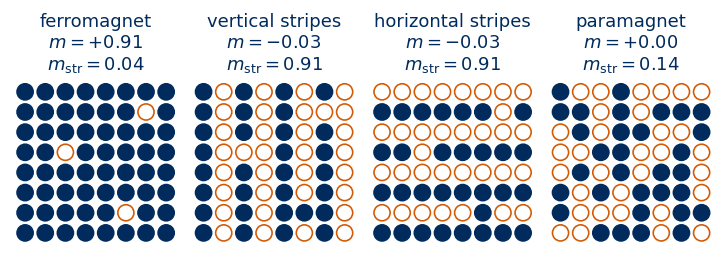

In [ ]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("figures", exist_ok=True)
    for d in ("figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def draw_spin(ax, x, y, s, r=0.26, sign=False, alpha=1.0, fs=10, lw=1.3):
    # one Ising spin at (x, y): navy disc for s = +1, white disc with orange rim for s = -1 (optionally with "+" / "-")
    face, edge, txt = (NAVY, NAVY, "white") if s > 0 else ("white", ORANGE, ORANGE)
    ax.add_patch(mpatches.Circle((x, y), r, fc=face, ec=edge, lw=lw, alpha=alpha, zorder=4))
    if sign:
        ax.text(x, y, "+" if s > 0 else "−", color=txt, ha="center", va="center", alpha=alpha,
                fontsize=fs, fontweight="bold", zorder=5)

def draw_bond(ax, p, q, broken=False, lw=1.5, alpha=1.0, color=None, cross=True):
    # bond between points p and q: solid blue if satisfied, dashed purple with a cross if broken
    c = color or (PURPLE if broken else BLUE)
    ax.plot([p[0], q[0]], [p[1], q[1]], color=c, lw=lw, ls=(0, (2.5, 1.5)) if broken else "-",
            alpha=alpha, solid_capstyle="round", zorder=2)
    if broken and cross:
        ax.plot((p[0] + q[0]) / 2, (p[1] + q[1]) / 2, marker="x", ms=3.5 * lw, mew=lw * 0.9, color=c, alpha=alpha, zorder=3)

def sketch_j1j2_phases_configs():
    L = 8
    y, x = np.indices((L, L))
    rng = np.random.default_rng(5)                                  # fixed seed: the same schematic every time
    flips = np.ones((L, L), int); flips[[1, 4, 6], [5, 2, 6]] = -1  # a few thermally flipped spins
    panels = [(flips, "ferromagnet"), ((-1) ** x * flips, "vertical stripes"),
              ((-1) ** y * flips, "horizontal stripes"),
              (rng.permutation(np.repeat([1, -1], L * L // 2)).reshape(L, L), "paramagnet")]
    fig, axes = plt.subplots(1, 4, figsize=(5.5, 2.2))
    fig.subplots_adjust(left=0.01, right=0.99, bottom=0.01, top=0.72, wspace=0.08)
    for ax, (S, title) in zip(axes, panels):
        for (yy, xx), s in np.ndenumerate(S):
            draw_spin(ax, xx, yy, s, r=0.4, lw=0.9)
        m = S.mean()                                                 # ferromagnetic order parameter
        mx, my = (S * (-1) ** x).mean(), (S * (-1) ** y).mean()      # stripe components m_(pi,0), m_(0,pi)
        ax.set_title(f"{title}\n$m={m:+.2f}$\n" + rf"$m_{{\rm str}}={np.hypot(mx, my):.2f}$", fontsize=10, color=NAVY)
        ax.set_xlim(-0.6, L - 0.4); ax.set_ylim(-0.6, L - 0.4); ax.set_aspect("equal"); ax.axis("off")
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_j1j2_phases_configs()
save_sketch(fig, "sketch_j1j2_phase_configs.png")
plt.show()


<hr/>
## 3. Ground states

We now turn to the lowest temperatures. At $T=0$ the Boltzmann weight selects the configurations of minimum energy. They tell us which orders can appear at low temperature,
and their number, the degeneracy, tells us how strongly thermal fluctuations will compete with them. For this model the answer changes
qualitatively at one value of $g$.

### 3.1 Bond counting

We start by comparing the energies of the three simple periodic patterns. Every spin has 4 nearest neighbours and 4 diagonal neighbours; each bond is shared by two spins, so there are 2 nearest-neighbour bonds and
2 diagonal bonds **per spin**, so for a periodic pattern the energy per spin is the average over one unit cell of
$-J_1(s_{x,y}s_{x+1,y}+s_{x,y}s_{x,y+1})+J_2(s_{x,y}s_{x+1,y+1}+s_{x,y}s_{x+1,y-1})$.

For the ferromagnet (all $+1$) both nearest-neighbour products and both diagonal products are $+1$, so both diagonal bonds are broken and
$E/N=-2J_1+2J_2$. For the stripes $(-1)^x$ the horizontal product is $-1$ and the vertical one $+1$, which cancel, while both diagonal products are $-1$:
$E/N=-2J_2$. For the Néel state $(-1)^{x+y}$ both nearest-neighbour products are $-1$ and both diagonal products $+1$: $E/N=+2J_1+2J_2$.

The figure below draws the four patterns on a $4\times4$ patch with every bond marked: thick lines are $J_1$ bonds, thin lines $J_2$ bonds, solid when satisfied and dashed purple when broken. In the ferromagnet every $J_1$ bond is satisfied and every diagonal broken. In the stripes half of the $J_1$ bonds are broken but every diagonal is satisfied. The Néel state, drawn for contrast, breaks every bond and is never a ground state for $J_1>0$; it is the ground state of the antiferromagnetic nearest-neighbour model, which the checkerboard gauge of Section 2 maps onto our ferromagnet.

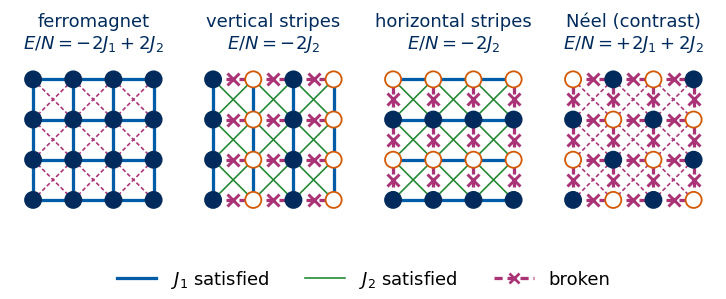

In [ ]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("figures", exist_ok=True)
    for d in ("figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def draw_spin(ax, x, y, s, r=0.26, sign=False, alpha=1.0, fs=10, lw=1.3):
    # one Ising spin at (x, y): navy disc for s = +1, white disc with orange rim for s = -1 (optionally with "+" / "-")
    face, edge, txt = (NAVY, NAVY, "white") if s > 0 else ("white", ORANGE, ORANGE)
    ax.add_patch(mpatches.Circle((x, y), r, fc=face, ec=edge, lw=lw, alpha=alpha, zorder=4))
    if sign:
        ax.text(x, y, "+" if s > 0 else "−", color=txt, ha="center", va="center", alpha=alpha,
                fontsize=fs, fontweight="bold", zorder=5)

def draw_bond(ax, p, q, broken=False, lw=1.5, alpha=1.0, color=None, cross=True):
    # bond between points p and q: solid blue if satisfied, dashed purple with a cross if broken
    c = color or (PURPLE if broken else BLUE)
    ax.plot([p[0], q[0]], [p[1], q[1]], color=c, lw=lw, ls=(0, (2.5, 1.5)) if broken else "-",
            alpha=alpha, solid_capstyle="round", zorder=2)
    if broken and cross:
        ax.plot((p[0] + q[0]) / 2, (p[1] + q[1]) / 2, marker="x", ms=3.5 * lw, mew=lw * 0.9, color=c, alpha=alpha, zorder=3)

def draw_j1j2_patch(ax, S, mark_bonds=True):
    # spins S[y, x] of an open patch; J1 bonds thick (satisfied if parallel), J2 diagonals thin (satisfied if antiparallel)
    ny, nx = S.shape
    if mark_bonds:
        for y in range(ny):
            for x in range(nx):
                for dx, dy in [(1, 0), (0, 1)]:
                    if x + dx < nx and y + dy < ny:
                        draw_bond(ax, (x, y), (x + dx, y + dy), broken=S[y, x] * S[y + dy, x + dx] < 0, lw=1.8)
                for dx, dy in [(1, 1), (1, -1)]:
                    if x + dx < nx and 0 <= y + dy < ny:
                        sat = S[y, x] * S[y + dy, x + dx] < 0
                        draw_bond(ax, (x, y), (x + dx, y + dy), broken=not sat, lw=0.9, color=GREEN if sat else PURPLE, cross=False)
    for (y, x), s in np.ndenumerate(S):
        draw_spin(ax, x, y, s, r=0.2, lw=1)
    ax.set_xlim(-0.5, nx - 0.5); ax.set_ylim(-0.5, ny - 0.5); ax.set_aspect("equal"); ax.axis("off")

def sketch_j1j2_ground_states():
    n = 4
    y, x = np.indices((n, n))
    patterns = [(np.ones((n, n), int), "ferromagnet", r"$-2J_1+2J_2$"),
                ((-1) ** x, "vertical stripes", r"$-2J_2$"),
                ((-1) ** y, "horizontal stripes", r"$-2J_2$"),
                ((-1) ** (x + y), "Néel (contrast)", r"$+2J_1+2J_2$")]
    fig, axes = plt.subplots(1, 4, figsize=(5.5, 2.35))
    fig.subplots_adjust(left=0.01, right=0.99, bottom=0.17, top=0.8, wspace=0.12)
    for ax, (S, name, energy) in zip(axes, patterns):
        draw_j1j2_patch(ax, S)
        ax.set_title(f"{name}\n$E/N=${energy}", fontsize=10, color=NAVY)
    handles = [plt.Line2D([], [], color=BLUE, lw=1.8), plt.Line2D([], [], color=GREEN, lw=0.9),
               plt.Line2D([], [], color=PURPLE, lw=1.8, ls=(0, (2.5, 1.5)), marker="x", ms=6, mew=1.5)]
    fig.legend(handles, ["$J_1$ satisfied", "$J_2$ satisfied", "broken"], loc="lower center", ncol=3, fontsize=10,
               frameon=False, borderaxespad=0.1, handlelength=2.2)
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_j1j2_ground_states()
save_sketch(fig, "sketch_j1j2_ground_states.png")
plt.show()


The ferromagnet and the stripes cross where $-2J_1+2J_2=-2J_2$, i.e. at $g=1/2$. SymPy reproduces the counting on the $2\times2$ unit cell and solves for the crossing; the last lines compare the symbolic energies with
a direct numerical evaluation at three values of $g$.

In [5]:
def energy_per_spin_pattern(P):
    # symbolic energy per spin of a pattern of period 2 in x and y; P(x, y) returns +-1
    e = 0
    for x0, y0 in itertools.product(range(2), repeat=2):
        s = P(x0, y0)
        e += -J1s * (s * P((x0 + 1) % 2, y0) + s * P(x0, (y0 + 1) % 2)) \
             + J2s * (s * P((x0 + 1) % 2, (y0 + 1) % 2) + s * P((x0 + 1) % 2, (y0 - 1) % 2))
    return sp.simplify(e / 4)

patterns_sym = {"ferromagnet": lambda x, y: 1, "stripes": lambda x, y: (-1) ** x, "Neel": lambda x, y: (-1) ** (x + y)}
E_sym = {k: energy_per_spin_pattern(P) for k, P in patterns_sym.items()}
for k, v in E_sym.items():
    print(f"E/N ({k:11s}) = {v}")
g_cross = sp.solve(sp.Eq(E_sym["ferromagnet"], E_sym["stripes"]), J2s)
print("ferromagnet = stripes at J_2 =", g_cross, "   i.e. g =", sp.simplify(g_cross[0] / J1s))
print("Neel - min(ferromagnet, stripes) =", sp.simplify(E_sym["Neel"] - E_sym["ferromagnet"]), "and",
      sp.simplify(E_sym["Neel"] - E_sym["stripes"]), "(both > 0 for J_1 > 0)")

# numerical check on an 8x8 torus with the bond-sum function of Section 2
L = 8
x, y = np.meshgrid(np.arange(L), np.arange(L), indexing="ij")
for gv in (0.2, 0.5, 0.9):
    num = [energy(np.ones((L, L)), gv) / L**2, energy((-1) ** x, gv) / L**2, energy((-1) ** (x + y), gv) / L**2]
    sym = [float(E_sym[k].subs({J1s: 1, J2s: gv})) for k in ("ferromagnet", "stripes", "Neel")]
    print(f"g = {gv}:  numerical {np.round(num, 6)}   symbolic {np.round(sym, 6)}")

E/N (ferromagnet) = -2*J_1 + 2*J_2
E/N (stripes    ) = -2*J_2
E/N (Neel       ) = 2*J_1 + 2*J_2
ferromagnet = stripes at J_2 = [J_1/2]    i.e. g = 1/2
Neel - min(ferromagnet, stripes) = 4*J_1 and 2*J_1 + 4*J_2 (both > 0 for J_1 > 0)
g = 0.2:  numerical [-1.6 -0.4  2.4]   symbolic [-1.6 -0.4  2.4]
g = 0.5:  numerical [-1. -1.  3.]   symbolic [-1. -1.  3.]
g = 0.9:  numerical [-0.2 -1.8  3.8]   symbolic [-0.2 -1.8  3.8]


### 3.2 Plaquette bound

Section 3.1 compared three guesses; a proof must exclude every other configuration. We obtain one by writing $H$ as a sum over the $N$ elementary
squares (plaquettes) and bounding each term from below.

Label the corners of the plaquette with lower-left corner $(x,y)$ as $a=(x,y)$, $b=(x+1,y)$, $c=(x+1,y+1)$, $d=(x,y+1)$.
Every nearest-neighbour bond is an edge of exactly **two** plaquettes, and every diagonal bond is a diagonal of exactly **one** plaquette. Therefore
$$
H = \sum_{P}h_P,\qquad h_P = -\frac{J_1}{2}\big(s_as_b+s_bs_c+s_cs_d+s_ds_a\big) + J_2\big(s_as_c+s_bs_d\big).
$$
It follows that $H\ge N\min h_P$, where the minimum runs over the 16 states of one plaquette. If a configuration reaches the minimum on every plaquette
simultaneously, it is a ground state and the bound is the ground-state energy.

The cell lists $h_P$ for all 16 plaquette states with SymPy (with $J_1=1$, $J_2=g$), groups them by energy, finds the lower envelope, and checks
numerically that the plaquette energies indeed add up to $H$.

In [6]:
def h_plaquette(a, b, c, d, J1=1, J2=gs_):
    # energy of one plaquette, corners a, b, c, d in cyclic order
    return -sp.Rational(1, 2) * J1 * (a * b + b * c + c * d + d * a) + J2 * (a * c + b * d)

plaq = {}
for st in itertools.product([1, -1], repeat=4):
    plaq.setdefault(sp.expand(h_plaquette(*st)), []).append(st)
print("distinct plaquette energies h_P(g) and the number of plaquette states with that energy:")
for h, sts in sorted(plaq.items(), key=lambda kv: float(kv[0].subs(gs_, 0.3))):
    print(f"   h_P = {str(h):10s}  ({len(sts):2d} states), e.g. corners a,b,c,d = {sts[0]}")

# lower envelope of the distinct linear functions on a grid of g, compared with min(-2 + 2g, -2g)
g_grid = np.linspace(0, 2, 2001)
env = np.min([sp.lambdify(gs_, h)(g_grid) * np.ones_like(g_grid) for h in plaq], axis=0)
print("max |lower envelope - min(-2+2g, -2g)| on g in [0, 2]:", np.abs(env - np.minimum(-2 + 2 * g_grid, -2 * g_grid)).max())

# numerical check of the decomposition H = sum_P h_P on random configurations
def plaquette_energies(s, g):
    a, b = s, np.roll(s, -1, 0); c, d = np.roll(s, (-1, -1), (0, 1)), np.roll(s, -1, 1)
    return -0.5 * (a * b + b * c + c * d + d * a) + g * (a * c + b * d)      # shape (L, L): one value per plaquette
S8 = np.random.default_rng(1).choice([-1, 1], size=(200, 8, 8))
dev = max(abs(plaquette_energies(s, 0.37).sum() - energy(s, 0.37)) for s in S8)
print(f"max |sum_P h_P - H| over 200 random 8x8 configurations at g = 0.37: {dev:.1e}")

distinct plaquette energies h_P(g) and the number of plaquette states with that energy:
   h_P = 2*g - 2     ( 2 states), e.g. corners a,b,c,d = (1, 1, 1, 1)
   h_P = -2*g        ( 4 states), e.g. corners a,b,c,d = (1, 1, -1, -1)
   h_P = 0           ( 8 states), e.g. corners a,b,c,d = (1, 1, 1, -1)
   h_P = 2*g + 2     ( 2 states), e.g. corners a,b,c,d = (1, -1, 1, -1)
max |lower envelope - min(-2+2g, -2g)| on g in [0, 2]: 0.0
max |sum_P h_P - H| over 200 random 8x8 configurations at g = 0.37: 7.1e-15


Only four distinct plaquette energies occur, and the lowest is $\min(-2J_1+2J_2,\,-2J_2)$, reached by the uniform plaquettes ($g<1/2$) or by the
"one edge up, one edge down" plaquettes ($g>1/2$). The ferromagnet and the stripes reach the minimum on **every** plaquette, so they are exact
ground states:
$$
\frac{E_0}{N} = \begin{cases}-2J_1+2J_2, & g<\tfrac12 \quad\text{(ferromagnet, 2 states)},\\[2pt] -2J_2, & g>\tfrac12\quad\text{(stripes, 4 states)}.\end{cases}
$$
The Néel plaquette is the most expensive one for every $g\ge0$. At $g=1/2$ both kinds of plaquette — 2 uniform and 4 half-up/half-down, 6 of the 16 —
have the minimal energy $-J_1$, and every configuration built from these six plaquettes is a ground state. Section 3.5 counts them.

### 3.3 Enumeration on the $4\times4$ torus

The bound can also be confronted with brute force on a small lattice. A $4\times4$ torus has $2^{16}=65\,536$ configurations. We compute $(B_1,B_2)$ for all of them once (arrays of shape $(65536,)$) and obtain $E_0(g)$ and the degeneracy
$n_0(g)$ for 401 values of $g$ by broadcasting. Besides the energy, watch the degeneracy column.

In [7]:
def all_configs(n):
    # all 2^n configurations of n spins as rows of +-1 (bit k of the row index -> spin k, s = 1 - 2 bit); shape (2^n, n)
    bits = (np.arange(2**n)[:, None] >> np.arange(n)) & 1
    return (1 - 2 * bits).astype(np.int8)

S44 = all_configs(16).reshape(-1, 4, 4)                         # (65536, 4, 4)
b1x, b1y, b2 = bond_sums(S44)
B1_44, B2_44 = b1x + b1y, b2
g_scan = np.linspace(0, 2, 401)
E_44 = -B1_44[None, :] + g_scan[:, None] * B2_44[None, :]      # (401, 65536)
E0_44 = E_44.min(1)
n0_44 = (E_44 <= E0_44[:, None] + 1e-9).sum(1)
exact_E0 = np.minimum(-2 + 2 * g_scan, -2 * g_scan)
print(f"max |E0/N (enumeration) - min(-2+2g, -2g)| over 401 values of g: {np.abs(E0_44 / 16 - exact_E0).max():.1e}")
for gv in (0.0, 0.25, 0.5, 0.75, 1.0, 2.0):
    i = np.argmin(abs(g_scan - gv))
    print(f"g = {gv:4.2f}:  E0/N = {E0_44[i]/16:+.4f}   degeneracy n0 = {n0_44[i]}")

max |E0/N (enumeration) - min(-2+2g, -2g)| over 401 values of g: 0.0e+00
g = 0.00:  E0/N = -2.0000   degeneracy n0 = 2
g = 0.25:  E0/N = -1.5000   degeneracy n0 = 2
g = 0.50:  E0/N = -1.0000   degeneracy n0 = 30
g = 0.75:  E0/N = -1.5000   degeneracy n0 = 4
g = 1.00:  E0/N = -2.0000   degeneracy n0 = 4
g = 2.00:  E0/N = -4.0000   degeneracy n0 = 4


### 3.4 Zero-temperature transfer matrix

The degeneracy $n_0=30$ at $g=1/2$ is the first sign of something special, and to understand it we need larger lattices. Enumeration stops at
about $5\times5$ ($2^{25}$ states). A transfer matrix performs the sum over configurations row by row, at a cost exponential only in the width,
and at $T\to0$ it turns into a shortest-path calculation that also counts the shortest paths.

Group the spins of an $L\times M$ torus into rows $\sigma_y=(s_{0,y},\dots,s_{L-1,y})$, super-spins with $2^L$ states each. The energy splits into terms within a row and
terms between neighbouring rows:
$$
\begin{aligned}
H &= \sum_{y=0}^{M-1}W(\sigma_y,\sigma_{y+1}),\\
W(\sigma,\sigma') &= -J_1\sum_x s_xs'_x + J_2\sum_x s_x\big(s'_{x+1}+s'_{x-1}\big)\\
&\quad - \frac{J_1}{2}\sum_x\big(s_xs_{x+1}+s'_xs'_{x+1}\big),
\end{aligned}
$$
where the bonds inside a row are split half–half between the two neighbouring factors. Then $Z = \operatorname{Tr}\mathsf V^M$ with $\mathsf V_{\sigma\sigma'}=e^{-\beta W(\sigma,\sigma')}$ (Lab 012, Section 3).

In the limit $\beta\to\infty$ the ordinary algebra of Boltzmann weights turns into the (min, +) algebra: $\ e^{-\beta a}+e^{-\beta b}\simeq n\,e^{-\beta\min(a,b)}$, with $n$ the number of terms attaining the minimum, and
$e^{-\beta a}e^{-\beta b}=e^{-\beta(a+b)}$. The matrix product $\sum_{\sigma'}\mathsf V_{\sigma\sigma'}\mathsf V_{\sigma'\sigma''}$ therefore becomes
$$
\begin{aligned}
(W\otimes W)_{\sigma\sigma''} &= \min_{\sigma'}\big[W_{\sigma\sigma'}+W_{\sigma'\sigma''}\big],\\
n_{\sigma\sigma''} &= \sum_{\sigma'\,\text{attaining the min}} n_{\sigma\sigma'}n_{\sigma'\sigma''} ,
\end{aligned}
$$
and $Z\simeq n_0e^{-\beta E_0}$ with $E_0=\min_\sigma(W^{\otimes M})_{\sigma\sigma}$ and $n_0$ the sum of the counts on the diagonal entries attaining $E_0$.
This is a shortest-path problem (Bellman–Ford style) with path counting. The function `minplus_torus` below implements it with arrays of shape $(2^L,2^L)$. We first make sure that it reproduces the enumeration
on the $4\times4$ torus, and then go to tori up to $8\times8$.

In [8]:
def row_terms(L):
    # for all 2^L rows of width L (periodic): intra[sigma] = sum_x s_x s_{x+1};  nn[sigma, sigma'] = sum_x s_x s'_x;
    # dd[sigma, sigma'] = sum_x s_x (s'_{x+1} + s'_{x-1}).  Shapes (2^L,), (2^L, 2^L), (2^L, 2^L).
    R = all_configs(L).astype(np.float64)
    intra = (R * np.roll(R, -1, 1)).sum(1)
    nn = R @ R.T
    dd = R @ np.roll(R, -1, 1).T + R @ np.roll(R, 1, 1).T
    return intra, nn, dd

def W_matrix(L, J1, J2):
    # row-pair energy W(sigma, sigma') of the text; shape (2^L, 2^L)
    intra, nn, dd = row_terms(L)
    return -J1 * nn + J2 * dd - 0.5 * J1 * (intra[:, None] + intra[None, :])

def minplus_mult(Ea, Ca, Eb, Cb, tol=1e-9, block=64):
    # (min,+) product with path counting; E: energies, C: counts, all (n, n)
    n = Ea.shape[0]
    E = np.empty((n, n)); C = np.empty((n, n))
    for i0 in range(0, n, block):                                     # blocks of rows keep the (block, n, n) temporary small
        tot = Ea[i0:i0 + block, :, None] + Eb[None, :, :]
        m = tot.min(1)
        hit = tot <= m[:, None, :] + tol
        E[i0:i0 + block] = m
        C[i0:i0 + block] = (hit * Ca[i0:i0 + block, :, None] * Cb[None, :, :]).sum(1)
    return E, C

def minplus_torus(L, M, g):
    # ground-state energy per spin and degeneracy of the L x M torus (J1 = 1, J2 = g)
    W = W_matrix(L, 1.0, g); C1 = np.ones_like(W)
    E, C = W.copy(), C1.copy()
    for _ in range(M - 1):
        E, C = minplus_mult(E, C, W, C1)
    d = np.diag(E); E0 = d.min()
    return E0 / (L * M), int(round(np.diag(C)[d <= E0 + 1e-9].sum()))

# check against the enumeration of Section 3.3
for gv in (0.0, 0.3, 0.5, 0.75, 1.0):
    i = np.argmin(abs(g_scan - gv))
    e0, n0 = minplus_torus(4, 4, gv)
    print(f"4x4, g = {gv:4.2f}:  transfer matrix E0/N = {e0:+.4f}, n0 = {n0:3d}   enumeration E0/N = {E0_44[i]/16:+.4f}, n0 = {n0_44[i]:3d}")

4x4, g = 0.00:  transfer matrix E0/N = -2.0000, n0 =   2   enumeration E0/N = -2.0000, n0 =   2
4x4, g = 0.30:  transfer matrix E0/N = -1.4000, n0 =   2   enumeration E0/N = -1.4000, n0 =   2
4x4, g = 0.50:  transfer matrix E0/N = -1.0000, n0 =  30   enumeration E0/N = -1.0000, n0 =  30
4x4, g = 0.75:  transfer matrix E0/N = -1.5000, n0 =   4   enumeration E0/N = -1.5000, n0 =   4
4x4, g = 1.00:  transfer matrix E0/N = -2.0000, n0 =   4   enumeration E0/N = -2.0000, n0 =   4


In [9]:
t0 = time.perf_counter()
print("  L x M    " + "   ".join(f"g = {gv:4.2f}       " for gv in (0.25, 0.5, 0.75, 1.0)))
for L, M in [(4, 6), (6, 6), (6, 8), (8, 8)]:
    row = []
    for gv in (0.25, 0.5, 0.75, 1.0):
        e0, n0 = minplus_torus(L, M, gv)
        assert abs(e0 - min(-2 + 2 * gv, -2 * gv)) < 1e-12                 # the plaquette bound is reached
        row.append(f"E0/N={e0:+.3f} n0={n0:<4d}")
    print(f"  {L} x {M}    " + "   ".join(row))
print(f"({time.perf_counter() - t0:.1f} s)")

  L x M    g = 0.25          g = 0.50          g = 0.75          g = 1.00       
  4 x 6    E0/N=-1.500 n0=2      E0/N=-1.000 n0=78     E0/N=-1.500 n0=4      E0/N=-2.000 n0=4   
  6 x 6    E0/N=-1.500 n0=2      E0/N=-1.000 n0=126    E0/N=-1.500 n0=4      E0/N=-2.000 n0=4   


  6 x 8    E0/N=-1.500 n0=2      E0/N=-1.000 n0=318    E0/N=-1.500 n0=4      E0/N=-2.000 n0=4   


  8 x 8    E0/N=-1.500 n0=2      E0/N=-1.000 n0=510    E0/N=-1.500 n0=4      E0/N=-2.000 n0=4   
(10.9 s)


The transfer matrix agrees with the enumeration, and on every larger torus the energies equal $\min(-2+2g,-2g)$. The degeneracy is $2$ for $g<1/2$
and $4$ for $g>1/2$, as the plaquette bound predicts; at $g=1/2$, however, it grows with the size, from $78$ on the $4\times6$ torus to $510$ on the $8\times8$ torus.

### 3.5 Ground-state degeneracy at $g=1/2$

At $g=1/2$ the plaquette bound of Section 3.2 is reached by six of the sixteen plaquette states at once, shown in the first six panels below together with two higher plaquettes for comparison (bonds marked as in the previous figure; $h_P$ is the plaquette energy of Section 3.2 with $J_2=J_1/2$). The two uniform plaquettes and the four with one edge up and the opposite edge down all have $h_P=-J_1$: the energy the uniform plaquettes lose on their two broken diagonals is exactly the energy the others lose on their two broken nearest-neighbour edges. A ground state must be built from these six plaquettes only, and counting such configurations gives the degeneracy.

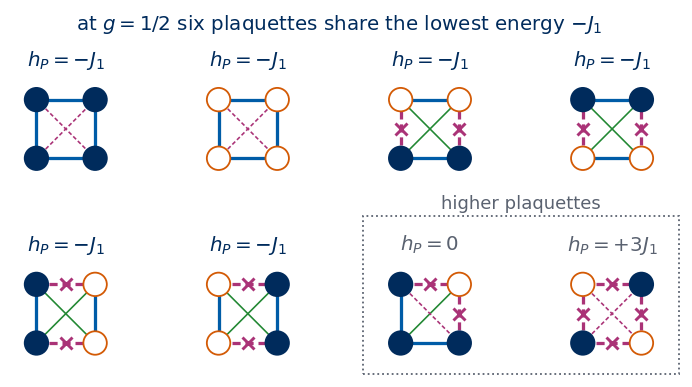

In [ ]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("figures", exist_ok=True)
    for d in ("figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def draw_spin(ax, x, y, s, r=0.26, sign=False, alpha=1.0, fs=10, lw=1.3):
    # one Ising spin at (x, y): navy disc for s = +1, white disc with orange rim for s = -1 (optionally with "+" / "-")
    face, edge, txt = (NAVY, NAVY, "white") if s > 0 else ("white", ORANGE, ORANGE)
    ax.add_patch(mpatches.Circle((x, y), r, fc=face, ec=edge, lw=lw, alpha=alpha, zorder=4))
    if sign:
        ax.text(x, y, "+" if s > 0 else "−", color=txt, ha="center", va="center", alpha=alpha,
                fontsize=fs, fontweight="bold", zorder=5)

def draw_bond(ax, p, q, broken=False, lw=1.5, alpha=1.0, color=None, cross=True):
    # bond between points p and q: solid blue if satisfied, dashed purple with a cross if broken
    c = color or (PURPLE if broken else BLUE)
    ax.plot([p[0], q[0]], [p[1], q[1]], color=c, lw=lw, ls=(0, (2.5, 1.5)) if broken else "-",
            alpha=alpha, solid_capstyle="round", zorder=2)
    if broken and cross:
        ax.plot((p[0] + q[0]) / 2, (p[1] + q[1]) / 2, marker="x", ms=3.5 * lw, mew=lw * 0.9, color=c, alpha=alpha, zorder=3)

def draw_j1j2_patch(ax, S, mark_bonds=True):
    # spins S[y, x] of an open patch; J1 bonds thick (satisfied if parallel), J2 diagonals thin (satisfied if antiparallel)
    ny, nx = S.shape
    if mark_bonds:
        for y in range(ny):
            for x in range(nx):
                for dx, dy in [(1, 0), (0, 1)]:
                    if x + dx < nx and y + dy < ny:
                        draw_bond(ax, (x, y), (x + dx, y + dy), broken=S[y, x] * S[y + dy, x + dx] < 0, lw=1.8)
                for dx, dy in [(1, 1), (1, -1)]:
                    if x + dx < nx and 0 <= y + dy < ny:
                        sat = S[y, x] * S[y + dy, x + dx] < 0
                        draw_bond(ax, (x, y), (x + dx, y + dy), broken=not sat, lw=0.9, color=GREEN if sat else PURPLE, cross=False)
    for (y, x), s in np.ndenumerate(S):
        draw_spin(ax, x, y, s, r=0.2, lw=1)
    ax.set_xlim(-0.5, nx - 0.5); ax.set_ylim(-0.5, ny - 0.5); ax.set_aspect("equal"); ax.axis("off")

def sketch_plaquettes_at_g_half():
    g = 0.5
    def h_P(P):
        # plaquette energy with J1 = 1: corners a, b (bottom), d, c (top); P[y, x]
        a, b, d, c = P[0, 0], P[0, 1], P[1, 0], P[1, 1]
        return -0.5 * (a * b + b * c + c * d + d * a) + g * (a * c + b * d)
    minimal = [np.array([[1, 1], [1, 1]]), np.array([[-1, -1], [-1, -1]]),
               np.array([[1, 1], [-1, -1]]), np.array([[-1, -1], [1, 1]]),
               np.array([[1, -1], [1, -1]]), np.array([[-1, 1], [-1, 1]])]
    others = [np.array([[1, 1], [1, -1]]), np.array([[1, -1], [-1, 1]])]
    fig, axes = plt.subplots(2, 4, figsize=(5.5, 2.9))
    fig.subplots_adjust(left=0.02, right=0.98, bottom=0.03, top=0.8, wspace=0.3, hspace=0.75)
    for ax, P in zip(axes.flat, minimal + others):
        draw_j1j2_patch(ax, P)
        e = h_P(P)
        label = {-1: "-J_1", 0: "0"}.get(round(e), f"{e:+g}J_1")             # -J_1, 0, +3J_1
        ax.set_title(f"$h_P={label}$", fontsize=11, color=NAVY if e == -1 else GRAY)
        ax.set_xlim(-0.4, 1.4); ax.set_ylim(-0.4, 1.4)
    fig.text(0.5, 0.97, "at $g=1/2$ six plaquettes share the lowest energy $-J_1$", ha="center", va="top", fontsize=11, color=NAVY)
    # a dotted frame around the two higher plaquettes
    p0, p1 = axes[1, 2].get_position(), axes[1, 3].get_position()
    fig.add_artist(mpatches.Rectangle((p0.x0 - 0.02, p0.y0 - 0.02), p1.x1 - p0.x0 + 0.04, p0.height + 0.14, transform=fig.transFigure,
                                      fill=False, ec=GRAY, lw=1, ls=":"))
    fig.text(0.5 * (p0.x0 + p1.x1), p0.y1 + 0.13, "higher plaquettes", ha="center", va="bottom", fontsize=10, color=GRAY)
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_plaquettes_at_g_half()
save_sketch(fig, "sketch_j1j2_plaquettes_half.png")
plt.show()


This growth can be derived exactly. At $g=1/2$ a configuration is a ground state if and only if every plaquette is one of the six minimal ones (Section 3.2): the two uniform
plaquettes and the four with one edge up and the opposite edge down. Describe a configuration by its bond variables $h_{x,y}=s_{x,y}s_{x+1,y}$ (horizontal) and
$v_{x,y}=s_{x,y}s_{x,y+1}$ (vertical). Two properties characterise the six minimal plaquettes:

1. *The product of the four corner spins is $+1$.* For the plaquette at $(x,y)$ this says $s_{x,y}s_{x+1,y}=s_{x,y+1}s_{x+1,y+1}$, i.e. $h_{x,y}=h_{x,y+1}$: the
   horizontal bond variables do not depend on $y$, $h_{x,y}\equiv h_x$. Likewise $v_{x,y}\equiv v_y$ does not depend on $x$.
2. *It is not a Néel plaquette.* A Néel plaquette is the only one with product $+1$ that has a broken horizontal **and** a broken vertical edge. So
   $h_x=-1$ and $v_y=-1$ never occur together.

By property 2, either all $h_x=+1$ — every row is uniform and the $M$ row signs are free: $2^M$ configurations — or all $v_y=+1$ — every column is uniform:
$2^L$ configurations. The two sets share the two uniform states. Hence, on the $L\times M$ torus,
$$
\boxed{\,n_0\big(g=\tfrac12\big) = 2^{L}+2^{M}-2\,}.
$$
The degeneracy grows exponentially with the **linear** size, not with the number of spins: the entropy per spin $\ln n_0/N\approx\ln 2/L\to0$. The ground state at
$g=1/2$ is therefore a "sub-extensively" degenerate manifold of independently flippable rows (or columns).

The same count follows from a transfer matrix, which gives an independent check. In the row language, two rows $\sigma,\sigma'$ may follow each other
if all $L$ plaquettes between them are minimal; we define the $0/1$ matrix $A_{\sigma\sigma'}$ accordingly, so that $n_0=\operatorname{Tr}A^M$. The derivation predicts the structure of $A$: a uniform row may be followed by either uniform row
(a $2\times2$ block of ones, eigenvalues $2$ and $0$), and a non-uniform row only by itself (an identity block of size $2^L-2$). So
$\operatorname{Tr}A^M = 2^M+(2^L-2)$, and the largest eigenvalue of $A$ is $2$ for every width $L$. The cell builds $A$ from the plaquette energies, checks its
structure through its largest eigenvalue, and counts $\operatorname{Tr}A^M$ for $L,M\le10$; for $L\le6$ it also checks against the full (min, +) calculation.

In [10]:
def good_row_pairs(L):
    # A[sigma, sigma'] = 1 if all L plaquettes between rows sigma (bottom) and sigma' (top) have the minimal energy -1 at g = 1/2; shape (2^L, 2^L)
    R = all_configs(L).astype(np.int64)
    a, b = R[:, None, :], np.roll(R, -1, 1)[:, None, :]           # bottom corners: (x, y), (x+1, y)
    d, c = R[None, :, :], np.roll(R, -1, 1)[None, :, :]           # top corners:    (x, y+1), (x+1, y+1)
    hP = -0.5 * (a * b + b * c + c * d + d * a) + 0.5 * (a * c + b * d)     # (2^L, 2^L, L)
    return np.all(hP == -1, axis=2).astype(np.float64)

t0 = time.perf_counter()
deg = {}
print("  L \\ M " + "".join(f"{M:>7d}" for M in range(4, 11)))
for L in range(4, 11):
    A = good_row_pairs(L)
    uniform = [0, 2**L - 1]                                         # indices of the all-up and all-down rows
    rest = np.setdiff1d(np.arange(2**L), uniform)
    assert np.all(A[np.ix_(uniform, uniform)] == 1)                 # 2x2 block of ones
    assert np.array_equal(A[np.ix_(rest, rest)], np.eye(len(rest))) # identity block
    assert A[np.ix_(uniform, rest)].sum() == 0
    counts = []
    for M in range(4, 11):
        n0 = int(round(np.trace(np.linalg.matrix_power(A, M))))
        assert n0 == 2**L + 2**M - 2
        deg[(L, M)] = n0
        counts.append(n0)
    lam_max = eigh(A, eigvals_only=True)[-1] if L <= 8 else 2.0      # the block structure fixes it to 2 for every L
    print(f"  {L:3d}   " + "".join(f"{n:7d}" for n in counts) + f"     largest eigenvalue of A: {lam_max:.6f}")
for L, M in [(4, 6), (6, 6), (6, 8)]:
    assert minplus_torus(L, M, 0.5)[1] == deg[(L, M)]
print("all counts equal 2^L + 2^M - 2; the (min,+) transfer matrix with full energies agrees for 4x6, 6x6, 6x8")
print(f"({time.perf_counter() - t0:.1f} s)")

  L \ M       4      5      6      7      8      9     10
    4        30     46     78    142    270    526   1038     largest eigenvalue of A: 2.000000
    5        46     62     94    158    286    542   1054     largest eigenvalue of A: 2.000000
    6        78     94    126    190    318    574   1086     largest eigenvalue of A: 2.000000


    7       142    158    190    254    382    638   1150     largest eigenvalue of A: 2.000000


    8       270    286    318    382    510    766   1278     largest eigenvalue of A: 2.000000


    9       526    542    574    638    766   1022   1534     largest eigenvalue of A: 2.000000


   10      1038   1054   1086   1150   1278   1534   2046     largest eigenvalue of A: 2.000000
all counts equal 2^L + 2^M - 2; the (min,+) transfer matrix with full energies agrees for 4x6, 6x6, 6x8
(2.7 s)


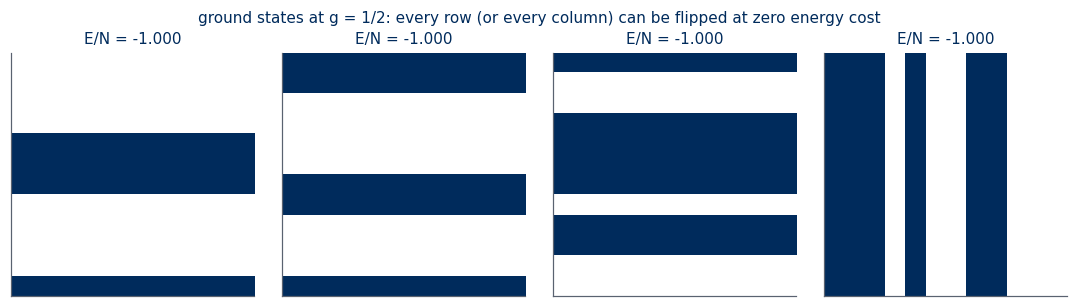

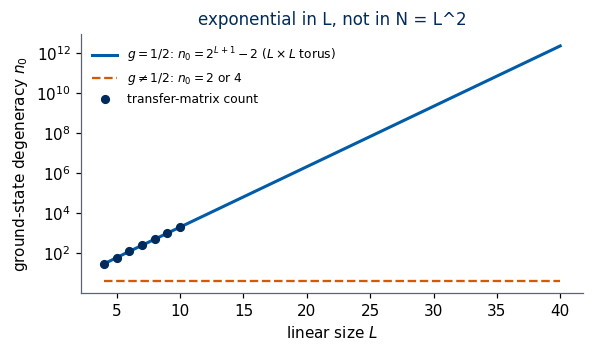

In [11]:
# a few ground states at g = 1/2 on a 12 x 12 torus: rows (or columns) with random signs; all have E/N = -1
L = 12
rng = np.random.default_rng(3)
gs_examples = [np.repeat(rng.choice([-1, 1], L)[None, :], L, 0) for _ in range(3)]          # rows uniform in x, random sign per row y
gs_examples += [np.repeat(rng.choice([-1, 1], L)[:, None], L, 1)]                          # columns uniform
fig, ax = plt.subplots(1, 4, figsize=(10, 2.8))
for a, s in zip(ax, gs_examples):
    a.imshow(s.T, cmap=SPIN_CMAP, vmin=-1, vmax=1, origin="lower")
    a.set_title(f"E/N = {energy(s, 0.5) / L**2:+.3f}", fontsize=10); a.set_xticks([]); a.set_yticks([])
fig.suptitle("ground states at g = 1/2: every row (or every column) can be flipped at zero energy cost", fontsize=10, color=UJNavy)
plt.tight_layout(); plt.show()
for s in gs_examples:
    assert abs(energy(s, 0.5) / L**2 + 1) < 1e-12

Ls = np.arange(4, 41)
fig, ax = plt.subplots(figsize=(5.5, 3.3))
ax.semilogy(Ls, 2.0**(Ls + 1) - 2, "-", color=UJBlue, lw=2, label=r"$g=1/2$: $n_0=2^{L+1}-2$ ($L\times L$ torus)")
ax.semilogy(Ls, 4 * np.ones_like(Ls), "--", color=DSOrange, lw=1.5, label=r"$g\neq1/2$: $n_0=2$ or $4$")
Lc = np.array(sorted({L for (L, M) in deg if L == M}))
ax.semilogy(Lc, [deg[(L, L)] for L in Lc], "o", color=UJNavy, ms=5, label="transfer-matrix count")
ax.set_xlabel("linear size $L$"); ax.set_ylabel("ground-state degeneracy $n_0$"); ax.legend(frameon=False, fontsize=8)
ax.set_title("exponential in L, not in N = L^2")
plt.tight_layout(); plt.show()

Every entry of the table equals $2^L+2^M-2$ and the largest eigenvalue of $A$ is $2$ for every width, as derived. The figures show
several of these ground states: rows or columns of independent sign, all with the same energy. Collecting the results of this section, for $g\neq1/2$ the ground state is the ferromagnet (2 states) or the stripes (4 states). At $g=1/2$ the ground-state energy is $-J_1$
per spin and the degeneracy on an $L\times M$ torus is exactly $2^L+2^M-2$: any row (or column) can be flipped at no cost. This
is the microscopic form of frustration in this model, and it has two consequences developed below: domain walls along rows cost nothing at $g=1/2$
(Section 4), and the strip free energy keeps a residual entropy $\ln2/L$ per spin at $T\to0$ (Section 8).

<hr/>
## 4. Domain walls

The ground states tell us what orders, but not up to which temperature the order survives. An ordered phase survives at $T>0$ only if large regions of the "wrong" ordered state are rare. Such a region is bounded by a
**domain wall**, and the competition between the energy of the wall and the number of ways to draw it decides whether order survives (Lab 012, Section 3.3).
We therefore compute the energy per unit length of straight walls as a function of $g$. There are four kinds of straight wall along a
lattice axis (a vertical line between columns $x_0$ and $x_0+1$, or a horizontal one):

1. *Ferromagnet, $+|-$.* Across the wall, per unit length: one horizontal nearest-neighbour bond turns from satisfied to broken ($+2J_1$), and the two diagonal bonds
   crossing the wall turn from broken ($s_is_j=+1$) to satisfied ($-2J_2$ each):
   $\ \sigma_{\rm FM} = 2J_1-4J_2 = 2J_1(1-2g)$.
2. *Stripes, wall parallel to the stripes* (a phase slip, $\dots{+}{-}{+}\,|\,{+}{-}{+}\dots$): the horizontal bond across the wall turns from broken to satisfied ($-2J_1$),
   the two diagonals from satisfied to broken ($+4J_2$): $\ \sigma_{\parallel} = 4J_2-2J_1 = 2J_1(2g-1)$.
3. *Stripes, wall perpendicular to the stripes* (all spins flipped on one side): the vertical bond turns from satisfied to broken ($+2J_1$), the two diagonals from satisfied to
   broken ($+4J_2$): $\ \sigma_{\perp} = 2J_1+4J_2$.
4. *Stripes, a $90^\circ$ wall* between vertical and horizontal stripes. Here a bond-by-bond count near the wall is misleading, because a finite domain of horizontal stripes has
   a different share of satisfied horizontal and vertical bonds than a domain of vertical stripes. Count the totals instead. Nearest-neighbour bonds: in both stripe orientations half of them are satisfied,
   $B_1=0$, and the horizontal bonds crossing the wall have products that alternate along it and sum to zero, so $\Delta B_1=0$. Diagonal bonds: the two per unit length that cross the wall change from
   $s_is_j=-1$ to products that alternate along the wall, i.e. from energy $-J_2$ to $0$ on average: $\ \sigma_{90^\circ} = 2J_2$.

The four walls are drawn below on $8\times6$ patches; the purple line is the wall and $\sigma$ its energy per unit length. In the ferromagnet and for the stripe wall parallel to the stripes, crossing the wall exchanges broken nearest-neighbour bonds for satisfied diagonal bonds or the reverse, which is why their cost is proportional to $1-2g$ or $2g-1$.

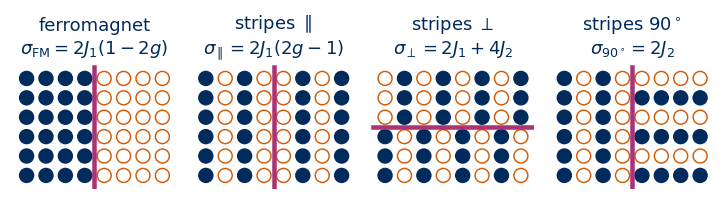

In [ ]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("figures", exist_ok=True)
    for d in ("figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def draw_spin(ax, x, y, s, r=0.26, sign=False, alpha=1.0, fs=10, lw=1.3):
    # one Ising spin at (x, y): navy disc for s = +1, white disc with orange rim for s = -1 (optionally with "+" / "-")
    face, edge, txt = (NAVY, NAVY, "white") if s > 0 else ("white", ORANGE, ORANGE)
    ax.add_patch(mpatches.Circle((x, y), r, fc=face, ec=edge, lw=lw, alpha=alpha, zorder=4))
    if sign:
        ax.text(x, y, "+" if s > 0 else "−", color=txt, ha="center", va="center", alpha=alpha,
                fontsize=fs, fontweight="bold", zorder=5)

def draw_bond(ax, p, q, broken=False, lw=1.5, alpha=1.0, color=None, cross=True):
    # bond between points p and q: solid blue if satisfied, dashed purple with a cross if broken
    c = color or (PURPLE if broken else BLUE)
    ax.plot([p[0], q[0]], [p[1], q[1]], color=c, lw=lw, ls=(0, (2.5, 1.5)) if broken else "-",
            alpha=alpha, solid_capstyle="round", zorder=2)
    if broken and cross:
        ax.plot((p[0] + q[0]) / 2, (p[1] + q[1]) / 2, marker="x", ms=3.5 * lw, mew=lw * 0.9, color=c, alpha=alpha, zorder=3)

def sketch_j1j2_domain_walls():
    nx, ny = 8, 6
    y, x = np.indices((ny, nx))
    vertical = (-1) ** x                                            # vertical stripes
    walls = [
        (np.where(x < 4, 1, -1), "ferromagnet", r"$\sigma_{\rm FM}=2J_1(1-2g)$", "v"),
        (np.where(x < 4, vertical, -vertical), r"stripes $\parallel$", r"$\sigma_\parallel=2J_1(2g-1)$", "v"),
        (np.where(y < 3, vertical, -vertical), r"stripes $\perp$", r"$\sigma_\perp=2J_1+4J_2$", "h"),
        (np.where(x < 4, vertical, (-1) ** y), r"stripes $90^\circ$", r"$\sigma_{90^\circ}=2J_2$", "v"),
    ]
    fig, axes = plt.subplots(1, 4, figsize=(5.5, 2.05))
    fig.subplots_adjust(left=0.01, right=0.99, bottom=0.01, top=0.76, wspace=0.1)
    for ax, (S, name, sigma, orient) in zip(axes, walls):
        for (yy, xx), s in np.ndenumerate(S):
            draw_spin(ax, xx, yy, s, r=0.36, lw=0.8)
        if orient == "v":
            ax.plot([3.5, 3.5], [-0.6, ny - 0.4], color=PURPLE, lw=2.5, zorder=5)
        else:
            ax.plot([-0.6, nx - 0.4], [2.5, 2.5], color=PURPLE, lw=2.5, zorder=5)
        ax.set_title(f"{name}\n{sigma}", fontsize=10, color=NAVY)
        ax.set_xlim(-0.7, nx - 0.3); ax.set_ylim(-0.7, ny - 0.3); ax.set_aspect("equal"); ax.axis("off")
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_j1j2_domain_walls()
save_sketch(fig, "sketch_j1j2_domain_walls.png")
plt.show()


The first two vanish at $g=1/2$, the last two do not. To confirm the counting, the cell constructs each wall on a $16\times16$ torus (two parallel walls, because of the periodic boundaries), computes the
changes $\Delta B_1$, $\Delta B_2$ with the bond-sum function, and forms the **symbolic** cost $\sigma=(-J_1\Delta B_1+J_2\Delta B_2)/(2L)$ with SymPy.

ferromagnet +|-           : Delta B1 =  -64, Delta B2 = -128  ->  sigma = 2*J_1 - 4*J_2   zero at g = [1/2]
stripes, parallel (slip)  : Delta B1 =  +64, Delta B2 = +128  ->  sigma = -2*J_1 + 4*J_2  zero at g = [1/2]
stripes, perpendicular    : Delta B1 =  -64, Delta B2 = +128  ->  sigma = 2*J_1 + 4*J_2   zero at g = []
stripes, 90 degrees       : Delta B1 =   +0, Delta B2 =  +64  ->  sigma = 2*J_2           zero at g = []


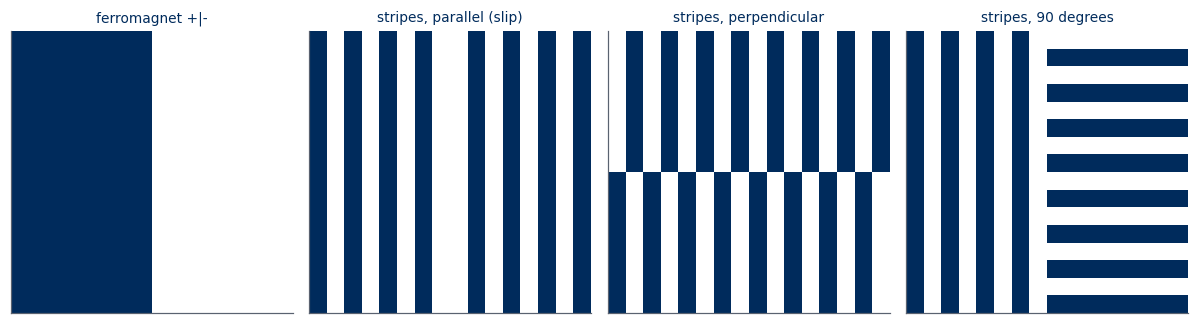

In [12]:
L = 16
x, y = np.meshgrid(np.arange(L), np.arange(L), indexing="ij")
left = x < L // 2                                     # left half of the torus; its two boundaries are the two walls
walls = {   # name: (configuration with two walls, reference ordered state)
    "ferromagnet +|-":             (np.where(left, 1, -1),                        np.ones((L, L), int)),
    "stripes, parallel (slip)":    (np.where(left, 1, -1) * (-1) ** x,            (-1) ** x),
    "stripes, perpendicular":      (np.where(y < L // 2, 1, -1) * (-1) ** x,      (-1) ** x),
    "stripes, 90 degrees":         (np.where(left, (-1) ** x, (-1) ** y),         (-1) ** x),
}
sigma_sym = {}
for name, (s_wall, s_ref) in walls.items():
    bw, br = bond_sums(s_wall), bond_sums(s_ref)
    dB1 = int(bw[0] + bw[1] - br[0] - br[1]); dB2 = int(bw[2] - br[2])
    sigma_sym[name] = sp.simplify((-J1s * dB1 + J2s * dB2) / (2 * L))       # energy per unit length of one wall
    print(f"{name:26s}: Delta B1 = {dB1:+4d}, Delta B2 = {dB2:+4d}  ->  sigma = {str(sigma_sym[name]):14s}"
          f"  zero at g = {sp.solve(sigma_sym[name].subs({J1s: 1, J2s: gs_}), gs_)}")

fig, ax = plt.subplots(1, 4, figsize=(11, 2.9))
for a, (name, (s_wall, _)) in zip(ax, walls.items()):
    a.imshow(s_wall.T, cmap=SPIN_CMAP, vmin=-1, vmax=1, origin="lower"); a.set_title(name, fontsize=9); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

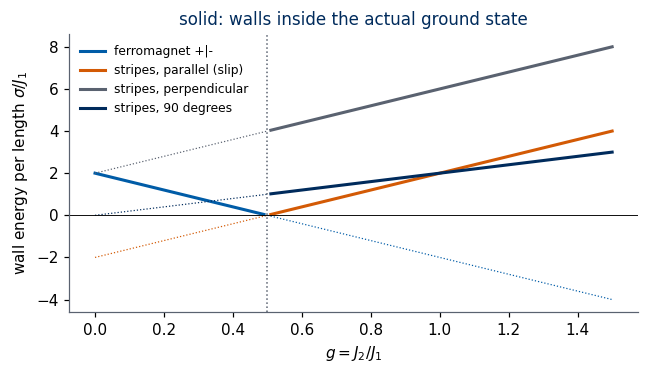

numerical wall energies agree with the symbolic formulas for all 151 values of g


In [13]:
# numerical check: sigma(g) from the energies of the constructed configurations versus the symbolic formulas, and a plot
g_line = np.linspace(0, 1.5, 151)
fig, ax = plt.subplots(figsize=(6, 3.5))
cols = [UJBlue, DSOrange, UJGray, UJNavy]
for c_, (name, (s_wall, s_ref)) in zip(cols, walls.items()):
    sig_num = np.array([(energy(s_wall, gv) - energy(s_ref, gv)) / (2 * L) for gv in g_line])
    sig_formula = sp.lambdify(gs_, sigma_sym[name].subs({J1s: 1, J2s: gs_}))(g_line) * np.ones_like(g_line)
    assert np.allclose(sig_num, sig_formula)
    ref_valid = g_line < 0.5 if name.startswith("ferro") else g_line > 0.5     # the reference state is the ground state only there
    ax.plot(g_line[ref_valid], sig_num[ref_valid], color=c_, lw=2, label=name)
    ax.plot(g_line[~ref_valid], sig_num[~ref_valid], color=c_, lw=0.8, ls=":")
ax.axhline(0, color="k", lw=0.6); ax.axvline(0.5, color=UJGray, ls=":", lw=1)
ax.set_xlabel("$g=J_2/J_1$"); ax.set_ylabel(r"wall energy per length $\sigma/J_1$"); ax.legend(frameon=False, fontsize=8)
ax.set_title("solid: walls inside the actual ground state")
plt.tight_layout(); plt.show()
print("numerical wall energies agree with the symbolic formulas for all 151 values of g")

SymPy recovers all four wall energies from the constructed configurations, and the plot shows them as functions of $g$: two lines cross zero at $g=1/2$.

The wall energies can be turned into a temperature scale by a Peierls-type argument. Consider a closed wall of length $\ell$ (in lattice units) enclosing a region of the wrong ordered state. Its energy is $\sigma\ell$.
The number of closed walls of length $\ell$ through a given bond grows at most like $\mu^\ell$ with some constant $\mu$ (for walls drawn along lattice bonds, $\mu\le3$, since
each step can go in at most three directions without stepping back). The free energy of such walls is therefore
$$
\Delta F(\ell) \gtrsim \ell\,\big(\sigma - T\ln\mu\big).
$$
While $\sigma>T\ln\mu$, long walls are exponentially suppressed and the order survives: this is Peierls' argument for the ferromagnet [Peierls 1936; rigorous form
Griffiths 1964], which gives the estimate $T_c\gtrsim 2J_1/\ln3\approx1.82\,J_1$ at $g=0$ (Lab 012), consistent with the exact $2.269\,J_1$. For our model the argument is a heuristic
(other wall shapes, corners and the extra stripe walls would have to be counted), but its two conclusions are robust.
First, the temperature scale below which walls are suppressed is proportional to the **cheapest** wall energy: $\sigma_{\min}(g) = 2J_1(1-2g)$ on the ferromagnetic side; on the stripe side
$\sigma_{\min}=\min(2J_1(2g-1),\,2J_2)$, i.e. the parallel wall for $1/2<g<1$ and the $90^\circ$ wall for $g>1$.
Second, at $g=1/2$ this energy vanishes. Walls along rows cost nothing — exactly the free row flips of Section 3.5 — and nothing prevents the order from being destroyed by
thermal fluctuations at any $T>0$. Near $g=1/2$ the ordering temperature must therefore go to zero.

We plot the estimate $T_{\rm wall}(g)=\sigma_{\min}(g)/\ln3$ together with the computed $T_c(g)$ in Section 9; it is an order-of-magnitude estimate, not a prediction of $T_c$.

In short, straight domain walls cost $2J_1(1-2g)$ per unit length in the ferromagnet; in the stripe phase the parallel wall costs $2J_1(2g-1)$, the $90^\circ$ wall $2J_2$ and the
perpendicular wall $2J_1+4J_2$. The cheapest wall on each side vanishes linearly at $g=1/2$ — the physical reason why the transition temperature drops to zero there.

<hr/>
## 5. Exact limits

Before computing $T_c(g)$ numerically we fix its two ends, where the model can be solved exactly. These limits anchor the phase diagram,
test every numerical method below, and the large-$g$ limit explains the Ashkin–Teller structure of Section 2.

### 5.1 Onsager limit

At $J_2=0$ the model is the square-lattice Ising ferromagnet, solved by Onsager [1944]: $T_c$ is fixed by $\sinh(2J_1/T_c)=1$ (Lab 012, Kramers–Wannier duality), so
$T_c = 2J_1/\ln(1+\sqrt2)$.

### 5.2 Decoupled sublattices at large $g$

Dividing by $J_2$ gives $H/J_2 = B_2 - B_1/g$, so for $g\to\infty$ only the diagonal bonds remain. A diagonal bond joins $(x,y)$ to $(x\pm1,y\pm1)$, which has the same
parity of $x+y$. The lattice splits into two sublattices, $\mathcal A$ ($x+y$ even) and $\mathcal B$ ($x+y$ odd), with no bond between them. Each is itself a square lattice,
rotated by $45^\circ$ and with lattice constant $\sqrt2$ (primitive vectors $(1,1)$ and $(1,-1)$); on it the diagonal bonds are nearest-neighbour bonds with antiferromagnetic coupling $J_2$.

The antiferromagnetic sign is removed by the column gauge $s_{x,y}\to(-1)^xs_{x,y}$, which changes the sign of every diagonal product (Section 2):
$$
\begin{aligned}
Z(J_1=0,J_2) &= \sum_{\mathbf s}e^{-\beta J_2B_2(\mathbf s)} = \sum_{\mathbf s}e^{+\beta J_2B_2(\mathbf s)}\\
&= Z^{\rm Ising}_{\mathcal A}(J_2)\;Z^{\rm Ising}_{\mathcal B}(J_2),
\end{aligned}
$$
because the gauge is a bijection of the configuration space. Each factor is a square-lattice Ising ferromagnet with coupling $J_2$, so
$$
\begin{aligned}
T_c &\xrightarrow{g\to\infty} \frac{2J_2}{\ln(1+\sqrt2)} = g\cdot\frac{2J_1}{\ln(1+\sqrt2)},\\
\frac{T_c}{J_2}&\to2.269 .
\end{aligned}
$$

The gauge also exposes the Ashkin–Teller variables. After it, vertical stripes $(-1)^x$ become all $+1$, and horizontal stripes $(-1)^y$ become $(-1)^{x+y}$: $+1$ on $\mathcal A$, $-1$ on $\mathcal B$.
So the four stripe states are the four combinations of the two sublattice magnetisations $(\sigma_{\mathcal A},\sigma_{\mathcal B})=(\pm1,\pm1)$: two Ising order parameters,
as in the Ashkin–Teller model. A finite $J_1$ couples the two sublattices. In the gauged frame the nearest-neighbour bonds are ferromagnetic vertically and antiferromagnetic
horizontally, so a spin of $\mathcal A$ in a uniformly magnetised $\mathcal B$ feels $J_1(\sigma_{\mathcal B}+\sigma_{\mathcal B}-\sigma_{\mathcal B}-\sigma_{\mathcal B})=0$: $J_1$ does not
couple the magnetisations linearly — it cannot prefer either orientation, which is the fourfold degeneracy again. Kalz, Honecker and Moliner [2011] derived, by perturbation in $J_1$
around the two decoupled critical Ising models, that the effective theory is the Ashkin–Teller model.

The next two cells check these statements. The first solves $\sinh2K=1$ with SymPy and applies the gauge to the Hamiltonian symbolically. The second
verifies the factorisation $Z=Z_{\mathcal A}Z_{\mathcal B}$ exactly on the $4\times4$ torus at three temperatures, and confirms that $J_1$ gives the same
energy to all four stripe states while the gauge maps them onto the four sign combinations $(\sigma_{\mathcal A},\sigma_{\mathcal B})$.

In [14]:
K = sp.symbols("K", positive=True)
Kc = sp.solve(sp.Eq(sp.sinh(2 * K), 1), K)[0]
print("sinh(2K) = 1  ->  K_c =", Kc, ";   K_c - ln(1+sqrt2)/2 simplifies to", sp.simplify((Kc - sp.log(1 + sp.sqrt(2)) / 2).rewrite(sp.log)))
print("T_c / J = 1/K_c =", sp.N(1 / Kc, 12))
assert abs(float(1 / Kc) - TC_ISING) < 1e-12

# symbolic form of the gauged Hamiltonian: B1x -> -B1x, B1y -> B1y, B2 -> -B2 (Section 2)
B1x_, B1y_, B2_ = sp.symbols("B_1^x B_1^y B_2")
H_orig = -J1s * (B1x_ + B1y_) + J2s * B2_
H_gauge = H_orig.subs({B1x_: -B1x_, B2_: -B2_}, simultaneous=True)
print("H after the column gauge:", sp.expand(H_gauge), "  (diagonal bonds ferromagnetic; at J_1 = 0 a pure ferromagnet)")

sinh(2K) = 1  ->  K_c = log(sqrt(1 + sqrt(2))) ;   K_c - ln(1+sqrt2)/2 simplifies to 0
T_c / J = 1/K_c = 2.26918531421
H after the column gauge: B_1^x*J_1 - B_1^y*J_1 - B_2*J_2   (diagonal bonds ferromagnetic; at J_1 = 0 a pure ferromagnet)


In [15]:
# exact factorisation Z(J1 = 0, J2) = Z_A Z_B on the 4x4 torus (all 2^16 states), and Z_A from the 8 spins of sublattice A alone
xs, ys = np.meshgrid(np.arange(4), np.arange(4), indexing="ij")
A_sites = np.argwhere((xs + ys) % 2 == 0)                      # the 8 sites of sublattice A, shape (8, 2)
def sublattice_B2(sub):
    # sum of s_i s_j over diagonal bonds inside sublattice A, sub: (n, 8) spins on A_sites; each bond once
    idx = {tuple(p): k for k, p in enumerate(A_sites)}
    tot = 0
    for k, (x0, y0) in enumerate(A_sites):
        for dx, dy in ((1, 1), (1, -1)):
            tot = tot + sub[:, k] * sub[:, idx[((x0 + dx) % 4, (y0 + dy) % 4)]]
    return tot
SA = all_configs(8).astype(np.int64)
b2A = sublattice_B2(SA)
for T in (1.5, 2.269, 3.5):
    J2v = 1.0
    Z_full = np.exp(-J2v * B2_44 / T).sum()                    # J1 = 0
    Z_A = np.exp(-J2v * b2A / T).sum()                         # antiferromagnet on A
    Z_A_ferro = np.exp(+J2v * b2A / T).sum()                   # gauged: ferromagnet on A
    print(f"T = {T}:  Z(J1=0) = {Z_full:.10e}   Z_A^2 = {Z_A**2:.10e}   Z_A(ferro)^2 = {Z_A_ferro**2:.10e}")

# J1 gives the same energy to the four stripe states (+-(-1)^x, +-(-1)^y): all have B1 = 0
L = 8; x, y = np.meshgrid(np.arange(L), np.arange(L), indexing="ij")
for name, s in {"V+": (-1) ** x, "V-": -(-1) ** x, "H+": (-1) ** y, "H-": -(-1) ** y}.items():
    b = bond_sums(s); sg = s * (-1) ** x                         # gauged configuration
    sA, sB = sg[(x + y) % 2 == 0].mean(), sg[(x + y) % 2 == 1].mean()
    print(f"stripe {name}: B1 = {b[0] + b[1]:+d}, B2/N = {b[2] / L**2:+.0f};  after the gauge (sigma_A, sigma_B) = ({sA:+.0f}, {sB:+.0f})")

T = 1.5:  Z(J1=0) = 8.0525986070e+09   Z_A^2 = 8.0525986070e+09   Z_A(ferro)^2 = 8.0525986070e+09
T = 2.269:  Z(J1=0) = 1.0249678695e+07   Z_A^2 = 1.0249678695e+07   Z_A(ferro)^2 = 1.0249678695e+07
T = 3.5:  Z(J1=0) = 3.8301661468e+05   Z_A^2 = 3.8301661468e+05   Z_A(ferro)^2 = 3.8301661468e+05
stripe V+: B1 = +0, B2/N = -2;  after the gauge (sigma_A, sigma_B) = (+1, +1)
stripe V-: B1 = +0, B2/N = -2;  after the gauge (sigma_A, sigma_B) = (-1, -1)
stripe H+: B1 = +0, B2/N = -2;  after the gauge (sigma_A, sigma_B) = (+1, -1)
stripe H-: B1 = +0, B2/N = -2;  after the gauge (sigma_A, sigma_B) = (-1, +1)


All three columns of partition functions agree to every printed digit, and the four stripe states have $B_1=0$. Both ends of the phase diagram are now fixed:
$T_c(0)=2.269\,J_1$ and $T_c/J_2\to2.269$ for $g\to\infty$; the transfer matrices (Section 8) and Monte Carlo (Section 9) must reproduce both. At large $g$
the stripe order parameter is a pair of Ising magnetisations of two sublattices, which is the microscopic origin of the Ashkin–Teller structure.

<hr/>
## 6. Mean-field theory

Mean-field theory is the first approximation one tries for any interacting system: it reduces the many-body problem to one spin in an
effective field. It is worth deriving carefully, because its failure here is instructive: it gets the ordered phases right, the transition temperatures
wrong, and misses the vanishing of $T_c$ at $g=1/2$ entirely.

Write $H=-\sum_{i<j}J_{ij}s_is_j$ with $J_{ij}=J_1$ for nearest neighbours and $J_{ij}=-J_2$ for diagonal neighbours. Spin $i$ interacts with its neighbours
through the local field $\sum_jJ_{ij}s_j$. Mean-field theory replaces the neighbours by their averages $m_j=\langle s_j\rangle$, i.e. neglects the correlations between $s_i$ and its
neighbours. Since a single spin in a field $h_i$ has $\langle s_i\rangle = \frac{e^{\beta h_i}-e^{-\beta h_i}}{e^{\beta h_i}+e^{-\beta h_i}}=\tanh\beta h_i$, we obtain
$$
m_i = \tanh\Big(\beta\sum_jJ_{ij}m_j\Big)\qquad\text{(self-consistency).}
$$

To solve these equations we try modulated solutions $m_{\boldsymbol r}=m\,e^{i\boldsymbol k\cdot\boldsymbol r}$ with $\boldsymbol k\in\{(0,0),(\pi,0),(0,\pi),(\pi,\pi)\}$ (then $e^{i\boldsymbol k\cdot\boldsymbol r}=\pm1$).
The local field becomes $\sum_jJ_{ij}m_j = \mathcal J(\boldsymbol k)\,m_i$ with the Fourier transform of the couplings
$$
\begin{aligned}
\mathcal J(\boldsymbol k) &= \sum_{\boldsymbol\delta}J_{\boldsymbol\delta}e^{i\boldsymbol k\cdot\boldsymbol\delta}\\
&= 2J_1(\cos k_x+\cos k_y) - 4J_2\cos k_x\cos k_y ,
\end{aligned}
$$
($\boldsymbol\delta$ runs over the 4 nearest and 4 diagonal neighbour vectors) and the self-consistency reduces to the single equation $m=\tanh(\beta\mathcal J(\boldsymbol k)m)$.

The transition temperature follows from the expansion for small $m$, $\tanh z = z - z^3/3+O(z^5)$:
$$
\begin{aligned}
m &= \beta\mathcal J m - \tfrac13(\beta\mathcal J)^3m^3\\
\Rightarrow\quad m&=0\ \ \text{or}\ \ m^2 = \frac{3T^2(T_{\rm MF}-T)}{T_{\rm MF}^3}\approx 3\Big(1-\frac{T}{T_{\rm MF}}\Big),\\
T_{\rm MF}&=\mathcal J(\boldsymbol k).
\end{aligned}
$$
A non-zero solution exists below $T_{\rm MF}$, with $m\propto(T_{\rm MF}-T)^{1/2}$ (the mean-field exponent $\beta=1/2$; the exact 2D Ising value is $1/8$). For general $m_i$, the linearised
equation $m_i=\beta\sum_jJ_{ij}m_j$ first has a non-zero solution when $T$ equals the **largest eigenvalue** of the matrix $J_{ij}$, i.e. $\max_{\boldsymbol k}\mathcal J(\boldsymbol k)$ (the matrix is diagonalised by
plane waves). Evaluating at the candidate wave vectors gives
$$
\begin{aligned}
T^{\rm FM}_{\rm MF}&=\mathcal J(0,0)=4(J_1-J_2),\\
T^{\rm str}_{\rm MF}&=\mathcal J(\pi,0)=4J_2,\\
\mathcal J(\pi,\pi)&=-4(J_1+J_2)<0 .
\end{aligned}
$$
The cell derives these results with SymPy and also shows that at $g=1/2$ the maximum of $\mathcal J(\boldsymbol k)$ is reached on **whole lines** of the Brillouin zone.

In [16]:
kx, ky, Ts_, Tmf, m_ = sp.symbols("k_x k_y T T_MF m", real=True)
Jk = 2 * J1s * (sp.cos(kx) + sp.cos(ky)) - 4 * J2s * sp.cos(kx) * sp.cos(ky)
for name, (a, b) in {"(0,0)": (0, 0), "(pi,0)": (sp.pi, 0), "(0,pi)": (0, sp.pi), "(pi,pi)": (sp.pi, sp.pi)}.items():
    print(f"J(k = {name:7s}) = {sp.simplify(Jk.subs({kx: a, ky: b}))}")
print("ferromagnet and stripes have equal T_MF at J_2 =", sp.solve(sp.Eq(4 * J1s - 4 * J2s, 4 * J2s), J2s))

# expansion of the self-consistency m = tanh(T_MF m / T) for small m
eq = sp.series(sp.tanh(Tmf * m_ / Ts_), m_, 0, 5).removeO() - m_
m2 = sp.solve(sp.expand(eq / m_), m_**2)[0]
print("non-zero solution: m^2 =", sp.factor(m2))
t_ = sp.symbols("t", positive=True)
print("with T = T_MF (1 - t):  m^2 =", sp.series(m2.subs(Ts_, Tmf * (1 - t_)), t_, 0, 2), "  -> m ~ sqrt(3 t), exponent 1/2")

# at g = 1/2 the maximum of J(k) is degenerate on the lines k_x = 0 and k_y = 0
J_half = sp.expand(Jk.subs({J1s: 1, J2s: sp.Rational(1, 2)}))
print("J(k) at g = 1/2:", J_half, "  =  2 - 2(1 - cos k_x)(1 - cos k_y):",
      sp.simplify(J_half - (2 - 2 * (1 - sp.cos(kx)) * (1 - sp.cos(ky)))) == 0)

J(k = (0,0)  ) = 4*J_1 - 4*J_2
J(k = (pi,0) ) = 4*J_2
J(k = (0,pi) ) = 4*J_2
J(k = (pi,pi)) = -4*J_1 - 4*J_2
ferromagnet and stripes have equal T_MF at J_2 = [J_1/2]


non-zero solution: m^2 = -3*T**2*(T - T_MF)/T_MF**3


with T = T_MF (1 - t):  m^2 = 3*t + O(t**2)   -> m ~ sqrt(3 t), exponent 1/2


J(k) at g = 1/2: -2*cos(k_x)*cos(k_y) + 2*cos(k_x) + 2*cos(k_y)   =  2 - 2(1 - cos k_x)(1 - cos k_y): True


Three numerical experiments test these statements. First, we solve the self-consistency $m=\tanh(T_{\rm MF}m/T)$ by iteration and compare the
result with the expansion $m\approx\sqrt{3(1-T/T_{\rm MF})}$. Second, we compute the largest eigenvalue of the $N\times N$ coupling matrix $J_{ij}$ of a
$12\times12$ torus and compare it with $\max(4(1-g),4g)$; its multiplicity will matter at $g=1/2$. Third, we iterate the site-dependent self-consistency
$m_i=\tanh(\beta\sum_jJ_{ij}m_j)$ from a random start on the $12\times12$ torus just below $T_{\rm MF}$ and ask which pattern it converges to.

In [17]:
# (i) uniform self-consistency by fixed-point iteration
for tau in (0.99, 0.95, 0.8, 0.5):                         # tau = T / T_MF
    m = 1.0
    for _ in range(20000):
        m = np.tanh(m / tau)
    print(f"T/T_MF = {tau:4.2f}:  m (iteration) = {m:.5f}   sqrt(3(1 - T/T_MF)) = {np.sqrt(3 * (1 - tau)):.5f}")

# (ii) coupling matrix of an L x L torus: J_ij = J1 (nearest), -J2 (diagonal); shape (N, N)
def coupling_matrix(L, g):
    N = L * L; Jm = np.zeros((N, N)); idx = lambda x, y: (x % L) * L + (y % L)
    for x0, y0 in itertools.product(range(L), repeat=2):
        for dx, dy in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            Jm[idx(x0, y0), idx(x0 + dx, y0 + dy)] = 1.0
        for dx, dy in ((1, 1), (1, -1), (-1, 1), (-1, -1)):
            Jm[idx(x0, y0), idx(x0 + dx, y0 + dy)] = -g
    return Jm

L_mf = 12
for gv in (0.0, 0.3, 0.5, 0.7, 1.0):
    lam = np.linalg.eigvalsh(coupling_matrix(L_mf, gv))
    print(f"g = {gv:3.1f}:  largest eigenvalue of J_ij = {lam[-1]:.6f}   max(4(1-g), 4g) = {max(4 * (1 - gv), 4 * gv):.6f}"
          f"   its multiplicity = {np.sum(np.isclose(lam, lam[-1]))}")

T/T_MF = 0.99:  m (iteration) = 0.17251   sqrt(3(1 - T/T_MF)) = 0.17321
T/T_MF = 0.95:  m (iteration) = 0.37949   sqrt(3(1 - T/T_MF)) = 0.38730


T/T_MF = 0.80:  m (iteration) = 0.71041   sqrt(3(1 - T/T_MF)) = 0.77460


T/T_MF = 0.50:  m (iteration) = 0.95750   sqrt(3(1 - T/T_MF)) = 1.22474
g = 0.0:  largest eigenvalue of J_ij = 4.000000   max(4(1-g), 4g) = 4.000000   its multiplicity = 1
g = 0.3:  largest eigenvalue of J_ij = 2.800000   max(4(1-g), 4g) = 2.800000   its multiplicity = 1
g = 0.5:  largest eigenvalue of J_ij = 2.000000   max(4(1-g), 4g) = 2.000000   its multiplicity = 23
g = 0.7:  largest eigenvalue of J_ij = 2.800000   max(4(1-g), 4g) = 2.800000   its multiplicity = 2
g = 1.0:  largest eigenvalue of J_ij = 4.000000   max(4(1-g), 4g) = 4.000000   its multiplicity = 2


In [18]:
# (iii) site-dependent mean field on the 12 x 12 torus, damped iteration from a random start at T = 0.9 T_MF
def m_uniform(tau, n_iter=20000):
    # solution of m = tanh(m / tau) by fixed-point iteration, tau = T / T_MF
    m = 1.0
    for _ in range(n_iter):
        m = np.tanh(m / tau)
    return m

L_mf = 12; rng = np.random.default_rng(5)
for gv in (0.25, 0.75):
    Jm = coupling_matrix(L_mf, gv); T_mf = max(4 * (1 - gv), 4 * gv); T = 0.9 * T_mf
    m = 0.1 * rng.standard_normal(L_mf * L_mf)
    for _ in range(3000):
        m = 0.5 * m + 0.5 * np.tanh(Jm @ m / T)
    o = order_params(m.reshape(L_mf, L_mf))
    print(f"g = {gv}: T = 0.9 T_MF = {T:.2f}:  |m| = {abs(o['m']):.3f},  m_str = {np.hypot(o['mx'], o['my']):.3f},"
          f"   uniform solution at T/T_MF = 0.9: m = {m_uniform(0.9):.3f}")

g = 0.25: T = 0.9 T_MF = 2.70:  |m| = 0.525,  m_str = 0.000,   uniform solution at T/T_MF = 0.9: m = 0.525


g = 0.75: T = 0.9 T_MF = 2.70:  |m| = 0.000,  m_str = 0.525,   uniform solution at T/T_MF = 0.9: m = 0.525


The expansion $m\approx\sqrt{3(1-T/T_{\rm MF})}$ is accurate only close to $T_{\rm MF}$; far below, $m\to1$ and the expansion overshoots.
The site-dependent iteration lands, without being told, in the ferromagnet for $g=0.25$ and in a stripe state for $g=0.75$, with the amplitude of the uniform solution at
$T/T_{\rm MF}=0.9$. The figure below shows $\mathcal J(\boldsymbol k)$ over the Brillouin zone and the mean-field phase diagram.

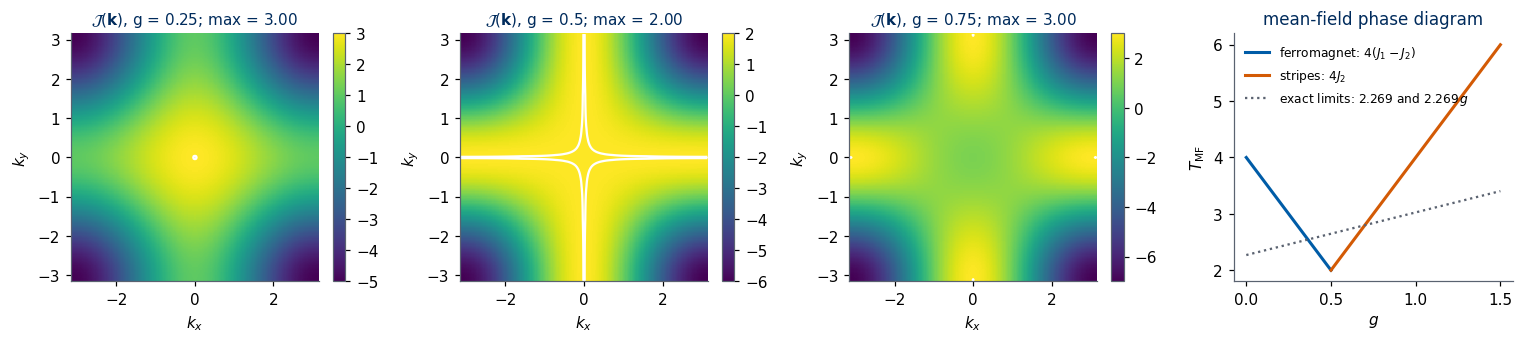

In [19]:
k = np.linspace(-np.pi, np.pi, 201); KX, KY = np.meshgrid(k, k, indexing="ij")
Jk_num = lambda g: 2 * (np.cos(KX) + np.cos(KY)) - 4 * g * np.cos(KX) * np.cos(KY)
fig, ax = plt.subplots(1, 4, figsize=(14, 3.2))
for a, gv in zip(ax[:3], (0.25, 0.5, 0.75)):
    Z = Jk_num(gv)
    im = a.pcolormesh(KX, KY, Z, cmap="viridis", shading="auto")
    a.contour(KX, KY, Z, levels=[Z.max() - 1e-3], colors="w", linewidths=1.5)
    a.set_title(f"$\\mathcal{{J}}(\\mathbf{{k}})$, g = {gv}; max = {Z.max():.2f}", fontsize=10)
    a.set_xlabel("$k_x$"); a.set_ylabel("$k_y$"); a.set_aspect("equal"); plt.colorbar(im, ax=a, fraction=0.046)
gl = np.linspace(0, 1.5, 301)
ax[3].plot(gl[gl <= 0.5], 4 * (1 - gl[gl <= 0.5]), color=UJBlue, lw=2, label="ferromagnet: $4(J_1-J_2)$")
ax[3].plot(gl[gl >= 0.5], 4 * gl[gl >= 0.5], color=DSOrange, lw=2, label="stripes: $4J_2$")
ax[3].plot([0, 1.5], [TC_ISING, 1.5 * TC_ISING], ":", color=UJGray, label="exact limits: $2.269$ and $2.269\\,g$")
ax[3].set_xlabel("$g$"); ax[3].set_ylabel("$T_{\\rm MF}$"); ax[3].legend(frameon=False, fontsize=8); ax[3].set_title("mean-field phase diagram")
plt.tight_layout(); plt.show()

The figure shows the V-shaped mean-field transition line, and the theory fails in three respects. The first is an overestimate of $T_c$: at $g=0$ mean field predicts $4J_1$ instead of $2.269J_1$ (a factor $1.76$); for $g\to\infty$, $4J_2$ instead of $2.269J_2$. Mean field neglects the correlations
between a spin and its neighbours: in reality the neighbours fluctuate together with the spin, ordered patches form and disappear, and these fluctuations lower $T_c$. In two
dimensions they are strong.

The second failure is the point $g=1/2$. Mean field predicts $T_{\rm MF}=2J_1$ there, the lowest point of the V but still a finite temperature. The truth is $T_c\to0$ (Sections 4, 8, 9). The white contour shows the reason: at $g=1/2$ the maximum of
$\mathcal J(\boldsymbol k)$ is reached on the two lines $k_x=0$ and $k_y=0$, $2L-1$ wave vectors on an $L\times L$ torus (the multiplicity $23=2\cdot12-1$ printed above). A mode $(0,k_y)$ is a
pattern uniform along $x$ with an arbitrary profile along $y$: the row-flip degeneracy of Section 3.5. Mean field picks one mode and orders it; in reality the system fluctuates between
all of them, and no order survives at $T>0$.

The third failure concerns the nature of the transition. Mean field always gives a continuous transition with $\beta=1/2$. The true ferromagnetic transition has the 2D Ising exponents, and the stripe
transition is weakly first order or Ashkin–Teller-like (Section 10).

Mean field thus identifies the two ordered phases and the special role of $g=1/2$ — the degenerate maximum of $\mathcal J(\boldsymbol k)$ — but turns it into the wrong
prediction: fluctuations are the essence of the problem.

<hr/>
## 7. Monte Carlo and the static structure factor

The exact methods so far either work at $T=0$ (Section 3) or neglect fluctuations (Section 6). To see the phases at finite temperature on a large lattice we sample the
Boltzmann distribution with Monte Carlo. The snapshots also give the **static structure factor**, the quantity measured by neutron or X-ray scattering, which identifies the ordering pattern without
knowing it in advance.

### 7.1 Four-sublattice Metropolis sampler

We use the Metropolis algorithm of Lab 010: propose flipping spin $i$ and accept it with probability $\min(1,e^{-\beta\Delta E_i})$, where
$$
\Delta E_i = 2s_ih_i,\qquad h_i = J_1\sum_{j\in\rm nn(i)}s_j - J_2\sum_{j\in\rm diag(i)}s_j .
$$
This choice satisfies detailed balance, $p(\mathbf s)P(\mathbf s\to\mathbf s')=p(\mathbf s')P(\mathbf s'\to\mathbf s)$, so the Boltzmann distribution is stationary.

Spins that are not coupled to each other can be updated simultaneously. The chessboard decomposition used for the Ising model fails here, because diagonal neighbours have the same
chessboard colour. The four sublattices $(x\bmod2,\,y\bmod2)$ work instead: nearest neighbours differ in one parity, diagonal neighbours in both, so no two spins of one sublattice interact
(for $L$ even and $L\ge4$). One **sweep** updates the four sublattices in turn, which amounts to one attempted flip per spin.

This suggests storing a configuration directly as its four sublattices, a tuple `S` of four arrays `S[2a+b] = s[a::2, b::2]`, each of shape $(C, L/2, L/2)$ for $C$ chains. The neighbours of a spin
of sublattice $(a,b)$ lie on the other three sublattices: its two horizontal neighbours on $(1-a,b)$, its two vertical neighbours on $(a,1-b)$, its four diagonal neighbours on $(1-a,1-b)$. With
`nsum(X, a, axis)` $=X+$ `roll`$(X,\pm1)$ (sign $+$ for $a=0$, $-$ for $a=1$) the local field is
`h = nsum(S[1-a,b], a, x) + nsum(S[a,1-b], b, y) - g * nsum(nsum(S[1-a,1-b], a, x), b, y)`.
No work is wasted on spins that are not being updated, and all chains are processed by the same array operations.

In JAX the sampler is a pure function `sweep(S, key, g, beta)`; `lax.scan` repeats sweeps inside one compiled program, and `jax.jit` compiles the whole simulation. The chains form the leading axis of every
array (equivalent to `jax.vmap` over chains, written out explicitly); each chain has its own $g$ and its own temperature **schedule**: `T_sched` has shape $(n_{\rm steps}, C)$, and at step $k$ chain $c$ runs
`n_equil` sweeps of equilibration at temperature `T_sched[k, c]` followed by `n_meas` measurements separated by `n_between` sweeps. A decreasing schedule anneals the chains; a schedule with one row runs
every chain at its own fixed temperature. Each measurement is the vector $(m,m_x,m_y,e)$, and with `keep=True` the configurations are stored as well. The input `S0` consists of four arrays
of shape $(C,L/2,L/2)$, `g` has shape $(C,)$ and `T_sched` shape $(n_{\rm steps},C)$; the output measurements have shape $(n_{\rm steps}, n_{\rm meas}, C, 4)$ and,
with `keep=True`, the configurations shape $(n_{\rm steps}, n_{\rm meas}, C, L, L)$, stored as `int8`. The cell ends by checking the sublattice layout against
a plain NumPy implementation.

In [20]:
def nsum(X, a, axis):
    # X plus its copy shifted by one site along axis; for a = 0 the partner sites are i and i-1, for a = 1 they are i and i+1
    return X + jnp.roll(X, 1 if a == 0 else -1, axis)

def sublattice_field(S, a, b, g):
    # local field h on sublattice (a, b): nearest neighbours minus g times diagonal neighbours; shape (C, L/2, L/2)
    return (nsum(S[2 * (1 - a) + b], a, 1) + nsum(S[2 * a + 1 - b], b, 2)
            - g * nsum(nsum(S[2 * (1 - a) + 1 - b], a, 1), b, 2))

def sweep(S, key, g, beta):
    # one Metropolis sweep of all chains; g, beta: (C, 1, 1)
    S = list(S)
    for a, b in ((0, 0), (0, 1), (1, 0), (1, 1)):
        key, sub = jax.random.split(key)
        si = S[2 * a + b]
        dE = 2.0 * si * sublattice_field(S, a, b, g)
        accept = jax.random.uniform(sub, si.shape) < jnp.exp(-beta * dE)
        S[2 * a + b] = jnp.where(accept, -si, si)
    return tuple(S), key

def measure(S, g):
    # (m, m_x, m_y, e) per chain, shape (C, 4); g: (C,); the sign of (-1)^x on sublattice (a, b) is (-1)^a
    s00, s01, s10, s11 = S
    g = jnp.reshape(g, (-1, 1, 1))
    mean = lambda X: X.mean((1, 2)) / 4
    m, mx, my = mean(s00 + s01 + s10 + s11), mean(s00 + s01 - s10 - s11), mean(s00 - s01 + s10 - s11)
    e = -0.5 * sum(mean(S[2 * a + b] * sublattice_field(S, a, b, g)) for a in (0, 1) for b in (0, 1))   # each bond twice
    return jnp.stack([m, mx, my, e], 1)

def assemble(S):
    # four sublattices (C, L/2, L/2) -> full configurations (C, L, L), s[c, 2i+a, 2j+b] = S[2a+b][c, i, j]
    X = jnp.stack(S)                                         # (4, C, h, h)
    C, h = X.shape[1], X.shape[2]
    return X.reshape(2, 2, C, h, h).transpose(2, 3, 0, 4, 1).reshape(C, 2 * h, 2 * h)

def split(s):
    # full configurations (C, L, L) -> tuple of four sublattices
    return tuple(jnp.asarray(s[:, a::2, b::2], jnp.float32) for a in (0, 1) for b in (0, 1))

@partial(jax.jit, static_argnames=("n_equil", "n_meas", "n_between", "keep"))
def simulate(S0, key, g, T_sched, n_equil, n_meas, n_between, keep=False):
    g = g[:, None, None]
    def at_step(carry, T):
        beta = (1.0 / T)[:, None, None]
        step = lambda c, _: (sweep(c[0], c[1], g, beta), None)
        carry, _ = lax.scan(step, carry, None, length=n_equil)
        def record(c, _):
            c, _ = lax.scan(step, c, None, length=n_between)
            obs = measure(c[0], g[:, 0, 0])
            return c, ((obs, assemble(c[0]).astype(jnp.int8)) if keep else (obs,))
        return lax.scan(record, carry, None, length=n_meas)
    return lax.scan(at_step, (S0, key), T_sched)[1]

def run_mc(s0, g, T_sched, n_equil, n_meas, n_between, seed, keep=False):
    # s0: (C, L, L) initial configurations; g: (C,); T_sched: (n_steps, C). Returns numpy arrays (see shapes above).
    out = simulate(split(np.asarray(s0)), jax.random.PRNGKey(seed), jnp.asarray(g, jnp.float32),
                   jnp.asarray(T_sched, jnp.float32), n_equil, n_meas, n_between, keep)
    return tuple(np.asarray(o) for o in out) if keep else np.asarray(out[0])

def random_configs(C, L, seed):
    return np.random.default_rng(seed).choice([-1.0, 1.0], size=(C, L, L))

# consistency of the sublattice layout: assemble(split(s)) = s, and measure() agrees with the numpy functions of Sections 2-3
s_test = random_configs(6, 8, 0)
assert np.array_equal(np.asarray(assemble(split(s_test))), s_test)
obs = np.asarray(measure(split(s_test), jnp.full(6, 0.37)))
o_np = order_params(s_test)
assert np.allclose(obs[:, 0], o_np["m"]) and np.allclose(obs[:, 1], o_np["mx"]) and np.allclose(obs[:, 2], o_np["my"])
assert np.allclose(obs[:, 3], energy(s_test, 0.37) / 64, atol=1e-5)
print("sublattice layout: assemble/split round trip and (m, m_x, m_y, e) agree with the numpy reference")

sublattice layout: assemble/split round trip and (m, m_x, m_y, e) agree with the numpy reference


Before using the sampler for physics we compare it with exact enumeration. On the $4\times4$ torus the exact averages of $e$, $|m|$ and $m_{\rm str}=\sqrt{m_x^2+m_y^2}$ follow from the $2^{16}$ configurations of Section 3.3,
$\langle A\rangle=\sum_{\mathbf s}A(\mathbf s)e^{-\beta H(\mathbf s)}/Z$. The Monte Carlo averages use 512 chains per point (all five points in one batch of $C=2560$ chains), and the error bar is the standard
error over chains. The Monte Carlo value and the exact value should agree within a few error bars at every point.

In [21]:
o44 = order_params(S44)
m_abs_44, mstr_44 = np.abs(o44["m"]), np.hypot(o44["mx"], o44["my"])
def exact_4x4(g, T):
    E = -B1_44 + g * B2_44
    w = np.exp(-(E - E.min()) / T); w /= w.sum()
    return (w * E / 16).sum(), (w * m_abs_44).sum(), (w * mstr_44).sum()

checks = [(0.0, 2.0), (0.3, 1.2), (0.5, 0.6), (0.75, 1.0), (1.5, 3.0)]
n_ch = 512
g_chk = np.repeat([c[0] for c in checks], n_ch); T_chk = np.repeat([c[1] for c in checks], n_ch)[None, :]
t0 = time.perf_counter()
meas = run_mc(random_configs(len(g_chk), 4, 1), g_chk, T_chk, n_equil=1000, n_meas=100, n_between=4, seed=11)[0]   # (100, 2560, 4)
for k, (gv, T) in enumerate(checks):
    mk = meas[:, k * n_ch:(k + 1) * n_ch]                                           # (100, 512, 4)
    per_chain = np.stack([mk[..., 3].mean(0), np.abs(mk[..., 0]).mean(0), np.hypot(mk[..., 1], mk[..., 2]).mean(0)], 1)
    mc, err = per_chain.mean(0), per_chain.std(0) / np.sqrt(n_ch)
    ex = exact_4x4(gv, T)
    print(f"g = {gv:4.2f}, T = {T}:  " + "   ".join(f"{n} MC {a:+.4f}({b:.4f}) exact {c:+.4f}" for n, a, b, c in zip(["e", "|m|", "m_str"], mc, err, ex)))
print(f"({time.perf_counter() - t0:.1f} s)")

g = 0.00, T = 2.0:  e MC -1.7560(0.0018) exact -1.7554   |m| MC +0.9194(0.0007) exact +0.9189   m_str MC +0.0687(0.0005) exact +0.0691
g = 0.30, T = 1.2:  e MC -1.2541(0.0013) exact -1.2528   |m| MC +0.8889(0.0014) exact +0.8868   m_str MC +0.0735(0.0007) exact +0.0744
g = 0.50, T = 0.6:  e MC -0.9879(0.0004) exact -0.9881   |m| MC +0.3357(0.0060) exact +0.3321   m_str MC +0.3950(0.0074) exact +0.4005
g = 0.75, T = 1.0:  e MC -1.4758(0.0005) exact -1.4755   |m| MC +0.0079(0.0002) exact +0.0078   m_str MC +0.9895(0.0003) exact +0.9893
g = 1.50, T = 3.0:  e MC -2.6468(0.0026) exact -2.6509   |m| MC +0.0382(0.0003) exact +0.0377   m_str MC +0.9368(0.0005) exact +0.9375
(6.8 s)


### 7.2 Static structure factor

The agreement is good at all five points, so we can trust the sampler on larger lattices. For a configuration $\mathbf s$ define the Fourier amplitude $\hat s(\boldsymbol k)=\sum_{\boldsymbol r}s_{\boldsymbol r}e^{-i\boldsymbol k\cdot\boldsymbol r}$ on the $L^2$ wave vectors
$\boldsymbol k=\frac{2\pi}{L}(n_x,n_y)$. The static structure factor is
$$
\begin{aligned}
S(\boldsymbol k) &= \frac1N\big\langle|\hat s(\boldsymbol k)|^2\big\rangle = N\big\langle|m_{\boldsymbol k}|^2\big\rangle\\
&= \sum_{\boldsymbol r}e^{-i\boldsymbol k\cdot\boldsymbol r}\,\frac1N\sum_{\boldsymbol r'}\langle s_{\boldsymbol r'}s_{\boldsymbol r'+\boldsymbol r}\rangle ,
\end{aligned}
$$
the Fourier transform of the spin–spin correlation function and the quantity a scattering experiment measures.

In a phase with long-range order at wave vector $\boldsymbol Q$, $\langle|m_{\boldsymbol Q}|^2\rangle$ stays finite as $N\to\infty$, so $S(\boldsymbol Q)\propto N$: a **Bragg peak**. In the paramagnet
correlations decay over a finite length and $S(\boldsymbol k)$ is a broad, $N$-independent function. Parseval's theorem adds a sum rule: $\sum_{\boldsymbol k}|\hat s(\boldsymbol k)|^2=N\sum_{\boldsymbol r}s_{\boldsymbol r}^2=N^2$, so the average of
$S(\boldsymbol k)$ over the Brillouin zone is exactly $1$, and ordering only redistributes the weight.

We compute $S(\boldsymbol k)$ with `np.fft.fft2` from Monte Carlo snapshots ($L=32$, 16 annealed chains $\times$ 20 snapshots per point, all four points in one batch) in four situations: the ferromagnet, the paramagnet, the frustrated point
$g=1/2$ at low $T$, and the stripe phase.

ferromagnet     (g = 0.25, T = 1.0):  mean of S(k) over k = 1.000000 (sum rule: 1);   S(0,0) = 1004.65,  S(pi,0) =    0.02,  S(0,pi) =    0.02,  S(pi,pi) =   0.01   (N = 1024)
paramagnet      (g = 0.25, T = 3.0):  mean of S(k) over k = 1.000000 (sum rule: 1);   S(0,0) =    3.54,  S(pi,0) =    0.86,  S(0,pi) =    1.07,  S(pi,pi) =   0.33   (N = 1024)
g = 1/2, low T  (g = 0.5, T = 0.3):  mean of S(k) over k = 1.000000 (sum rule: 1);   S(0,0) =   25.81,  S(pi,0) =    1.32,  S(0,pi) =    1.95,  S(pi,pi) =   0.01   (N = 1024)
stripes         (g = 0.75, T = 0.8):  mean of S(k) over k = 1.000000 (sum rule: 1);   S(0,0) =    0.00,  S(pi,0) =  638.27,  S(0,pi) =  382.89,  S(pi,pi) =   0.00   (N = 1024)
(14.5 s)


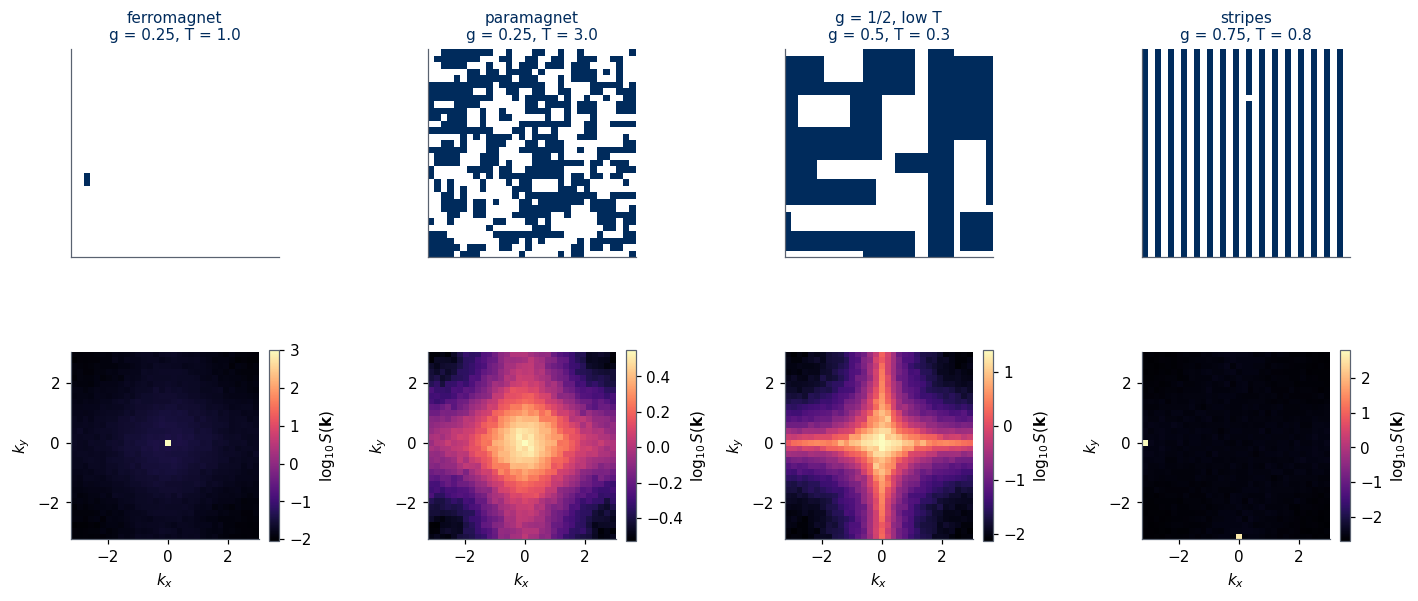

In [22]:
L_sk = 32
cases = [(0.25, 1.0, "ferromagnet"), (0.25, 3.0, "paramagnet"), (0.5, 0.3, "g = 1/2, low T"), (0.75, 0.8, "stripes")]
n_ch, n_steps = 16, 12
# every chain is cooled linearly from T = 4 to its target temperature in n_steps steps; snapshots are kept at the last step
g_sk = np.repeat([c[0] for c in cases], n_ch)                                          # (64,)
lam_sk = np.linspace(0.0, 1.0, n_steps)[:, None]                                       # interpolation parameter, (12, 1)
T_sk = (1 - lam_sk) * 4.0 + lam_sk * np.repeat([c[1] for c in cases], n_ch)[None, :]   # (12, 64): from T = 4 to the target
t0 = time.perf_counter()
meas, conf = run_mc(random_configs(len(g_sk), L_sk, 2), g_sk, T_sk, n_equil=200, n_meas=20, n_between=10, seed=21, keep=True)
Sk, snaps = {}, {}
for k, (gv, T, name) in enumerate(cases):
    c = conf[-1, :, k * n_ch:(k + 1) * n_ch].reshape(-1, L_sk, L_sk).astype(np.float64)   # (320, 32, 32) snapshots at the target T
    Sk[name] = (np.abs(np.fft.fft2(c)) ** 2).mean(0) / L_sk**2                          # S(k) on the 32 x 32 grid of wave vectors
    snaps[name] = c[-1]
    print(f"{name:15s} (g = {gv}, T = {T}):  mean of S(k) over k = {Sk[name].mean():.6f} (sum rule: 1);   "
          f"S(0,0) = {Sk[name][0, 0]:7.2f},  S(pi,0) = {Sk[name][L_sk//2, 0]:7.2f},  S(0,pi) = {Sk[name][0, L_sk//2]:7.2f},  "
          f"S(pi,pi) = {Sk[name][L_sk//2, L_sk//2]:6.2f}   (N = {L_sk**2})")
print(f"({time.perf_counter() - t0:.1f} s)")

kgrid = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(L_sk))
fig, ax = plt.subplots(2, 4, figsize=(13, 6.2))
for j, (gv, T, name) in enumerate(cases):
    ax[0, j].imshow(snaps[name].T, cmap=SPIN_CMAP, vmin=-1, vmax=1, origin="lower"); ax[0, j].set_xticks([]); ax[0, j].set_yticks([])
    ax[0, j].set_title(f"{name}\ng = {gv}, T = {T}", fontsize=10)
    im = ax[1, j].pcolormesh(kgrid, kgrid, np.log10(np.fft.fftshift(Sk[name]).T), cmap="magma", shading="nearest")
    ax[1, j].set_xlabel("$k_x$"); ax[1, j].set_ylabel("$k_y$"); ax[1, j].set_aspect("equal")
    plt.colorbar(im, ax=ax[1, j], fraction=0.046, label=r"$\log_{10}S(\mathbf{k})$")
plt.tight_layout(); plt.show()

The sum rule holds to all printed digits, and the four maps look as the theory predicts. The ferromagnet shows one Bragg peak at $\boldsymbol k=(0,0)$
of height comparable to $N$ ($S(0,0)\approx1005$ for $N=1024$). The paramagnet has a broad maximum around $(0,0)$ of height of order one ($3.5$) —
short-range ferromagnetic correlations, no order. In the stripe phase the peaks sit at $(\pi,0)$ and $(0,\pi)$; the map averages over chains, which may have
chosen different orientations, so both peaks appear. At $g=1/2$ and low $T$ the weight concentrates on the **lines** $k_x=0$ and $k_y=0$. These are the
modes of the degenerate ground-state manifold (rows or columns with independent signs, Section 3.5) and the lines on which $\mathcal J(\boldsymbol k)$ is maximal (Section 6). The snapshot shows domains of rows or columns, not a single ordered pattern.

The structure factor thus identifies the ordering wave vector without prior knowledge: a point peak for long-range order, a line of weight for the frustrated point. Lab 020 asks
an algorithm to make the same distinction from raw snapshots.

<hr/>
## 8. Transfer matrices of infinite strips

Monte Carlo has statistical errors and needs equilibration. For a strip of finite width $L$ and **infinite** length the free energy can be computed exactly
from the largest eigenvalue of the row transfer matrix — the method of Lab 012, here with diagonal bonds. The results are exact for each $L$, and the limit $L\to\infty$ is approached through
a sequence of widths.

With the row-pair energy $W(\sigma,\sigma')$ of Section 3.4 the transfer matrix is
$$
\begin{aligned}
\mathsf V_{\sigma\sigma'} &= e^{-\beta W(\sigma,\sigma')}\\
&= \exp\Big\{\beta\Big[J_1\sum_xs_xs'_x - J_2\sum_xs_x\big(s'_{x+1}+s'_{x-1}\big) + \frac{J_1}{2}\sum_x\big(s_xs_{x+1}+s'_xs'_{x+1}\big)\Big]\Big\},
\end{aligned}
$$
a $2^L\times2^L$ matrix. It is **symmetric** ($\sum_xs_x(s'_{x+1}+s'_{x-1})=\sum_xs'_x(s_{x-1}+s_{x+1})$) and has positive entries. For a strip of length $M\to\infty$, $Z=\operatorname{Tr}\mathsf V^M\simeq\lambda_0^M$, so
$$
f_L(T) = -\frac{T}{L}\ln\lambda_0,\qquad \xi_L = \frac{1}{\ln(\lambda_0/|\lambda_1|)},
$$
where $\lambda_0$ is the largest eigenvalue (positive and non-degenerate by the Perron–Frobenius theorem) and $\lambda_1$ the eigenvalue of largest modulus among the eigenvectors **odd** under the
global spin flip — the ones that carry the spin–spin correlation along the strip, $\langle s_0s_r\rangle\sim(|\lambda_1|/\lambda_0)^r$. The modulus matters here: horizontal stripes (rows alternately $+$ and $-$)
appear as a negative eigenvalue $\lambda_1\approx-\lambda_0$.

The spin-flip symmetry halves the work. The flip $\sigma\to-\sigma$ maps the index $n\to2^L-1-n$ and commutes with $\mathsf V$. With $\mathsf V^{\pm}_{ab}=\mathsf V_{ab}\pm\mathsf V_{a,\bar b}$ for $a,b<2^{L-1}$
(Lab 012), the even and odd sectors are two symmetric matrices of half the size.

As a first test, $Z$ of the $4\times4$ torus is $\operatorname{Tr}\mathsf V^4$ and must equal the enumeration of Section 3.3 at any $(g,T)$.

In [23]:
_row_cache = {}
def log_V(L, J1, J2, T):
    # ln V[sigma, sigma'] = -W(sigma, sigma') / T, shape (2^L, 2^L)
    if L not in _row_cache:
        _row_cache[L] = row_terms(L)
    intra, nn, dd = _row_cache[L]
    return (J1 * nn - J2 * dd + 0.5 * J1 * (intra[:, None] + intra[None, :])) / T

def top_eig(A, which):
    # largest algebraic ("LA") or largest-modulus ("LM") eigenvalue of a symmetric matrix
    n = A.shape[0]
    if n <= 512:
        w = eigh(A, eigvals_only=True)
        return w[-1] if which == "LA" else w[np.argmax(np.abs(w))]
    return eigsh(A, k=1, which=which, tol=0)[0][0]

def strip_eigs(L, J1, J2, T, odd=True):
    # ln(lambda_0) and ln|lambda_1| of the strip of width L (lambda_1 only if odd=True)
    lv = log_V(L, J1, J2, T)
    shift = lv.max()
    V = np.exp(lv - shift)                                 # rescaled to avoid overflow; ln lambda = ln(eig) + shift
    n = V.shape[0] // 2
    Vf = V[:n, ::-1][:, :n]                                # V[a, flip(b)] for a, b < 2^(L-1)
    l0 = np.log(top_eig(V[:n, :n] + Vf, "LA")) + shift
    l1 = np.log(abs(top_eig(V[:n, :n] - Vf, "LM"))) + shift if odd else np.nan
    return l0, l1

# check against enumeration: Z(4x4 torus) = Tr V^4
for gv, T in [(0.0, 2.0), (0.4, 1.0), (0.5, 0.5), (0.8, 1.5)]:
    V = np.exp(log_V(4, 1.0, gv, T))
    lnZ_tm = np.log(np.trace(np.linalg.matrix_power(V, 4)))
    E = -B1_44 + gv * B2_44
    lnZ_ex = -E.min() / T + np.log(np.exp(-(E - E.min()) / T).sum())
    print(f"g = {gv}, T = {T}:  ln Z (Tr V^4) = {lnZ_tm:.12f}   ln Z (enumeration) = {lnZ_ex:.12f}")

g = 0.0, T = 2.0:  ln Z (Tr V^4) = 17.105367118732   ln Z (enumeration) = 17.105367118732
g = 0.4, T = 1.0:  ln Z (Tr V^4) = 20.674104624930   ln Z (enumeration) = 20.674104624930
g = 0.5, T = 0.5:  ln Z (Tr V^4) = 35.413347113679   ln Z (enumeration) = 35.413347113679
g = 0.8, T = 1.5:  ln Z (Tr V^4) = 18.855217461352   ln Z (enumeration) = 18.855217461352


### 8.1 Free energy, specific heat and residual entropy

The two values of $\ln Z$ agree to twelve digits. For widths $L=4,6,8,10$ and several $g$ we compute $f_L(T)$ on a fine grid and the specific heat $c_L=-T\,\partial^2f_L/\partial T^2$ by finite differences (the eigenvalues are accurate to
machine precision, so second differences are reliable). The results are stored in `strip_f[(g, L)]` and `strip_c[(g, L)]`, each of shape $(n_T,)$. In the figure, watch how the specific-heat maximum moves as $g$ approaches $1/2$.

strip free energies: 245.8 s


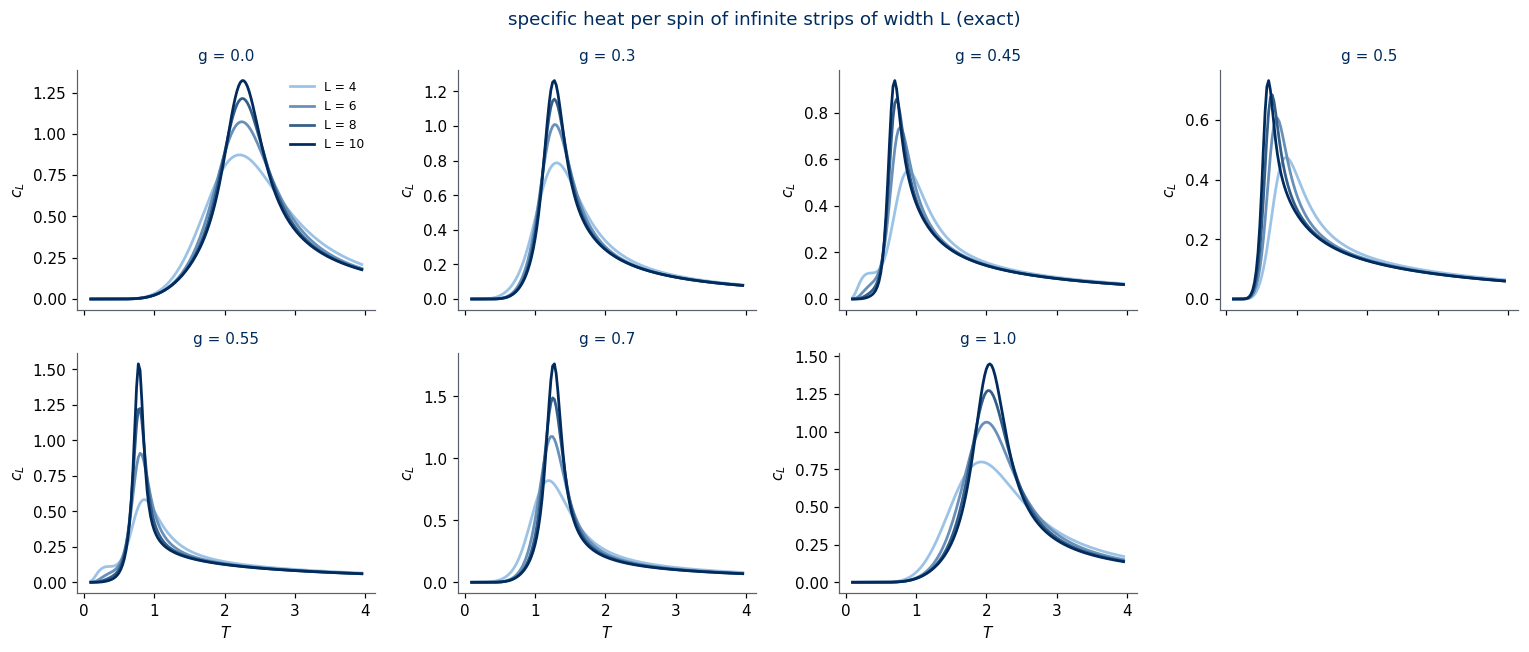

g = 0.00, L = 10:  maximum of c_L = 1.322 at T = 2.250
g = 0.30, L = 10:  maximum of c_L = 1.263 at T = 1.275
g = 0.45, L = 10:  maximum of c_L = 0.938 at T = 0.700
g = 0.50, L = 10:  maximum of c_L = 0.732 at T = 0.600
g = 0.55, L = 10:  maximum of c_L = 1.539 at T = 0.775
g = 0.70, L = 10:  maximum of c_L = 1.762 at T = 1.275
g = 1.00, L = 10:  maximum of c_L = 1.450 at T = 2.050


In [24]:
g_curves = [0.0, 0.3, 0.45, 0.5, 0.55, 0.7, 1.0]
L_curves = [4, 6, 8, 10]
T_fine = np.linspace(0.05, 4.0, 159); dT = T_fine[1] - T_fine[0]
strip_f, strip_c = {}, {}
t0 = time.perf_counter()
for gv in g_curves:
    for L in L_curves:
        l0 = np.array([strip_eigs(L, 1.0, gv, T, odd=False)[0] for T in T_fine])
        strip_f[(gv, L)] = -T_fine * l0 / L
        strip_c[(gv, L)] = -T_fine * np.gradient(np.gradient(strip_f[(gv, L)], dT), dT)
print(f"strip free energies: {time.perf_counter() - t0:.1f} s")

fig, ax = plt.subplots(2, 4, figsize=(14, 6), sharex=True)
for a, gv in zip(ax.ravel(), g_curves):
    for i, L in enumerate(L_curves):
        a.plot(T_fine[2:-2], strip_c[(gv, L)][2:-2], color=blues(i / (len(L_curves) - 1)), lw=1.8, label=f"L = {L}")
    a.set_title(f"g = {gv}", fontsize=10); a.set_ylabel("$c_L$")
ax[1, 3].axis("off")
for a in ax[1]: a.set_xlabel("$T$")
ax[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle("specific heat per spin of infinite strips of width L (exact)", color=UJNavy)
plt.tight_layout(); plt.show()
for gv in g_curves:
    c = strip_c[(gv, L_curves[-1])][2:-2]
    print(f"g = {gv:4.2f}, L = {L_curves[-1]}:  maximum of c_L = {c.max():.3f} at T = {T_fine[2:-2][c.argmax()]:.3f}")

The strip free energy also reveals a residual entropy at $g=1/2$. For $T\to0$ only the ground states contribute: $\lambda_0^M\simeq n_0\,e^{-\beta E_0}$ with $E_0=-J_1LM$ at $g=1/2$. Section 3.5 gives $n_0\simeq2^M$ for a long strip (each row
uniform with a free sign), so
$$
\lambda_0\,e^{-\beta J_1 L}\xrightarrow{T\to0}2,\qquad s_L(T\to0) = \frac{\ln2}{L}\ \text{per spin}.
$$
For $g\neq1/2$ the ground states are a fixed finite number and the same ratio (with the corresponding $E_0$) tends to $1$, i.e. zero entropy. The entropy per spin follows from
the free energy as $s=(u-f)/T$ with $u=\partial(\beta f)/\partial\beta = f - T\,\partial f/\partial T$, so $s=-\partial f/\partial T$. The cell evaluates the ratio and the entropy at low
temperature for $g=0.3$, $0.5$ and $0.7$.

In [25]:
for gv in (0.3, 0.5, 0.7):
    e0_row = min(-2 + 2 * gv, -2 * gv)                                  # ground-state energy per spin
    for L in (6, 8, 10):
        ratios = [np.exp(strip_eigs(L, 1.0, gv, T, odd=False)[0] + e0_row * L / T) for T in (0.1, 0.05, 0.03)]
        s_low = -np.gradient(strip_f[(gv, L)], dT)[2]                   # s = -df/dT at T = T_fine[2]
        print(f"g = {gv}, L = {L:2d}:  lambda_0 exp(E0_row/T) at T = 0.1, 0.05, 0.03: {np.round(ratios, 6)}"
              f"   s(T = {T_fine[2]:.3f}) = {s_low:.5f}   ln2/L = {np.log(2) / L:.5f}")

g = 0.3, L =  6:  lambda_0 exp(E0_row/T) at T = 0.1, 0.05, 0.03: [1. 1. 1.]   s(T = 0.100) = -0.00000   ln2/L = 0.11552
g = 0.3, L =  8:  lambda_0 exp(E0_row/T) at T = 0.1, 0.05, 0.03: [1. 1. 1.]   s(T = 0.100) = -0.00000   ln2/L = 0.08664


g = 0.3, L = 10:  lambda_0 exp(E0_row/T) at T = 0.1, 0.05, 0.03: [1. 1. 1.]   s(T = 0.100) = -0.00000   ln2/L = 0.06931
g = 0.5, L =  6:  lambda_0 exp(E0_row/T) at T = 0.1, 0.05, 0.03: [2. 2. 2.]   s(T = 0.100) = 0.11552   ln2/L = 0.11552
g = 0.5, L =  8:  lambda_0 exp(E0_row/T) at T = 0.1, 0.05, 0.03: [2. 2. 2.]   s(T = 0.100) = 0.08664   ln2/L = 0.08664


g = 0.5, L = 10:  lambda_0 exp(E0_row/T) at T = 0.1, 0.05, 0.03: [2. 2. 2.]   s(T = 0.100) = 0.06931   ln2/L = 0.06931
g = 0.7, L =  6:  lambda_0 exp(E0_row/T) at T = 0.1, 0.05, 0.03: [1. 1. 1.]   s(T = 0.100) = -0.00000   ln2/L = 0.11552
g = 0.7, L =  8:  lambda_0 exp(E0_row/T) at T = 0.1, 0.05, 0.03: [1. 1. 1.]   s(T = 0.100) = -0.00000   ln2/L = 0.08664


g = 0.7, L = 10:  lambda_0 exp(E0_row/T) at T = 0.1, 0.05, 0.03: [1. 1. 1.]   s(T = 0.100) = -0.00000   ln2/L = 0.06931


The ratio is exactly $2$ at $g=1/2$ and $1$ at $g=0.3$ and $0.7$: at $g=1/2$ the strip keeps an entropy $\ln2/L$ per spin down to $T=0$, the transfer-matrix version of the degeneracy $2^M$, while away from $g=1/2$ the entropy vanishes. For $g$ near $1/2$ the
maximum of $c_L$ moves to lower temperature ($T\approx0.6$–$0.8$ for $L=10$ at $g=0.45,0.5,0.55$), but at $g=1/2$ it does not disappear, although there is no transition there: the strip
specific heat also counts local excitations (a single flipped spin costs $4J_1$ at $g=1/2$, Exercise 1), so a peak of $c_L$ alone does not prove a phase transition.

### 8.2 Transition temperature from the strips

For each $g$ the position $T_{\max}(g)$ of the maximum of $c_L$ is a finite-size indicator of the transition (Lab 012: for the Ising model it approaches $T_c$ slowly). A sharper indicator is the correlation length. Above $T_c$, $\xi_L$ saturates as $L$ grows, so $\xi_L/L$ decreases with $L$; below $T_c$ the ordered states become degenerate, $|\lambda_1|\to\lambda_0$, and
$\xi_L/L$ increases with $L$. The temperature $T^*(L,L+2)$ where $\xi_L/L=\xi_{L+2}/(L+2)$ therefore estimates $T_c$, and it converges fast for the Ising model (Lab 012). We solve for the crossing
with `brentq` in a bracket found on a coarse grid, for widths up to $L=12$ ($2^{12}\times2^{12}$ matrices); where no crossing exists in the bracket the table prints `none`.

In [26]:
def xi_over_L(L, J1, J2, T):
    l0, l1 = strip_eigs(L, J1, J2, T)
    return 1.0 / (l0 - l1) / L

def crossing(L, J1, J2, T_lo, T_hi, n_grid=12):
    # temperature where xi_L/L = xi_{L+2}/(L+2), searched in [T_lo, T_hi]; None if no sign change
    F = lambda T: xi_over_L(L, J1, J2, T) - xi_over_L(L + 2, J1, J2, T)
    Tg = np.linspace(T_lo, T_hi, n_grid)
    Fg = np.array([F(T) for T in Tg])
    Fg = np.where(np.isfinite(Fg), Fg, 0.0)
    idx = np.where(Fg[:-1] * Fg[1:] < 0)[0]
    if len(idx) == 0:
        return None
    i = idx[-1]                                                       # the highest-temperature sign change
    return brentq(F, Tg[i], Tg[i + 1], xtol=1e-6)

def T_guess(g):
    # bracket centre from the mean-field shape, used only to place the search window
    return TC_ISING * max(1 - 2 * g, 2 * g - 1, 0.15) if g < 1 else TC_ISING * g

g_cross = [0.0, 0.1, 0.2, 0.3, 0.4, 0.45, 0.55, 0.6, 0.7, 0.8, 1.0, 1.5, 2.0, 4.0]
Tstar = {}
t0 = time.perf_counter()
for gv in g_cross:
    lo, hi = 0.25 * T_guess(gv), 1.6 * T_guess(gv) + 0.3
    for L in (6, 8):
        Tstar[(gv, L)] = crossing(L, 1.0, gv, lo, hi)
print(f"crossings for (6,8) and (8,10): {time.perf_counter() - t0:.1f} s")
t0 = time.perf_counter()
for gv in (0.0, 0.3, 0.7, 1.0, 2.0):                                  # the most expensive pair only for a few g
    ref = Tstar[(gv, 8)]
    Tstar[(gv, 10)] = crossing(10, 1.0, gv, 0.9 * ref, 1.1 * ref, n_grid=4) if ref else None
print(f"crossings for (10,12): {time.perf_counter() - t0:.1f} s")
# g -> infinity: J1 = 0, J2 = 1 (two decoupled sublattices)
Tstar_inf = {L: crossing(L, 0.0, 1.0, 1.5, 3.0) for L in (6, 8)}

fmt = lambda v: f"{v:8.4f}" if v is not None else "    none"
print("\n     g    T*(6,8)  T*(8,10)  T*(10,12)   T*/g (g >= 1)   mean field")
for gv in g_cross:
    best = Tstar.get((gv, 10)) or Tstar[(gv, 8)] or Tstar[(gv, 6)]
    ratio = f"{best / gv:8.4f}" if (gv >= 1 and best) else "        "
    print(f"  {gv:4.2f}  {fmt(Tstar[(gv, 6)])}  {fmt(Tstar[(gv, 8)])}  {fmt(Tstar.get((gv, 10)))}      {ratio}       {max(4 * (1 - gv), 4 * gv):.3f}")
print(f"J1 = 0 (g -> infinity), T*/J2:  (6,8) {fmt(Tstar_inf[6])}   (8,10) {fmt(Tstar_inf[8])}   exact 2/ln(1+sqrt2) = {TC_ISING:.4f}")

/tmp/ipykernel_4024352/1208935959.py:3: RuntimeWarning: divide by zero encountered in scalar divide
  return 1.0 / (l0 - l1) / L


crossings for (6,8) and (8,10): 118.1 s


crossings for (10,12): 132.1 s



     g    T*(6,8)  T*(8,10)  T*(10,12)   T*/g (g >= 1)   mean field
  0.00    2.2749    2.2717    2.2705                     4.000
  0.10    1.9530    1.9477      none                     3.600
  0.20    1.6226    1.6137      none                     3.200
  0.30    1.2825    1.2658    1.2599                     2.800
  0.40    0.9322    0.9005      none                     2.400
  0.45    0.7438    0.7109      none                     2.200
  0.55    0.7654    0.7741      none                     2.200
  0.60    0.9726    0.9742      none                     2.400
  0.70    1.2877    1.2897    1.2902                     2.800
  0.80    1.5637    1.5667      none                     3.200
  1.00    2.0730    2.0779    2.0798        2.0798       4.000
  1.50    3.2654    3.2745      none        2.1830       6.000
  2.00    4.4224    4.4353    4.4411        2.2205       8.000
  4.00    8.9766    9.0032      none        2.2508       16.000
J1 = 0 (g -> infinity), T*/J2:  (6,8)   2.2570  

specific-heat peaks: 107.5 s


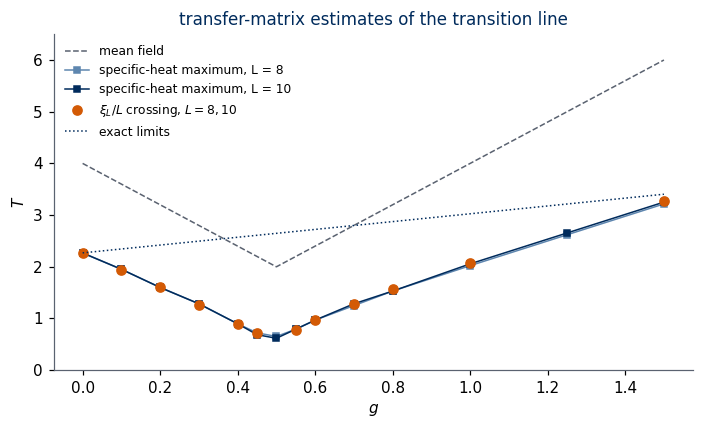

In [27]:
# specific-heat maximum versus g for L = 8 and 10
g_peak = [0.0, 0.1, 0.2, 0.3, 0.4, 0.45, 0.5, 0.55, 0.6, 0.7, 0.8, 1.0, 1.25, 1.5]
T_pk = np.linspace(0.02, 4.2, 120); dTp = T_pk[1] - T_pk[0]
c_peak = {}
t0 = time.perf_counter()
for L in (8, 10):
    for gv in g_peak:
        Tw = T_pk[T_pk < 1.5 * T_guess(gv) + 0.6]
        fL = -Tw * np.array([strip_eigs(L, 1.0, gv, T, odd=False)[0] for T in Tw]) / L
        cL = -Tw * np.gradient(np.gradient(fL, dTp), dTp)
        k = np.argmax(cL[2:-2]) + 2
        c_peak[(gv, L)] = (Tw[k], cL[k])
print(f"specific-heat peaks: {time.perf_counter() - t0:.1f} s")

fig, ax = plt.subplots(figsize=(6.5, 4))
gl = np.linspace(0, 1.5, 301)
ax.plot(gl, np.maximum(4 * (1 - gl), 4 * gl), color=UJGray, lw=1, ls="--", label="mean field")
for i, L in enumerate((8, 10)):
    ax.plot(g_peak, [c_peak[(gv, L)][0] for gv in g_peak], "s-", color=blues(0.4 + 0.6 * i), ms=4, lw=1, label=f"specific-heat maximum, L = {L}")
gx = [gv for gv in g_cross if gv <= 1.5 and Tstar[(gv, 8)] is not None]
ax.plot(gx, [Tstar[(gv, 8)] for gv in gx], "o", color=DSOrange, ms=6, label=r"$\xi_L/L$ crossing, $L = 8, 10$")
ax.plot([0, 1.5], [TC_ISING, 1.5 * TC_ISING], ":", color=UJNavy, lw=1, label="exact limits")
ax.set_xlabel("$g$"); ax.set_ylabel("$T$"); ax.set_ylim(0, 6.5); ax.legend(frameon=False, fontsize=8)
ax.set_title("transfer-matrix estimates of the transition line")
plt.tight_layout(); plt.show()

At $g=0$ the crossings converge to Onsager's $T_c$: the $(10,12)$ value $2.2705$ lies $0.0013$ above the exact $2.2692$. For large $g$, $T^*/g$ grows towards $2.269$ with $g$, and the
decoupled limit $J_1=0$ gives $T^*/J_2$ close to $2.269$ directly. In between, the crossings trace a line far below mean field that dips towards $g=1/2$. At these widths the dip stops at $T^*\approx0.7$
for $g=0.45$ and $0.55$: close to $g=1/2$ the relevant length scales exceed $L\le12$, and Kalz et al. [2008] find from much larger Monte Carlo lattices that the data are consistent with
$T_c\to0$ at $g=1/2$, as the domain-wall argument of Section 4 requires. The specific-heat maximum lies close to the crossings away from $g=1/2$ but stays at a finite temperature at $g=1/2$
itself, where there is no transition.

<hr/>
## 9. Binder cumulants

The strips of Section 8 are exact but narrow ($L\le12$). Monte Carlo reaches larger lattices at the price of statistical errors. A finite lattice has no sharp transition
(Lab 012, Section 1), so we need a quantity whose size dependence changes sign at $T_c$; the **Binder cumulant** is such a quantity [Binder 1981]. For a scalar order
parameter, here the ferromagnetic $m$, it is defined as
$$
U_m = 1-\frac{\langle m^4\rangle}{3\langle m^2\rangle^2}.
$$
In the disordered phase, $L\gg\xi$, $m$ is a sum of many weakly correlated contributions, hence Gaussian by the central limit theorem;
then $\langle m^4\rangle=3\langle m^2\rangle^2$ and $U_m\to0$. In the ordered phase $m\approx\pm m_0$, $\langle m^4\rangle=\langle m^2\rangle^2$ and $U_m\to2/3$.
At $T_c$ the distribution of $m/\sqrt{\langle m^2\rangle}$ has an $L$-independent shape (scale invariance), so $U_m$ takes the same value for all large $L$:
the curves $U_m(T)$ for different $L$ **cross** at $T_c$.

The stripe order parameter has two components $(m_x,m_y)$, and the normalisation must be adapted. For a two-dimensional Gaussian vector $\langle r^4\rangle=2\langle r^2\rangle^2$, and for a vector of fixed length $\langle r^4\rangle=\langle r^2\rangle^2$, so
$$
U_{\rm str} = 2-\frac{\langle m_{\rm str}^4\rangle}{\langle m_{\rm str}^2\rangle^2}
$$
goes from $0$ (disordered) to $1$ (ordered). SymPy verifies the Gaussian moments.

In [28]:
xg, yg, sg = sp.symbols("x y sigma", positive=True)
gauss1 = sp.exp(-xg**2 / (2 * sg**2)) / sp.sqrt(2 * sp.pi * sg**2)
mom = lambda k: sp.integrate(xg**k * gauss1, (xg, -sp.oo, sp.oo))
print("1D Gaussian:  <x^4> / <x^2>^2 =", sp.simplify(mom(4) / mom(2)**2), "  ->  U_m = 1 - 3/3 =", 1 - sp.simplify(mom(4) / mom(2)**2) / 3)
r, ph_ = sp.symbols("r phi", positive=True)
gauss2_r = r * sp.exp(-r**2 / (2 * sg**2)) / (2 * sp.pi * sg**2)          # density in polar coordinates, times the Jacobian r
mom2 = lambda k: sp.integrate(sp.integrate(r**k * gauss2_r, (r, 0, sp.oo)), (ph_, 0, 2 * sp.pi))
print("2D Gaussian:  <r^4> / <r^2>^2 =", sp.simplify(mom2(4) / mom2(2)**2), "  ->  U_str = 2 - 2 =", 2 - sp.simplify(mom2(4) / mom2(2)**2))

1D Gaussian:  <x^4> / <x^2>^2 = 3   ->  U_m = 1 - 3/3 = 0
2D Gaussian:  <r^4> / <r^2>^2 = 2   ->  U_str = 2 - 2 = 0


For the simulations we choose, for each $g$, a temperature window around the transfer-matrix estimate $T^*$ of Section 8.2 and simulate three sizes, $L=16,24,32$, at 8 temperatures with 16 independent chains per $(g,T,L)$;
all $5\times8\times16=640$ chains of one size run in a single batch. Each chain starts in the ordered state and runs at fixed temperature: `n_equil` sweeps of equilibration, then `n_meas`
measurements separated by `n_between` sweeps. Error bars come from a jackknife over chains (leave one block of 2 chains out). The ferromagnetic side uses $U_m$ and the stripe side $U_{\rm str}$; at $g=2$ the comparison with $2.269\,g$ tests the large-$g$ limit of Section 5.

In [29]:
def binder(meas, stripe):
    # meas: (chains, nT, n_meas, 4) -> U(T) and its jackknife error over blocks of chains; shapes (nT,), (nT,)
    q = np.hypot(meas[..., 1], meas[..., 2]) if stripe else meas[..., 0]
    q2, q4 = (q**2).mean(2), (q**4).mean(2)                         # per chain and temperature: (chains, nT)
    U = (lambda a2, a4: 2 - a4 / a2**2) if stripe else (lambda a2, a4: 1 - a4 / (3 * a2**2))
    full = U(q2.mean(0), q4.mean(0))
    blocks = np.array_split(np.arange(q2.shape[0]), 8)
    jk = np.array([U(np.delete(q2, b, 0).mean(0), np.delete(q4, b, 0).mean(0)) for b in blocks])
    err = np.sqrt((len(blocks) - 1) * ((jk - jk.mean(0))**2).mean(0))
    return full, err

def crossing_T(T, Ua, Ub, T_ref):
    # temperature where the interpolated curves Ua(T), Ub(T) cross, the crossing closest to T_ref; None if none
    d = Ua - Ub
    idx = np.where(d[:-1] * d[1:] < 0)[0]
    if len(idx) == 0:
        return None
    Tx = [T[i] - d[i] * (T[i + 1] - T[i]) / (d[i + 1] - d[i]) for i in idx]
    return min(Tx, key=lambda t: abs(t - T_ref))

g_mc = [0.0, 0.3, 0.7, 1.0, 2.0]
L_mc = [16, 24, 32]
n_ch, n_T = 16, 8
MC_SET = dict(n_equil=1500, n_meas=500, n_between=4)
T_ref = {gv: (Tstar.get((gv, 10)) or Tstar[(gv, 8)]) for gv in g_mc}
T_win = {gv: np.linspace(0.9, 1.12, n_T) * T_ref[gv] for gv in g_mc}            # increasing temperature
# one batch per L: chains ordered as (g, T, chain); every chain runs at its own fixed temperature (a one-row schedule)
g_all = np.repeat(g_mc, n_T * n_ch)                                             # (C,) with C = 5 * 8 * 16 = 640
T_all = np.concatenate([np.repeat(T_win[gv], n_ch) for gv in g_mc])[None, :]    # (1, C)
U_mc = {}
t_mc = time.perf_counter()
for L in L_mc:
    t0 = time.perf_counter()
    x0 = np.arange(L)[:, None] * np.ones((1, L))
    start = np.where((g_all < 0.5)[:, None, None], 1.0, ((-1.0) ** x0)[None])   # start in the ordered state: ferromagnet or stripes (-1)^x
    meas = run_mc(start, g_all, T_all, seed=100 + L, **MC_SET)[0]              # (n_meas, C, 4)
    meas = meas.reshape(MC_SET["n_meas"], len(g_mc), n_T, n_ch, 4)
    for i, gv in enumerate(g_mc):
        U_mc[(gv, L)] = binder(meas[:, i].transpose(2, 1, 0, 3), stripe=gv > 0.5)   # (chains, nT, n_meas, 4)
    print(f"L = {L}: {len(g_all)} chains x {MC_SET['n_equil'] + MC_SET['n_meas'] * MC_SET['n_between']} sweeps in {time.perf_counter() - t0:.1f} s")
print(f"Monte Carlo total: {time.perf_counter() - t_mc:.0f} s")

L = 16: 640 chains x 3500 sweeps in 20.0 s


L = 24: 640 chains x 3500 sweeps in 51.5 s


L = 32: 640 chains x 3500 sweeps in 79.2 s
Monte Carlo total: 151 s


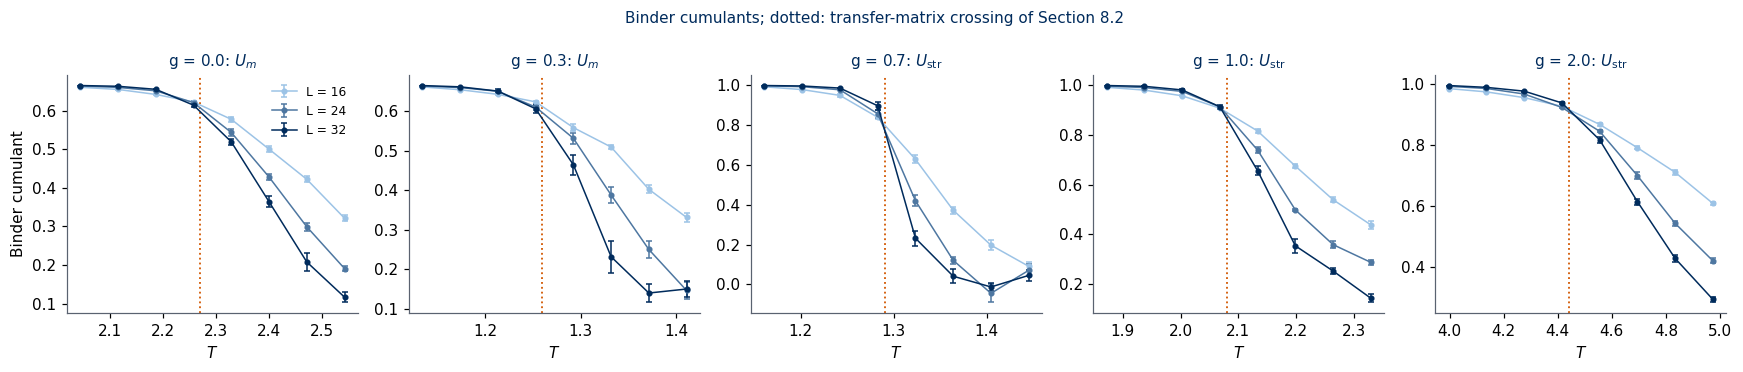

    g   U-crossing (16,24)  (24,32)   transfer matrix T*   mean field   T_wall = sigma_min/ln3
  0.0       2.2472        2.2124       2.2705           4.000       1.820
  0.3       1.2278        1.2168       1.2599           2.800       0.728
  0.7       1.2861        1.2900       1.2902           2.800       0.728
  1.0       2.0722        2.0682       2.0798           4.000       1.820
  2.0       4.3828        4.4638       4.4411           8.000       3.641
exact: T_c(0) = 2.2692;  large-g limit T_c/g -> 2.2692, here T_c(2)/2 from (24,32):  2.2319


In [30]:
fig, ax = plt.subplots(1, len(g_mc), figsize=(16, 3.4))
Tc_mc = {}
for a, gv in zip(ax, g_mc):
    T = T_win[gv]
    for i, L in enumerate(L_mc):
        U, dU = U_mc[(gv, L)]
        a.errorbar(T, U, dU, fmt="o-", ms=3, lw=1, capsize=2, color=blues(i / (len(L_mc) - 1)), label=f"L = {L}")
    Tc_mc[gv] = [crossing_T(T, U_mc[(gv, La)][0], U_mc[(gv, Lb)][0], T_ref[gv]) for La, Lb in zip(L_mc[:-1], L_mc[1:])]
    a.axvline(T_ref[gv], color=DSOrange, ls=":", lw=1.2)
    a.set_title(f"g = {gv}: " + ("$U_m$" if gv < 0.5 else r"$U_{\rm str}$"), fontsize=10); a.set_xlabel("$T$")
ax[0].set_ylabel("Binder cumulant"); ax[0].legend(frameon=False, fontsize=8)
fig.suptitle("Binder cumulants; dotted: transfer-matrix crossing of Section 8.2", color=UJNavy, fontsize=10)
plt.tight_layout(); plt.show()

fmt = lambda v: f"{v:7.4f}" if v is not None else "   none"
print("    g   U-crossing (16,24)  (24,32)   transfer matrix T*   mean field   T_wall = sigma_min/ln3")
for gv in g_mc:
    s_min = 2 * (1 - 2 * gv) if gv < 0.5 else min(2 * (2 * gv - 1), 2 * gv)
    print(f"  {gv:3.1f}      {fmt(Tc_mc[gv][0])}       {fmt(Tc_mc[gv][1])}      {T_ref[gv]:7.4f}          {max(4*(1-gv), 4*gv):6.3f}      {s_min/np.log(3):6.3f}")
print(f"exact: T_c(0) = {TC_ISING:.4f};  large-g limit T_c/g -> {TC_ISING:.4f}, here T_c(2)/2 from (24,32): {fmt(Tc_mc[2.0][1] / 2 if Tc_mc[2.0][1] else None)}")

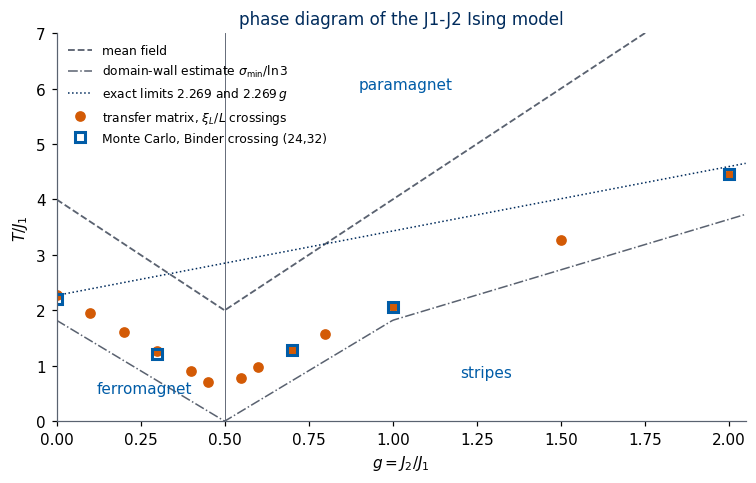

In [31]:
# the phase diagram assembled from all methods of this notebook
fig, ax = plt.subplots(figsize=(7, 4.5))
gl = np.linspace(0, 2.05, 400)
ax.plot(gl[gl <= 0.5], 4 * (1 - gl[gl <= 0.5]), "--", color=UJGray, lw=1.2, label="mean field")
ax.plot(gl[gl >= 0.5], 4 * gl[gl >= 0.5], "--", color=UJGray, lw=1.2)
s_min = np.where(gl < 0.5, 2 * (1 - 2 * gl), np.minimum(2 * (2 * gl - 1), 2 * gl))
ax.plot(gl, s_min / np.log(3), "-.", color=UJGray, lw=1, label=r"domain-wall estimate $\sigma_{\min}/\ln 3$")
ax.plot([0, 2.05], [TC_ISING, 2.05 * TC_ISING], ":", color=UJNavy, lw=1, label=r"exact limits $2.269$ and $2.269\,g$")
gx = [gv for gv in g_cross if gv <= 2.05 and Tstar[(gv, 8)] is not None]
ax.plot(gx, [Tstar.get((gv, 10)) or Tstar[(gv, 8)] for gv in gx], "o", color=DSOrange, ms=6, label=r"transfer matrix, $\xi_L/L$ crossings")
gm = [gv for gv in g_mc if Tc_mc[gv][1] is not None]
ax.plot(gm, [Tc_mc[gv][1] for gv in gm], "s", color=UJBlue, ms=7, mfc="none", mew=2, label="Monte Carlo, Binder crossing (24,32)")
ax.axvline(0.5, color=UJGray, lw=0.6)
ax.text(0.12, 0.5, "ferromagnet", color=UJBlue); ax.text(1.2, 0.8, "stripes", color=UJBlue); ax.text(0.9, 6.0, "paramagnet", color=UJBlue)
ax.set_xlabel("$g=J_2/J_1$"); ax.set_ylabel("$T/J_1$"); ax.set_ylim(0, 7); ax.set_xlim(0, 2.05); ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.set_title("phase diagram of the J1-J2 Ising model")
plt.tight_layout(); plt.show()

In the figure the cumulant curves of the three sizes cross, and the table lists the crossing temperatures next to the other estimates. The Binder crossings for $L=16,24,32$ agree with the transfer-matrix crossings to within a few per cent; the largest deviations
($g=0$ and $g=0.3$, crossings below the exact or transfer-matrix values) and the spread between the $(16,24)$ and $(24,32)$ crossings show the statistical and equilibration limits of local Metropolis
updates with 16 chains per point (Lab 018 discusses critical slowing down). At $g=2$ the crossing gives $T_c/g$ close to the large-$g$ limit $2.269$. Mean field overestimates $T_c$ by about a factor of two;
the domain-wall estimate lies below the computed line and vanishes at $g=1/2$, where the true transition temperature drops. Locating $T_c(g)$ very close to $g=1/2$, and deciding the order of the stripe transition, requires larger lattices and specialised methods — Section 10.

<hr/>
## 10. First-order and continuous transitions

Our calculations locate the transition line but cannot decide its *nature* close to $g=1/2$: that needs lattices far larger than ours, histogram analysis and
dedicated methods. The model has a long history of conflicting answers, which makes it a good benchmark — and a warning that small-lattice data can mislead. In what follows, each statement is
attributed to the paper that makes it. Some papers take the nearest-neighbour coupling antiferromagnetic, others write the ferromagnetic one as $J_1<0$; by the checkerboard
gauge of Section 2 all these results apply to our model with $g=|J_2/J_1|$ (an antiferromagnetic $J_1$ turns our ferromagnet into a Néel state).

On the ferromagnetic side, $g<1/2$, the order parameter is a scalar with $\mathbb Z_2$ symmetry. Kalz, Honecker, Fuchs and Pruschke [2008] find a transition in the two-dimensional Ising universality class
(for example $\nu=0.99(1)$ at $g=0.3$, against the Ising value $\nu=1$), and a transition temperature consistent with $T_c\to0$ at $g=1/2$.

On the stripe side, $g>1/2$, the literature records a long debate. Early Monte Carlo work [Landau & Binder 1985, among others] was interpreted as a continuous transition with non-universal (continuously varying) exponents (as summarised by Kalz et al. [2008]).
Kalz et al. [2008] then observed a double-peaked energy histogram at $g=0.6$, the signature of a first-order transition (coexistence of the ordered and disordered phases), and concluded
that the transition is weakly first order for moderate $g>1/2$. Kalz, Honecker and Moliner [2011] found doubly peaked histograms for $1/2<g\lesssim1$ and, by perturbation theory around the two decoupled
critical Ising models at $J_1=0$ (our Section 5.2), derived the Ashkin–Teller model as the effective theory.

Jin, Sen and Sandvik [2012] reached a different picture. They showed that for $g\ge g^*$ the transition is continuous with Ashkin–Teller exponents that vary continuously from those of the
4-state Potts model at $g=g^*$ to those of the Ising model for $g\to\infty$, with $g^*=0.67(1)$; the transition is first order for $1/2<g<g^*$, and *pseudo-first-order* for $g^*<g<1$: on finite lattices a
continuous transition near the Potts point shows first-order-like features such as double-peaked histograms. Jin, Sen, Guo and Sandvik [2013] extended this with cluster mean-field theory, Monte Carlo
and transfer matrices: a line of very weak first-order transitions for $1/2<g<g^*$, and continuous transitions above $g^*$ that map onto the critical line of the Ashkin–Teller model from its 4-state Potts
point to the decoupled-Ising limit. Finally, Li and Yang [2021] used tensor networks and found that if a first-order region exists, it is smaller than in the earlier studies; their analysis suggests that the model evolves continuously from two decoupled Ising
models (central charge $c=1$) to a point in the tricritical Ising class ($c=0.7$) at $g^*\simeq0.54$.

These results connect directly with this notebook. The Ashkin–Teller structure is the $D_4$ symmetry of the stripe order parameter (Section 2.1) and the two sublattice magnetisations of the $g\to\infty$ limit (Section 5.2).
The difficulty of the problem near $g=1/2$ — tiny energy scales (Section 4), a degenerate manifold (Section 3.5), first-order or pseudo-first-order behaviour — is what makes the model a demanding
test for the unsupervised methods of Labs 019–020.

The results of this notebook and the literature above combine into the phase diagram drawn below. A phase diagram is a map of the control parameters, here the coupling ratio $g=J_2/J_1$ and the temperature $T/J_1$, divided into regions with qualitatively different behaviour, the phases, and the lines between them, the phase transitions. The type of a transition is read off from the free energy per spin $f$ and its derivatives. At a **first-order** transition a first derivative of $f$, such as the energy or the order parameter, jumps, and the two phases coexist at the transition temperature; on a finite lattice this shows up as an energy histogram with two peaks, the observation of Kalz et al. [2008]. At a **continuous** transition the first derivatives are continuous, the order parameter goes to zero continuously, and the correlation length diverges as a power of $|T-T_c|$ with critical exponents shared by a whole universality class.

The orange dots are the transfer-matrix crossings of Section 8.2 and the blue squares the Monte Carlo Binder crossings of Section 9; the solid lines through them are only a guide to the eye. Three statements are exact and placed exactly: $T_c=2/\ln(1+\sqrt2)=2.269\,J_1$ at $g=0$ (Onsager), the asymptote $T_c\to2.269\,g\,J_1$ for $g\to\infty$ (two decoupled Ising lattices, Section 5.2), and $T_c\to0$ at $g=1/2$, where domain walls cost nothing (Section 4) and where Kalz et al. [2008] find their data consistent with a vanishing transition temperature; the dashed segments connect the computed points to this limit. Below the line on the left the ferromagnet has $m\neq0$; below the line on the right the stripe phase has $m_{\rm str}\neq0$; above both lies the paramagnet. On the ferromagnetic side the transition is continuous and in the two-dimensional Ising universality class [Kalz et al. 2008]. On the stripe side, for $g$ well above $1/2$, it is continuous with exponents that vary along the line, those of the Ashkin–Teller model introduced in Section 2.1 [Jin, Sen & Sandvik 2012]. Close to $g=1/2$ (hatched band, $1/2<g\lesssim0.7$) its nature is debated: first order according to Kalz et al. [2008, 2011] and Jin et al. [2012, 2013], who place the end of the first-order region at $g^*=0.67(1)$, while Li and Yang [2021] find at most a much smaller first-order region.

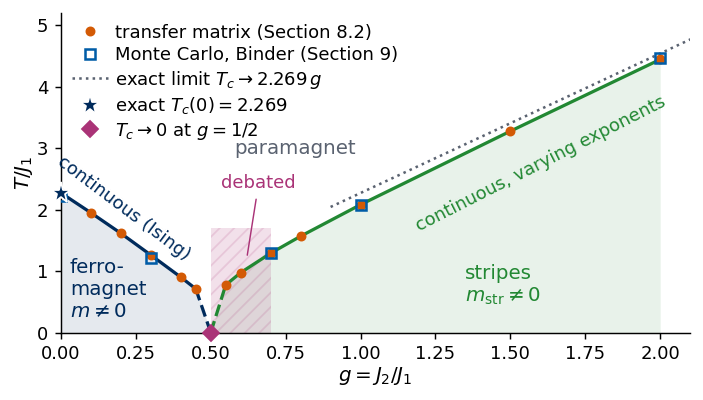

In [ ]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("figures", exist_ok=True)
    for d in ("figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def sketch_j1j2_phase_diagram():
    Tc = 2.0 / np.log(1.0 + np.sqrt(2.0))                          # Onsager's T_c (g = 0) and the large-g slope
    # transition temperatures computed in this notebook (Section 8.2: transfer-matrix crossings, widest pair available;
    # Section 9: Monte Carlo Binder-cumulant crossings of L = 24 and 32)
    g_tm = np.array([0.0, 0.1, 0.2, 0.3, 0.4, 0.45, 0.55, 0.6, 0.7, 0.8, 1.0, 1.5, 2.0])
    T_tm = np.array([2.2705, 1.9477, 1.6137, 1.2599, 0.9005, 0.7109, 0.7741, 0.9742, 1.2902, 1.5667, 2.0798, 3.2745, 4.4411])
    g_mc = np.array([0.0, 0.3, 0.7, 1.0, 2.0]); T_mc = np.array([2.2124, 1.2168, 1.2900, 2.0682, 4.4638])

    fig, ax = plt.subplots(figsize=(5.5, 3.0))
    fig.subplots_adjust(left=0.1, right=0.98, bottom=0.15, top=0.97)
    # guide to the eye through the transfer-matrix points; dashed where it is extrapolated to T_c = 0 at g = 1/2
    gl, gr = g_tm[g_tm < 0.5], g_tm[g_tm > 0.5]
    ax.fill_between(np.r_[gl, 0.5], np.r_[T_tm[g_tm < 0.5], 0], color=NAVY, alpha=0.10, lw=0)
    ax.fill_between(np.r_[0.5, gr], np.r_[0, T_tm[g_tm > 0.5]], color=GREEN, alpha=0.10, lw=0)
    ax.plot(gl, T_tm[g_tm < 0.5], color=NAVY, lw=1.8); ax.plot([0.45, 0.5], [T_tm[5], 0], color=NAVY, lw=1.8, ls="--")
    ax.plot(gr, T_tm[g_tm > 0.5], color=GREEN, lw=1.8); ax.plot([0.5, 0.55], [0, T_tm[6]], color=GREEN, lw=1.8, ls="--")
    # region where the nature of the stripe transition is debated (Section 10)
    ax.fill_between([0.5, 0.7], 0, 1.7, color=PURPLE, alpha=0.15, lw=0, hatch="///")
    ax.plot(g_tm, T_tm, "o", ms=4.5, color=ORANGE, label="transfer matrix (Section 8.2)", zorder=5)
    ax.plot(g_mc, T_mc, "s", ms=6, mfc="none", mec=BLUE, mew=1.4, label="Monte Carlo, Binder (Section 9)", zorder=5)
    # exact statements
    gg = np.linspace(0.9, 2.2, 50)
    ax.plot(gg, Tc * gg, ":", color=GRAY, lw=1.4, label=r"exact limit $T_c\to2.269\,g$")
    ax.plot(0, Tc, "*", ms=12, color=NAVY, mec="white", zorder=6, clip_on=False, label=r"exact $T_c(0)=2.269$")
    ax.plot(0.5, 0, "D", ms=6, color=PURPLE, zorder=6, clip_on=False, label=r"$T_c\to0$ at $g=1/2$")
    # phases, order parameters and transition types
    ax.text(0.03, 0.25, "ferro-\nmagnet\n$m\\neq0$", fontsize=11, color=NAVY)
    ax.text(1.35, 0.5, "stripes\n$m_{\\rm str}\\neq0$", fontsize=11, color=GREEN)
    ax.text(0.78, 2.85, "paramagnet", fontsize=11, color=GRAY, ha="center", va="bottom")
    ax.text(0.21, 2.02, "continuous (Ising)", fontsize=10, color=NAVY, rotation=-37, ha="center", va="center")
    ax.text(1.6, 2.75, "continuous, varying exponents", fontsize=10, color=GREEN, rotation=27, ha="center", va="center")
    ax.annotate("debated", xy=(0.62, 1.2), xytext=(0.66, 2.35), fontsize=10, color=PURPLE, ha="center",
                arrowprops=dict(arrowstyle="-", color=PURPLE, lw=0.8))
    ax.set_xlim(0, 2.1); ax.set_ylim(0, 5.2)
    ax.set_xlabel("$g=J_2/J_1$", labelpad=1); ax.set_ylabel("$T/J_1$", labelpad=1)
    ax.legend(loc="upper left", fontsize=10, frameon=False, borderaxespad=0.2, handletextpad=0.4, labelspacing=0.25)
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_j1j2_phase_diagram()
save_sketch(fig, "sketch_j1j2_phases.png")
plt.show()


<hr/>
## 11. Summary

The table collects the statements of this notebook and the sections where they are derived and checked.

| statement | where derived and checked |
|---|---|
| frustration: on a loop with negative product of coupling signs at least one bond is broken | Section 1.1 (SymPy, enumeration) |
| symmetries: $\mathbb Z_2$ flip and lattice symmetries; $J_1\to-J_1$ by the checkerboard gauge | Section 2 |
| stripe order parameter $(m_x,m_y)$ transforms under $D_4$ (8 elements), as in the Ashkin–Teller model | Section 2.1 |
| $E_0/N=\min(-2J_1+2J_2,\,-2J_2)$, proved by the plaquette bound; level crossing at $g=1/2$ | Section 3 (SymPy, $4\times4$ enumeration, (min,+) transfer matrix up to $8\times8$) |
| ground-state degeneracy at $g=1/2$: $2^L+2^M-2$ on an $L\times M$ torus | Section 3.5 (derivation, transfer-matrix count up to $10\times10$) |
| domain-wall energies $2J_1(1-2g)$ (ferromagnet), $2J_1(2g-1)$, $2J_2$, $2J_1+4J_2$ (stripes); the cheapest vanishes at $g=1/2$ | Section 4 (SymPy, constructed walls) |
| $T_c(0)=2/\ln(1+\sqrt2)$; $T_c/J_2\to2/\ln(1+\sqrt2)$ for $g\to\infty$ (two decoupled sublattices, gauge to ferromagnet) | Section 5 (SymPy, exact $Z=Z_{\mathcal A}Z_{\mathcal B}$ on $4\times4$) |
| mean field: $T_{\rm MF}=\max_{\boldsymbol k}\mathcal J(\boldsymbol k)=\max(4J_1-4J_2,\,4J_2)$, $m\propto(T_{\rm MF}-T)^{1/2}$; line degeneracy at $g=1/2$ | Section 6 (SymPy, eigenvalues, iteration) |
| $S(\boldsymbol k)$: Bragg peaks at $(0,0)$ or $(\pi,0)/(0,\pi)$; lines $k_x=0$, $k_y=0$ at $g=1/2$; sum rule $\overline{S}=1$ | Section 7 (Monte Carlo) |
| residual entropy $\ln2/L$ per spin of a strip at $g=1/2$; $T_c(g)$ from $\xi_L/L$ crossings | Section 8 (exact strips, $L\le12$) |
| $T_c(g)$ from Binder cumulants, $L=16,24,32$, compared with transfer matrices and mean field | Section 9 (JAX Monte Carlo) |
| weakly first order for $1/2<g<g^*$, Ashkin–Teller criticality for $g>g^*$, $g^*$ debated ($0.67$ vs $0.54$) | Section 10 (literature) |

The last cell prints the total running time of the notebook.

In [32]:
print(f"total running time of the notebook: {(time.perf_counter() - T_START) / 60:.1f} min")

total running time of the notebook: 13.5 min


<hr/>
## Exercises

### Exercise 1 — single spin flips and mean field
Compute, symbolically and numerically, the energy cost $\Delta E$ of flipping a single spin in the ferromagnetic ground state and in the stripe ground state as a function of $J_1,J_2$. Compare with
$T_{\rm MF}$ of Section 6 and explain the relation using $\Delta E_i=2s_ih_i$.

#### Solution

In [33]:
L = 8; x, y = np.meshgrid(np.arange(L), np.arange(L), indexing="ij")
for name, s0 in {"ferromagnet": np.ones((L, L), int), "stripes": (-1) ** x}.items():
    s1 = s0.copy(); s1[3, 3] *= -1                                        # flip one spin
    b0, b1 = bond_sums(s0), bond_sums(s1)
    dE = sp.expand(-J1s * (b1[0] + b1[1] - b0[0] - b0[1]) + J2s * (b1[2] - b0[2]))
    print(f"{name:11s}: Delta E = {dE}   (numerical at g = 0.3: {energy(s1, 0.3) - energy(s0, 0.3):+.2f})")

ferromagnet: Delta E = 8*J_1 - 8*J_2   (numerical at g = 0.3: +5.60)
stripes    : Delta E = 8*J_2   (numerical at g = 0.3: +2.40)


$\Delta E_{\rm FM}=8J_1-8J_2=2\cdot4(J_1-J_2)$ and $\Delta E_{\rm str}=8J_2=2\cdot4J_2$: in both cases $\Delta E=2T_{\rm MF}$. The reason: $\Delta E_i=2s_ih_i$, and in the perfectly ordered state the
local field is $|h_i|=\mathcal J(\boldsymbol Q)$, which is also $T_{\rm MF}$. Mean field treats the ordered state as a collection of independent spins in this field. Note that a single flip costs $8|J_1-J_2|$ or $8J_2$,
which does **not** vanish at $g=1/2$ ($4J_1$): the soft excitations at $g=1/2$ are extended domain walls, not single spins (Section 4).

### Exercise 2 — odd lattice sizes
Use `minplus_torus` to compute $E_0/N$ and the degeneracy on $4\times5$ and $5\times5$ tori at $g=0.75$ and $g=0.5$. Explain the results.

#### Solution

In [34]:
for L, M in [(4, 5), (5, 5)]:
    for gv in (0.75, 0.5):
        e0, n0 = minplus_torus(L, M, gv)
        print(f"{L} x {M}, g = {gv}:  E0/N = {e0:+.4f}  (bulk value {min(-2 + 2*gv, -2*gv):+.4f}),  n0 = {n0}  (2^L + 2^M - 2 = {2**L + 2**M - 2})")

4 x 5, g = 0.75:  E0/N = -1.5000  (bulk value -1.5000),  n0 = 2  (2^L + 2^M - 2 = 46)
4 x 5, g = 0.5:  E0/N = -1.0000  (bulk value -1.0000),  n0 = 46  (2^L + 2^M - 2 = 46)
5 x 5, g = 0.75:  E0/N = -1.3000  (bulk value -1.5000),  n0 = 20  (2^L + 2^M - 2 = 62)
5 x 5, g = 0.5:  E0/N = -1.0000  (bulk value -1.0000),  n0 = 62  (2^L + 2^M - 2 = 62)


At $g=0.75$ stripes need an even period. On $4\times5$ only the stripes that alternate along the even direction fit: the degeneracy drops from 4 to 2, the energy is unchanged.
On $5\times5$ no stripe state fits, and the ground state must contain a domain wall. The cheapest is one parallel (phase-slip) wall of length 5, energy $5\,\sigma_\parallel=5\cdot2(2g-1)=5$
at $g=0.75$, i.e. $0.2$ per spin above $-2g$ — exactly the printed difference. Its degeneracy is $2$ orientations $\times$ $5$ positions $\times$ $2$ signs $=20$. At $g=1/2$ the derivation of Section 3.5 never used
the parity of $L$ or $M$, and the count $2^L+2^M-2$ holds for odd sizes as well. Choosing even $L$ in simulations of this model is not a detail.

### Exercise 3 — Binder cumulant limits by sampling
Draw $10^6$ samples of (a) a Gaussian scalar, (b) a scalar $\pm1$, (c) a two-dimensional Gaussian vector, (d) a two-dimensional vector of length 1 pointing to one of the four directions
$(\pm1,0),(0,\pm1)$. Evaluate $U_m$ for (a), (b) and $U_{\rm str}$ for (c), (d), and compare with the limits of Section 9.

#### Solution

In [35]:
rng = np.random.default_rng(7); n = 10**6
U1 = lambda q: 1 - (q**4).mean() / (3 * (q**2).mean()**2)
U2 = lambda q: 2 - (q**4).mean() / (q**2).mean()**2
a = rng.standard_normal(n); b = rng.choice([-1.0, 1.0], n)
c = np.hypot(rng.standard_normal(n), rng.standard_normal(n))
d = np.ones(n)                                                         # |(+-1, 0)| = |(0, +-1)| = 1
print(f"(a) Gaussian scalar: U_m = {U1(a):+.4f} (expected 0);   (b) +-1: U_m = {U1(b):.4f} (expected 2/3 = {2/3:.4f})")
print(f"(c) 2D Gaussian: U_str = {U2(c):+.4f} (expected 0);   (d) four stripe states: U_str = {U2(d):.4f} (expected 1)")

(a) Gaussian scalar: U_m = +0.0002 (expected 0);   (b) +-1: U_m = 0.6667 (expected 2/3 = 0.6667)
(c) 2D Gaussian: U_str = +0.0006 (expected 0);   (d) four stripe states: U_str = 1.0000 (expected 1)


The finite-sample values deviate from the limits by $O(n^{-1/2})$. In a simulation the distribution at $T_c$ is neither Gaussian nor two delta peaks, and the cumulant takes an intermediate,
universal value that depends on the universality class and on the boundary conditions.

<hr/>
## References

**Papers**
* L. Onsager, *Crystal statistics. I. A two-dimensional model with an order-disorder transition*, Phys. Rev. **65**, 117 (1944), [doi:10.1103/PhysRev.65.117](https://doi.org/10.1103/PhysRev.65.117)
* R. Peierls, *On Ising's model of ferromagnetism*, Math. Proc. Cambridge Philos. Soc. **32**, 477 (1936), [doi:10.1017/S0305004100019174](https://doi.org/10.1017/S0305004100019174)
* R. B. Griffiths, *Peierls proof of spontaneous magnetization in a two-dimensional Ising ferromagnet*, Phys. Rev. **136**, A437 (1964), [doi:10.1103/PhysRev.136.A437](https://doi.org/10.1103/PhysRev.136.A437)
* J. Ashkin, E. Teller, *Statistics of two-dimensional lattices with four components*, Phys. Rev. **64**, 178 (1943), [doi:10.1103/PhysRev.64.178](https://doi.org/10.1103/PhysRev.64.178)
* K. Binder, *Finite size scaling analysis of Ising model block distribution functions*, Z. Phys. B **43**, 119 (1981), [doi:10.1007/BF01293604](https://doi.org/10.1007/BF01293604)
* D. P. Landau, K. Binder, *Phase diagrams and critical behavior of Ising square lattices with nearest-, next-nearest-, and third-nearest-neighbor couplings*, Phys. Rev. B **31**, 5946 (1985), [doi:10.1103/PhysRevB.31.5946](https://doi.org/10.1103/PhysRevB.31.5946)
* A. Kalz, A. Honecker, S. Fuchs, T. Pruschke, *Phase diagram of the Ising square lattice with competing interactions*, Eur. Phys. J. B **65**, 533 (2008), [doi:10.1140/epjb/e2008-00359-6](https://doi.org/10.1140/epjb/e2008-00359-6), [arXiv:0805.0983](https://arxiv.org/abs/0805.0983)
* A. Kalz, A. Honecker, M. Moliner, *Analysis of the phase transition for the Ising model on the frustrated square lattice*, Phys. Rev. B **84**, 174407 (2011), [doi:10.1103/PhysRevB.84.174407](https://doi.org/10.1103/PhysRevB.84.174407), [arXiv:1105.4836](https://arxiv.org/abs/1105.4836)
* S. Jin, A. Sen, A. W. Sandvik, *Ashkin-Teller criticality and pseudo-first-order behavior in a frustrated Ising model on the square lattice*, Phys. Rev. Lett. **108**, 045702 (2012), [doi:10.1103/PhysRevLett.108.045702](https://doi.org/10.1103/PhysRevLett.108.045702), [arXiv:1110.5874](https://arxiv.org/abs/1110.5874)
* S. Jin, A. Sen, W. Guo, A. W. Sandvik, *Phase transitions in the frustrated Ising model on the square lattice*, Phys. Rev. B **87**, 144406 (2013), [doi:10.1103/PhysRevB.87.144406](https://doi.org/10.1103/PhysRevB.87.144406), [arXiv:1212.5339](https://arxiv.org/abs/1212.5339)
* H. Li, L.-P. Yang, *Tensor network simulation for the frustrated $J_1$–$J_2$ Ising model on the square lattice*, Phys. Rev. E **104**, 024118 (2021), [doi:10.1103/PhysRevE.104.024118](https://doi.org/10.1103/PhysRevE.104.024118), [arXiv:2103.09464](https://arxiv.org/abs/2103.09464)

**Textbooks**
* J. M. Yeomans, *Statistical Mechanics of Phase Transitions*, Oxford University Press (1992), ISBN 978-0-19-851730-6 — mean-field theory, transfer matrices, finite-size scaling at an introductory level.
* R. J. Baxter, *Exactly Solved Models in Statistical Mechanics*, Dover (2007; first edition Academic Press 1982), ISBN 978-0-486-46271-4 — transfer matrices and exact solutions.
* M. Kardar, *Statistical Physics of Fields*, Cambridge University Press (2007), [doi:10.1017/CBO9780511815881](https://doi.org/10.1017/CBO9780511815881) — Landau theory, fluctuations, universality.
* P. M. Chaikin, T. C. Lubensky, *Principles of Condensed Matter Physics*, Cambridge University Press (1995), [doi:10.1017/CBO9780511813467](https://doi.org/10.1017/CBO9780511813467) — order parameters, symmetry breaking, mean-field theory, structure factors.
* M. E. J. Newman, G. T. Barkema, *Monte Carlo Methods in Statistical Physics*, Oxford University Press (1999), [doi:10.1093/oso/9780198517962.001.0001](https://doi.org/10.1093/oso/9780198517962.001.0001) — Metropolis algorithm, equilibration, error analysis.
* D. P. Landau, K. Binder, *A Guide to Monte Carlo Simulations in Statistical Physics*, 4th ed., Cambridge University Press (2014), [doi:10.1017/CBO9781139696463](https://doi.org/10.1017/CBO9781139696463) — Binder cumulants and finite-size scaling.
* C. Lacroix, P. Mendels, F. Mila (eds.), *Introduction to Frustrated Magnetism*, Springer (2011), [doi:10.1007/978-3-642-10589-0](https://doi.org/10.1007/978-3-642-10589-0) — frustration in classical and quantum magnets.
* H. T. Diep (ed.), *Frustrated Spin Systems*, 2nd ed., World Scientific (2012), [doi:10.1142/8676](https://doi.org/10.1142/8676) — frustrated Ising and vector spin models.